# 104_04 — Evaluación con cuatro predictores, tres intervalos y comportamientos · Santiago (Parque O'Higgins) horario · PM2.5 (log) · rezago 1 cruzado · $M = 1..6$

La 104 es la 28 (`real_pm25_poh_v02`, copiada a `real_pm25_104_v02` con `00_copiar_28.py`; trazas de la 28) reevaluada con el pipeline de las 30x: el PM2.5 horario de la estación Parque O'Higgins (SINCA), curva $\log(1 + \mathrm{PM2.5})$, 24 puntos por día; 2015-2022 entrena y 2023-2025 prueba. Sus §1–§10 con la esperanza y la equi-colas deben reproducir la 28 al bit.


## 1. Imports, `[CONFIG]` y artefactos

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from model_psbp_fd.fit.convergencia_barrido import (
    cargar_artefactos, cargar_trazas, pip_punto,
)
from model_psbp_fd.fit.evaluacion_barrido import (
    METRICAS_A as _MA, METRICAS_B as _MB,
    cargar_representaciones, serie_origenes, predecir_barrido, guardar_bandas,
    tablas_ventana, apilar_tablas, verificar_relaciones_metricas,
    ganancias_por_ventana, tabla_ganadores_test, saltos_T0, peores_ventanas,
    resumen_metricas, resumen_barrido, monitoreo_scores, intervalos_scores,
    tabla_predictores, curvas_draws, diagnostico_multimodalidad,
    INTERVALOS as INTERVALOS_TODOS, tabla_intervalos, filtrar_ventana,
)
from model_psbp_fd.fit.resumenes_predictiva import PREDICTORES as PREDICTORES_TODOS
from model_psbp_fd.fit.comparacion_barrido import ganadores_por_ventana
from model_psbp_fd.fit.comportamientos import comportamientos_barrido, catalogo_barrido
from model_psbp_fd.graphics import (
    plot_ventana_movil, plot_extractos_curvas,
    plot_ganador_ventana, plot_scores_banda, plot_scores_dispersion,
    plot_predictores_vs_M, plot_histogramas_draws, plot_curvas_predictores,
    plot_comportamientos, plot_K_barrido, plot_K_serie, plot_catalogo,
)
from model_psbp_fd.graphics.viz_evaluacion_barrido import (
    plot_ventana_grupos_por_M, plot_ganador_grupo_vs_M,
)
from model_psbp_fd.graphics import ESTILOS_PREDICTORES
from model_psbp_fd.utils import get_project_root, experiment_id, normalizar_lista_M
from model_psbp_fd.utils.rutas import ruta_barrido_M

import json

from model_psbp_fd.fit.intervalos_predictiva import ancho_tramos, cobertura_tramos
from model_psbp_fd.fit.metrics_puntual import normas_error_por_origen, pesos_normalizados
from model_psbp_fd.fit.resumenes_predictiva import distancia_a_muestra_mas_cercana

plt.style.use("seaborn-v0_8-darkgrid")
%matplotlib inline

### 1.1 `[CONFIG]` Identificación del experimento y barrido en $M$

In [2]:
PROJECT_ROOT = get_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Identidad de la corrida: mismos valores que 104_01 §1.1. El ID es
# real_<serie>_v<NN>_m<NN>; las funciones de fit/ lo arman con (BASE_LIB, ESCENARIO_ID, None).
BASENAME, SERIE_ID, VENTANA_ID = "real", "pm25_104", 2   # ventana 2: entrena 2015-2022, prueba 2023-2025 (28_01 §1.1; artefactos copiados por 00_copiar_28.py)
M_FPCA_LIST = (1, 2, 3, 4, 5, 6)
DOMINIO      = "reales"
BASE_LIB     = f"{BASENAME}_{SERIE_ID}"
ESCENARIO_ID = f"v{VENTANA_ID:02d}"
REPLICA_ID   = None
# Episodios (§3.2, §12.4): un día supera la norma si su promedio de 24 h de PM2.5 es >= UMBRAL_NORMA_PM25
# µg/m³ (norma primaria diaria, DS 12/2011); X_obs = log(1 + PM2.5) (28_01 §2.1), horas ausentes = curva suavizada.
UMBRAL_NORMA_PM25 = 50.0   # µg/m³

# Propias de la evaluación. Las ventanas, el nivel y el objetivo se LEEN de
# eval_config.json (artefacto de 104_01): no se redeclaran aquí.
SALTAR_M_SIN_TRAZAS = True    # mirar el barrido mientras MATLAB va terminando
BURN_EVAL           = None    # iteraciones descartadas; None = el burn del .mat (500), como la 28 y las 30x.
PESOS_TAU           = None    # cuadratura trapezoidal por defecto
METRICA_PEORES      = "rmse_f"   # cualquiera de las columnas de METRICAS_A / METRICAS_B
N_PEORES            = 5

# Predicción a h=1 (§3). S = (nsim - burn) x S_POR_ITER x n_cadenas draws por score;
# subirlos sólo reduce el error Monte Carlo de los cuantiles.
S_POR_ITER  = 1
S_FUNC      = 1000      # muestras funcionales tras adelgazar
BLOQUE_ORIG = 200       # orígenes por tramo al propagar a la curva (memoria; G = 24)
SEED_PRED   = 20260823
CADA        = 30        # un extracto de curva cada CADA períodos (§6)
CADA_BARRA  = 12        # un origen de cada CADA_BARRA lleva barra de IC (§10.3)

# Predictores puntuales (docs 03_05_04) y comportamientos (03_06).
PREDICTORES    = PREDICTORES_TODOS    # esperanza, mediana, medoide, modal
INTERVALOS     = INTERVALOS_TODOS     # equicolas, simultanea, hdr (docs §03_05_05)
K_MAX_HDR      = 3                    # tramos por (t, tau) de la HDR
N_DETALLE      = 10                   # orígenes consecutivos de prueba para el análisis predictivo
T0_DETALLE     = None                 # None = criterio automático del escenario; un entero lo fija a mano
GUARDAR_DRAWS  = True                 # draws_scores_psbp.npy en predict/
UMBRAL_SEP     = 0.25                 # §11: |esperanza - mediana| > UMBRAL_SEP x sd robusta
N_REF_NN       = 100                  # §11: extracciones de referencia (distancia típica)
COMP_SOLO_TEST = False                # §12: también en train
M_DETALLE      = (1, 4, 6)            # figuras por origen sólo en estos M
N_EJEMPLOS     = 4

# §7: dispersión entre cadenas del PIP que se avisa (con 1 cadena no hay dispersión).
SD_PIP_MAX = 0.15

# Las 10 métricas del marco teórico 02_02_03, en su orden. No se agregan otras.
METRICAS_A = [("1. MAE  (L^1)", "mae_f"), ("2. RMSE (L^2)", "rmse_f"),
              ("3. E_max promedio por curva", "linf_medio"),
              ("4. E_max peor de la ventana", "linf_max")]
METRICAS_B = [("5. MPIW", "mpiw"), ("6. PICP puntual", "picp"),
              ("7. PICPB curva completa", "picp_simultaneo"), ("8. Winkler", "winkler"),
              ("9. Winkler max promedio", "winkler_max_medio"),
              ("10. Winkler max peor ventana", "winkler_max_glob")]
assert METRICAS_A == _MA and METRICAS_B == _MB, "METRICAS_* difieren de fit.evaluacion_barrido."
METRICAS_A_COLS = [c for _, c in METRICAS_A]
METRICAS_B_COLS = [c for _, c in METRICAS_B]

M_FPCA_LIST     = normalizar_lista_M(M_FPCA_LIST)
EXPERIMENT_BASE = experiment_id(BASE_LIB, ESCENARIO_ID, REPLICA_ID)
PATH_BARRIDO    = ruta_barrido_M(BASE_LIB, ESCENARIO_ID, REPLICA_ID, dominio=DOMINIO,
                                 project_root=PROJECT_ROOT)

print(f"EXPERIMENT_BASE : {EXPERIMENT_BASE}")
print(f"barrido en M    : {list(M_FPCA_LIST)}")
print(f"salidas cruzadas: {PATH_BARRIDO}")

EXPERIMENT_BASE : real_pm25_104_v02
barrido en M    : [1, 2, 3, 4, 5, 6]
salidas cruzadas: C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_pm25_104_v02_barrido_M


In [3]:
# EST[M]: estado de cada punto (cruza el contrato al cargar). DIS: diseño común.
EST, saltados = cargar_artefactos(BASE_LIB, ESCENARIO_ID, REPLICA_ID, M_FPCA_LIST,
                                  PROJECT_ROOT, con_test=True, dominio=DOMINIO)
DIS = cargar_representaciones(EST)

T, T0, N_LAGS, NIVEL = DIS["T"], DIS["T0"], DIS["N_LAGS"], DIS["NIVEL"]
VENTANAS_W, W_REF    = DIS["VENTANAS_W"], DIS["W_REF"]
grilla, X_obs, X_suav = DIS["grilla"], DIS["X_obs"], DIS["X_suav"]      # sin X_true: datos reales

  M  comp  cadenas  covariables  seed_base
  1     1        1            1  41232
  2     2        1            2  41232
  3     3        1            3  41232
  4     4        1            4  41232
  5     5        1            5  41232
  6     6        1            6  41232

OK misma configuracion MCMC en todos los M: nsim/N/burn/cadenas = (2500, 30, 500, 1)
M=1  FPCA M=1 K=10  var. explicada=76.6746%  ·  curvas (4018, 24)
M=2  FPCA M=2 K=10  var. explicada=86.3636%  ·  curvas (4018, 24)
M=3  FPCA M=3 K=10  var. explicada=91.9030%  ·  curvas (4018, 24)
M=4  FPCA M=4 K=10  var. explicada=94.5849%  ·  curvas (4018, 24)


M=5  FPCA M=5 K=10  var. explicada=96.3528%  ·  curvas (4018, 24)
M=6  FPCA M=6 K=10  var. explicada=97.6541%  ·  curvas (4018, 24)

OK 6 puntos con el mismo diseno, objetivo, MCMC y simulacion.
T=4018 T0=2922 n_lags=1   ventanas w=[20, 30, 40]   referencia w=30   nivel=0.95


## 2. Trazas MCMC

Una lectura por punto del barrido; `feature_names` del `.mat` se cruza con el dataset.

In [4]:
M_OK = cargar_trazas(EST, SALTAR_M_SIN_TRAZAS, BURN_EVAL)     # los M efectivamente disponibles

OK M=1: 1 componente(s) x 1 cadena(s) · 2000 draws posteriores c/u -> 2000 por componente
OK M=2: 2 componente(s) x 1 cadena(s) · 2000 draws posteriores c/u -> 2000 por componente
OK M=3: 3 componente(s) x 1 cadena(s) · 2000 draws posteriores c/u -> 2000 por componente
OK M=4: 4 componente(s) x 1 cadena(s) · 2000 draws posteriores c/u -> 2000 por componente
OK M=5: 5 componente(s) x 1 cadena(s) · 2000 draws posteriores c/u -> 2000 por componente
OK M=6: 6 componente(s) x 1 cadena(s) · 2000 draws posteriores c/u -> 2000 por componente


## 3. Predicción a $h=1$ sobre la serie completa

Cuatro predictores (esperanza, mediana puntual, medoide $L^1$, átomo modal) y tres intervalos (equi-colas, simultánea, HDR) sobre las mismas extracciones.

In [5]:
ORIG = serie_origenes(DIS)
t_orig, n_orig, T0_orig, es_train = ORIG["t_orig"], ORIG["n_orig"], ORIG["T0_orig"], ORIG["es_train"]
X_obj_ev, X_obs_ev = ORIG["X_obj_ev"], ORIG["X_obs_ev"]

predecir_barrido(EST, M_OK, DIS, ORIG, S_POR_ITER, S_FUNC, BLOQUE_ORIG, SEED_PRED,
                 predictores=PREDICTORES, pesos_tau=PESOS_TAU,
                 intervalos=INTERVALOS, k_max_hdr=K_MAX_HDR)

# La HDR fusiona tramos cuando una (t, tau) da más de K_MAX_HDR: no debe pasar del 1 %.
for M in M_OK:
    print(f"M={M}: HDR con fusión de tramos en {EST[M]['hdr_fusiones']} (t, tau) "
          f"= {EST[M]['hdr_frac_fusiones']:.3%}")
assert max(EST[M]["hdr_frac_fusiones"] for M in M_OK) <= 0.01, "subir K_MAX_HDR y reportarlo"

origenes evaluados: 4017  (train 2921 · test 1096)
SC_draws de TODO el barrido: 675 MB en float32


M=1: HDR puntual (k_max=3, recorte None): (t, g) con 1/2/3... tramos 92.33% / 7.57% / 0.10% · fusiones en 0.00% de los (t, g)


M=1: S=2000 extracciones por score · funcionales 1000 (1 de cada 2) · SC_draws 32 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.111108   <- distancia del objetivo a su propia proyeccion en M


M=2: HDR puntual (k_max=3, recorte None): (t, g) con 1/2/3... tramos 98.81% / 1.19% / 0.01% · fusiones en 0.00% de los (t, g)


M=2: S=2000 extracciones por score · funcionales 1000 (1 de cada 2) · SC_draws 64 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.063310   <- distancia del objetivo a su propia proyeccion en M


...

M=4: S=2000 extracciones por score · funcionales 1000 (1 de cada 2) · SC_draws 129 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.026329   <- distancia del objetivo a su propia proyeccion en M


M=5: HDR puntual (k_max=3, recorte None): (t, g) con 1/2/3... tramos 99.27% / 0.72% / 0.00% · fusiones en 0.00% de los (t, g)


M=5: S=2000 extracciones por score · funcionales 1000 (1 de cada 2) · SC_draws 161 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.018158   <- distancia del objetivo a su propia proyeccion en M


M=6: HDR puntual (k_max=3, recorte None): (t, g) con 1/2/3... tramos 99.23% / 0.76% / 0.01% · fusiones en 0.00% de los (t, g)


M=6: S=2000 extracciones por score · funcionales 1000 (1 de cada 2) · SC_draws 193 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.012181   <- distancia del objetivo a su propia proyeccion en M
M=1: HDR con fusión de tramos en 0 (t, tau) = 0.000%
M=2: HDR con fusión de tramos en 0 (t, tau) = 0.000%
M=3: HDR con fusión de tramos en 0 (t, tau) = 0.000%
M=4: HDR con fusión de tramos en 0 (t, tau) = 0.000%
M=5: HDR con fusión de tramos en 0 (t, tau) = 0.000%
M=6: HDR con fusión de tramos en 0 (t, tau) = 0.000%


### 3.1 Persistencia

`banda_funcional_psbp.npz` (predictores e intervalos) y `draws_scores_psbp.npy` en `predict/`; los lee el `_05`.

In [6]:
guardar_bandas(EST, M_OK, DIS, ORIG, guardar_draws=GUARDAR_DRAWS)

[M=1] banda funcional -> banda_funcional_psbp.npz  (3.4 MB, (4017, 24))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']
        extracciones de scores -> draws_scores_psbp.npy (32 MB, (2000, 4017, 1))


[M=2] banda funcional -> banda_funcional_psbp.npz  (3.4 MB, (4017, 24))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']
        extracciones de scores -> draws_scores_psbp.npy (64 MB, (2000, 4017, 2))


[M=3] banda funcional -> banda_funcional_psbp.npz  (3.4 MB, (4017, 24))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (96 MB, (2000, 4017, 3))
[M=4] banda funcional -> banda_funcional_psbp.npz  (3.4 MB, (4017, 24))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (129 MB, (2000, 4017, 4))
[M=5] banda funcional -> banda_funcional_psbp.npz  (3.4 MB, (4017, 24))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (161 MB, (2000, 4017, 5))
[M=6] banda funcional -> banda_funcional_psbp.npz  (3.4 MB, (4017, 24))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (193 MB, (2000, 4017, 6))
Banda por CUANTILES de la predictiva muestral: no supone forma alguna.


### 3.2 Ventana de detalle

Las métricas de la ventana móvil (§4–§10) y el número de comportamientos (§12.1) se calculan
en toda la serie. El **análisis predictivo** —§6, §11, §12.2–§12.4 y, en el `_05`, §9 y
§10— va sobre `N_DETALLE` orígenes consecutivos de prueba, desde `T0_DETALLE`. Con `None`
se elige con un criterio calculado sobre lo observado, nunca sobre lo que el modelo predijo: **episodios**: la ventana de prueba con más días cuyo promedio observado de 24 h de PM2.5 supera la norma diaria (`UMBRAL_NORMA_PM25` µg/m³). Queda en `112_ventana_detalle.json`, que lee el `_05`. Con
10 orígenes, aciertos y coberturas son **descriptivos** y se reportan como cuentas.


In [7]:
# 104 (PM2.5): calendario y episodios de los días predichos. Día de la semana de dias.csv (28_01 §2) y
# episodio = promedio de 24 h de PM2.5 observado >= UMBRAL_NORMA_PM25 (norma diaria). Criterio automático: la
# ventana de N_DETALLE días de prueba con más días de episodio; en empate, la primera. Es el análogo real del
# máximo de h_t de la 301: el episodio de invierno es donde la varianza condicional debería dispararse.
DIAS = pd.to_datetime(pd.read_csv(EST[M_OK[0]]["paths"]["raw"] / "dias.csv")["dia"])
assert len(DIAS) == T, f"dias.csv trae {len(DIAS)} días y T = {T}"
MEDIDA  = np.expm1(X_obs).mean(axis=1)                                # (T,) promedio diario de PM2.5, µg/m³
EVENTO  = MEDIDA >= UMBRAL_NORMA_PM25                                  # (T,) día que supera la norma
NOMBRE_EVENTO, NOMBRE_MEDIDA = "episodio", "pm25_media"            # columnas en 65_* y 112_*
DESCR_EVENTO = f"día que supera la norma diaria (promedio de 24 h de PM2.5 >= {UMBRAL_NORMA_PM25:g} µg/m³)"
DIA_SEM   = DIAS.dt.day_name().str[:3].to_numpy()                       # (T,) Mon .. Sun
MES       = DIAS.dt.month.to_numpy()                                    # (T,) 1 .. 12
EVENTO_OR = EVENTO[t_orig - 1].astype(int)                              # el día PREDICHO de cada origen
i_test = np.flatnonzero(~es_train)
cand   = i_test[: len(i_test) - N_DETALLE + 1]
puntaje = np.array([EVENTO_OR[i:i + N_DETALLE].sum() for i in cand])
j = int(np.argmax(puntaje))                                             # empate: la primera
T0_DETALLE_AUTO = int(t_orig[cand[j]])
CRITERIO_DET    = f"{DESCR_EVENTO} entre los días predichos de la ventana, suma"
VALOR_DET       = float(puntaje[j])
VERDAD_DET = {"fecha": DIAS.dt.strftime("%Y-%m-%d").to_numpy()[t_orig - 1],
              "dia_semana": DIA_SEM[t_orig - 1], "mes": MES[t_orig - 1],
              NOMBRE_MEDIDA: MEDIDA[t_orig - 1],
              NOMBRE_EVENTO: EVENTO_OR, f"ayer_{NOMBRE_EVENTO}": EVENTO[t_orig - 2].astype(int)}
print(f"{DESCR_EVENTO}: {int(EVENTO.sum())} de {T} días (train {int(EVENTO[:T0].sum())}, test {int(EVENTO[T0:].sum())})")


día que supera la norma diaria (promedio de 24 h de PM2.5 >= 50 µg/m³): 387 de 4018 días (train 316, test 71)


In [8]:
if T0_DETALLE is None:
    T0_DET, CRITERIO, VALOR = T0_DETALLE_AUTO, CRITERIO_DET, VALOR_DET
else:
    T0_DET, CRITERIO, VALOR = int(T0_DETALLE), "fijado a mano en [CONFIG]", float("nan")
IDX_DET  = np.flatnonzero((t_orig >= T0_DET) & (t_orig < T0_DET + N_DETALLE))
assert len(IDX_DET) == N_DETALLE and not es_train[IDX_DET].any(), "la ventana de detalle debe caer en prueba"
MASK_DET = np.isin(np.arange(n_orig), IDX_DET)
T_DET    = t_orig[IDX_DET]
(PATH_BARRIDO / "112_ventana_detalle.json").write_text(json.dumps(
    {"t0": int(T0_DET), "n": int(N_DETALLE), "criterio": CRITERIO, "valor": VALOR},
    ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Ventana de detalle: t = {T0_DET}..{T0_DET + N_DETALLE - 1}   ·   {CRITERIO}: {VALOR:g}")

Ventana de detalle: t = 3474..3483   ·   día que supera la norma diaria (promedio de 24 h de PM2.5 >= 50 µg/m³) entre los días predichos de la ventana, suma: 8


## 4. Bloque A: error puntual sobre la ventana móvil

MAE, RMSE y error máximo del mismo error $e_t(\tau)$, una fila por ventana y predictor. Las figuras son de la esperanza; se calcula una vez en `tablas_fun`, la misma tabla del Bloque B.

[ventana_movil_funcional[w=30]] inicio (3988 pasos)


  1/3988 ( 0.0%) t=0.0s eta=4.5s  t=16 [train] mise=0.05348


  199/3988 ( 5.0%) t=0.0s eta=0.4s  t=214 [train] mise=0.3846


  398/3988 (10.0%) t=0.0s eta=0.3s  t=413 [train] mise=0.0869


  597/3988 (15.0%) t=0.1s eta=0.3s  t=612 [train] mise=0.1747


...

  3781/3988 (94.8%) t=0.4s eta=0.0s  t=3796 [test] mise=0.2393


  3980/3988 (99.8%) t=0.4s eta=0.0s  t=3995 [test] mise=0.1442


  3988/3988 (100.0%) t=0.4s eta=0.0s  t=4003 [test] mise=0.1232


[ventana_movil_funcional[w=30]] listo: 3988 pasos en 0.4s  29 ventanas cruzan T0


OK relaciones entre metricas verificadas en 6 puntos x 3 anchos (L1<=L2<=Linf, PICPB<=PICP, W<=Wmax_medio<=Wmax_glob)


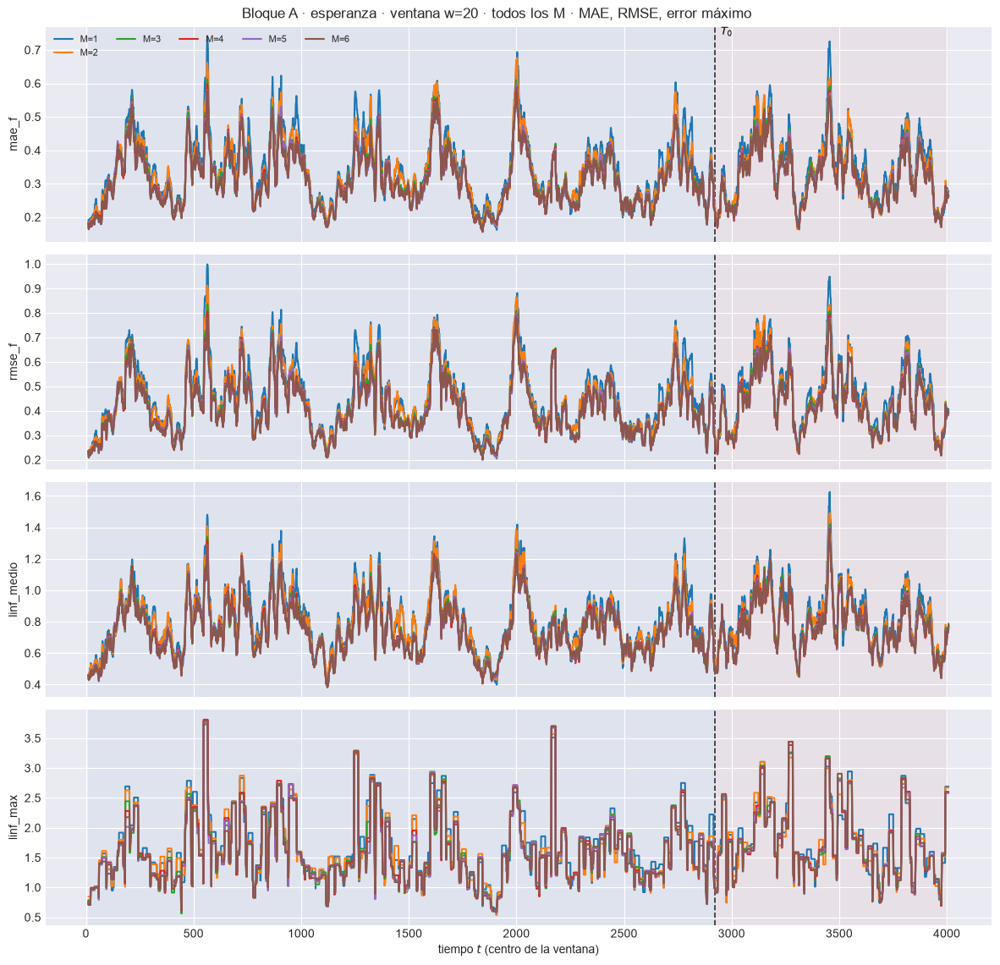

[plot_ventana_movil] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.1s  mae_f: w=30 train=0.3158  w=30 test=0.3305


  2/4 (50.0%) t=0.1s eta=0.1s  rmse_f: w=30 train=0.4121  w=30 test=0.438


  3/4 (75.0%) t=0.1s eta=0.0s  linf_medio: w=30 train=0.7568  w=30 test=0.7852


  4/4 (100.0%) t=0.1s eta=0.0s  linf_max: w=30 train=1.669  w=30 test=1.803


[plot_ventana_movil] listo: 4 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_pm25_104_v02_barrido_M\85_bloqueA_w30.png


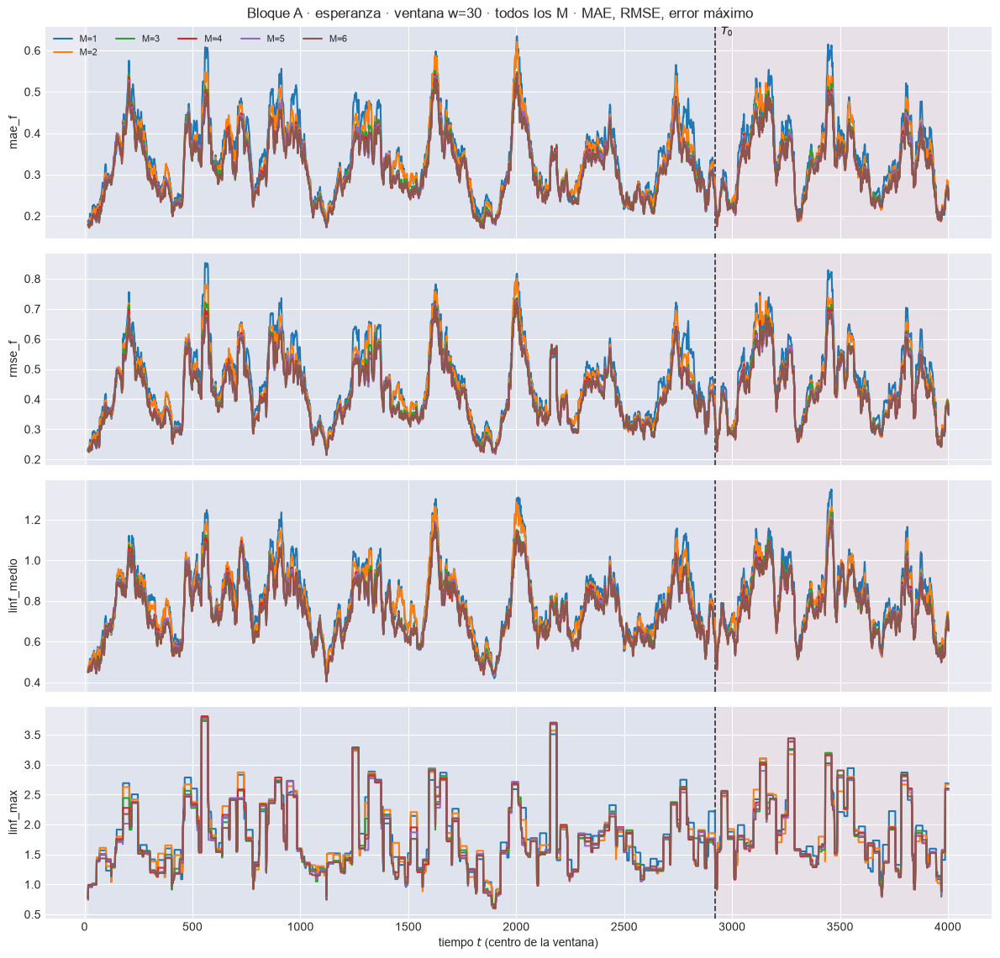

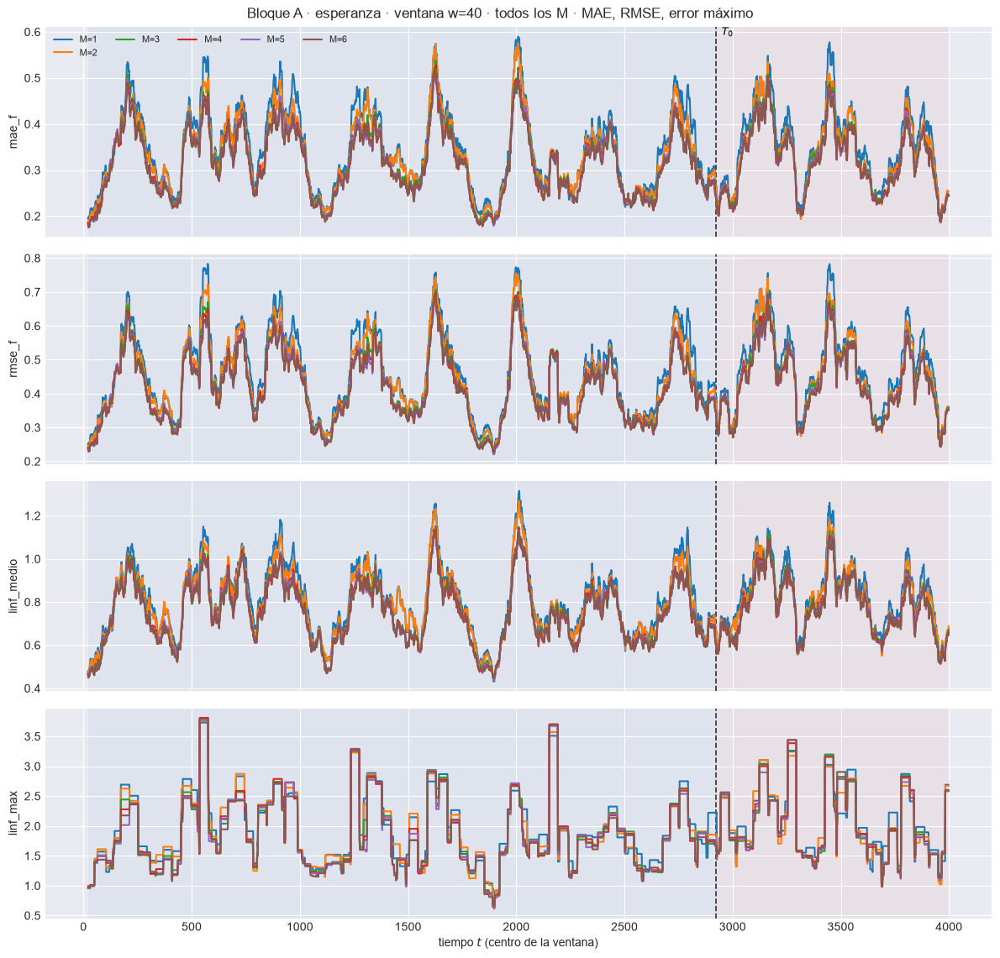

In [9]:
for M in M_OK:
    tablas_ventana(EST[M], DIS, ORIG, PESOS_TAU, predictores=PREDICTORES, intervalos=INTERVALOS)
TABLAS_W = apilar_tablas(EST, M_OK, VENTANAS_W, METRICAS_A_COLS + METRICAS_B_COLS)
verificar_relaciones_metricas(EST, M_OK, VENTANAS_W)

# Una figura por ancho con los M superpuestos.
for w in VENTANAS_W:
    plot_ventana_movil(
        TABLAS_W[w], T0, METRICAS_A_COLS, columna_grupo="punto",
        title=f"Bloque A · esperanza · ventana w={w} · todos los M · MAE, RMSE, error máximo",
        save_path=str(PATH_BARRIDO / f"85_bloqueA_w{w}.png"), verbose=(w == W_REF))
    plt.show()

### 4.1 ¿Qué $M$ gana en cada ventana, y en cada ancho?

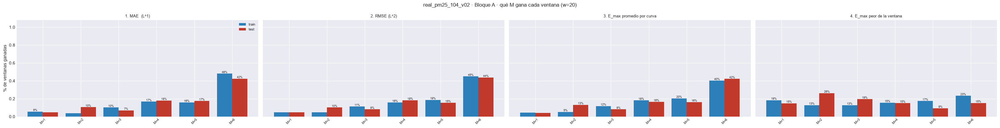

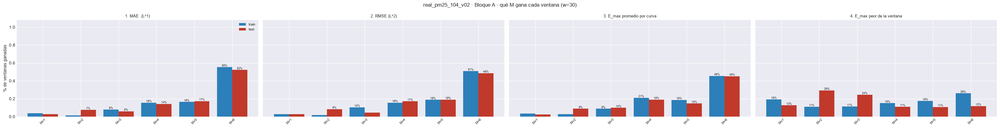

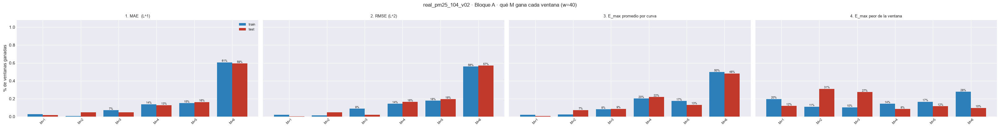

In [10]:
GANA_A = ganancias_por_ventana(EST, M_OK, VENTANAS_W, METRICAS_A, NIVEL)
GANA_B = ganancias_por_ventana(EST, M_OK, VENTANAS_W, METRICAS_B, NIVEL)
GANA_A.to_csv(PATH_BARRIDO / "84_ganador_por_ventana.csv", index=False)
GANA_B.to_csv(PATH_BARRIDO / "87_ganador_bloqueB.csv", index=False)

for w in VENTANAS_W:
    plot_ganador_ventana(GANA_A, METRICAS_A, w, M_OK,
                         f"{EXPERIMENT_BASE} · Bloque A · qué M gana cada ventana (w={w})",
                         PATH_BARRIDO / f"84_ganador_por_ventana_w{w}.png")
    plt.show()

display(tabla_ganadores_test(GANA_A).style.format("{:.1%}")
        .set_caption("Bloque A · % de ventanas TEST ganadas por M (84_ganador_por_ventana.csv)"))

# Salto del MISE en T0, sin las ventanas que lo cruzan.
display(saltos_T0(EST, M_OK, VENTANAS_W).set_index(["M", "w"]).style
        .format({"mise_train": "{:.6f}", "mise_test": "{:.6f}", "salto": "{:.2f}x"})
        .set_caption("MISE train / test y salto en T0"))

### 4.2 ¿Qué predictor gana cada ventana?

Bajo MAE ganan las medianas si la predictiva es multimodal o asimétrica; bajo RMSE, la esperanza.

In [11]:
for M in M_OK:
    EST[M]["ventana_pred"] = filtrar_ventana(EST[M]["tablas_fun"][W_REF], intervalo="equicolas")
GANA_P, REL_P = ganadores_por_ventana(EST, "ventana_pred", "predictor", METRICAS_A, NIVEL)
GANA_P.to_csv(PATH_BARRIDO / "101b_ganador_predictor.csv", index=False)

for etiqueta, _c in METRICAS_A:
    display(GANA_P[(GANA_P.metrica == etiqueta) & (GANA_P.bloque == "test")]
            .pivot(index="predictor", columns="M", values="pct_ventanas_ganadas").loc[list(PREDICTORES)]
            .style.format("{:.1%}").background_gradient(cmap="RdYlGn", axis=None)
            .set_caption(f"{etiqueta} · % de ventanas TEST ganadas por cada predictor (w={W_REF})"))

M,1,2,3,4,5,6
predictor,,,,,,
esperanza,42.2%,25.1%,38.3%,43.8%,47.1%,54.7%
mediana,13.1%,29.6%,21.8%,25.1%,33.7%,33.9%
medoide,17.5%,22.1%,22.4%,17.4%,5.2%,8.4%
modal,27.2%,23.1%,17.4%,13.7%,14.0%,2.9%


M,1,2,3,4,5,6
predictor,,,,,,
esperanza,47.0%,35.7%,48.3%,56.2%,54.8%,61.3%
mediana,13.5%,23.7%,19.7%,24.0%,31.5%,26.8%
medoide,11.2%,22.9%,21.5%,15.3%,9.1%,7.2%
modal,28.2%,17.7%,10.6%,4.5%,4.6%,4.7%


M,1,2,3,4,5,6
predictor,,,,,,
esperanza,40.1%,26.6%,35.6%,32.8%,48.3%,49.4%
mediana,10.4%,28.8%,26.1%,23.1%,27.4%,35.7%
medoide,16.0%,21.1%,22.5%,29.2%,10.7%,10.1%
modal,33.5%,23.5%,15.8%,14.8%,13.7%,4.8%


M,1,2,3,4,5,6
predictor,,,,,,
esperanza,54.7%,47.4%,29.4%,24.7%,28.5%,28.9%
mediana,4.6%,11.1%,8.8%,16.4%,10.8%,11.5%
medoide,12.9%,14.7%,21.6%,28.8%,32.1%,30.8%
modal,27.7%,26.8%,40.1%,30.1%,28.7%,28.8%


### 4.3 Los cuatro predictores en la ventana móvil

`58_ventana_predictores_w<w>.png` por $M$ y `108_predictores_ventana_w30.png` en el barrido.

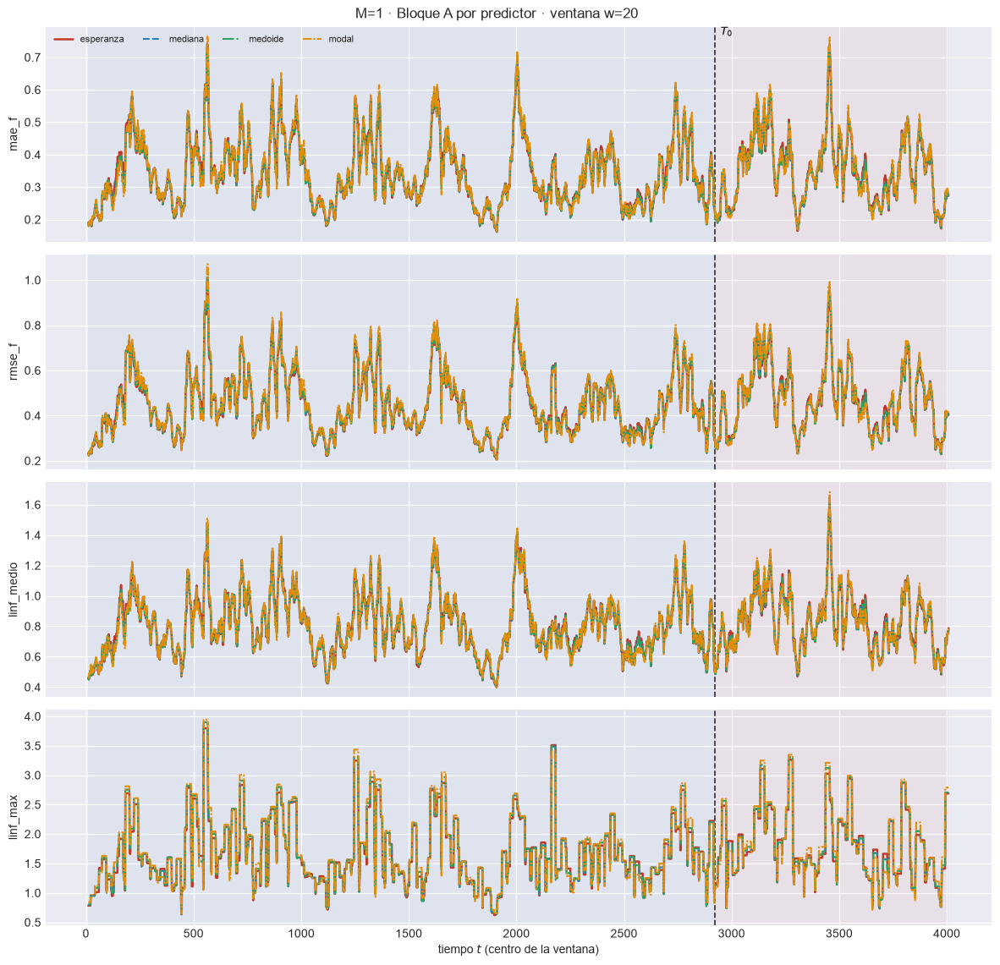

[plot_ventana_movil] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.1s  mae_f: w=30 train=0.3353  w=30 test=0.3535


  2/4 (50.0%) t=0.0s eta=0.0s  rmse_f: w=30 train=0.4406  w=30 test=0.4683


  3/4 (75.0%) t=0.1s eta=0.0s  linf_medio: w=30 train=0.7975  w=30 test=0.8287


  4/4 (100.0%) t=0.1s eta=0.0s  linf_max: w=30 train=1.758  w=30 test=1.875


[plot_ventana_movil] listo: 4 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_pm25_104_v02_m01\58_ventana_predictores_w30.png


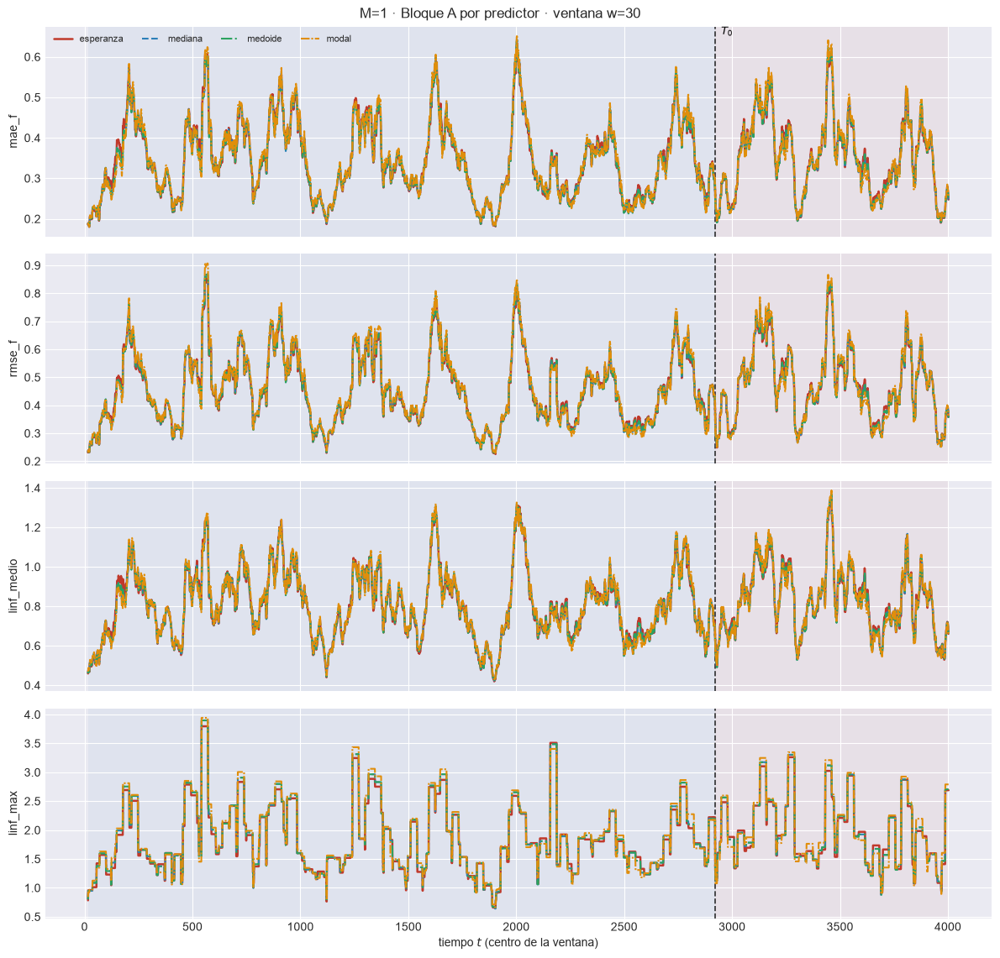

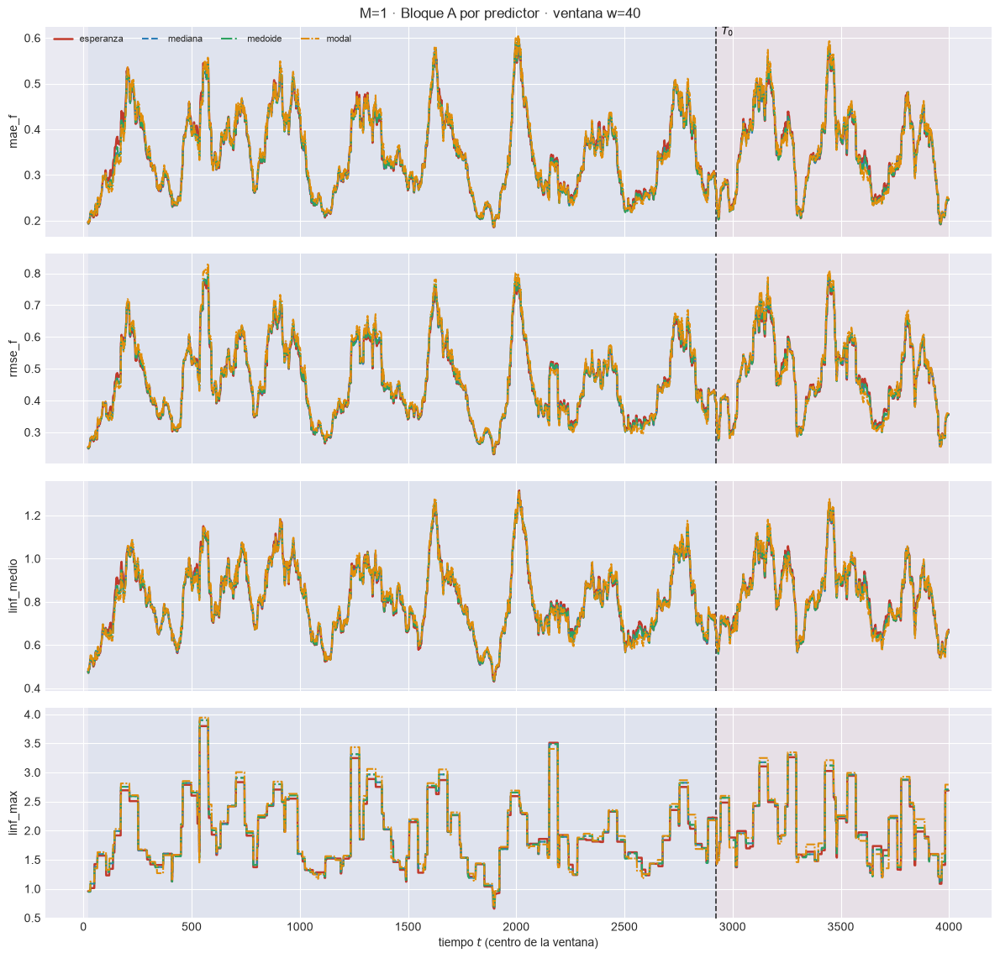

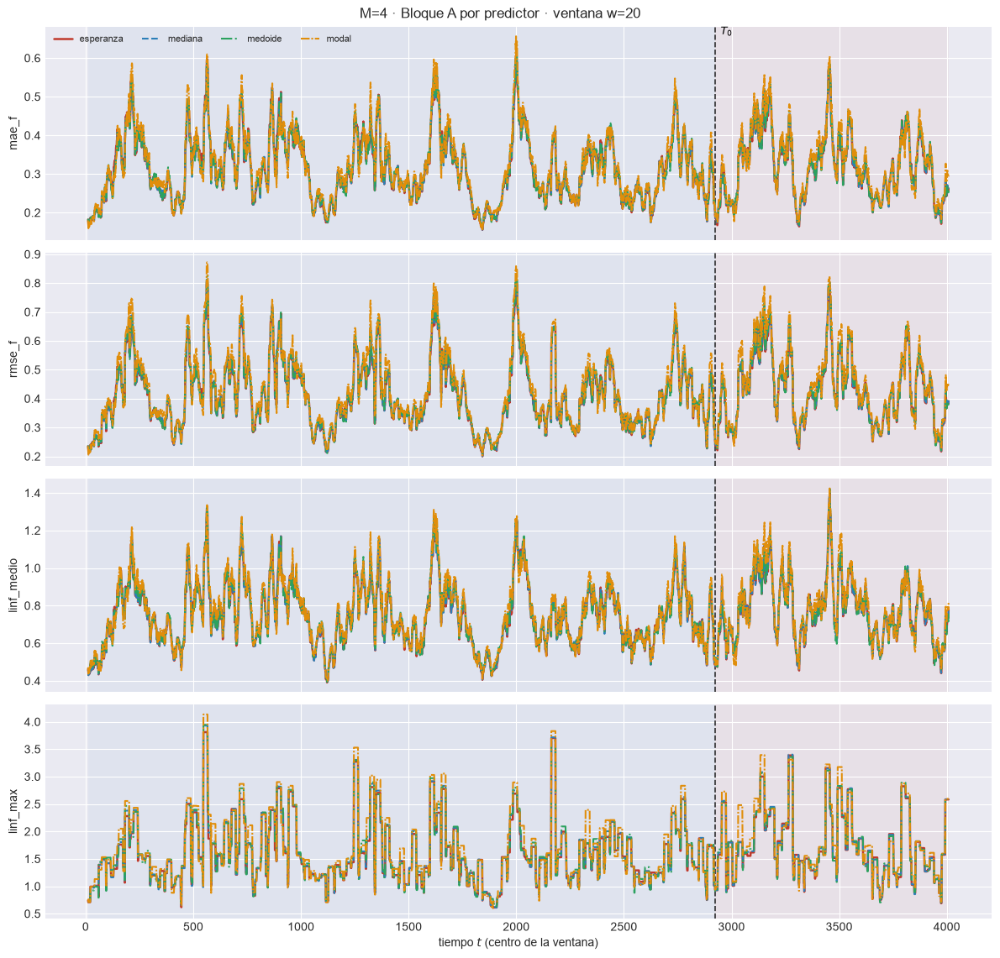

[plot_ventana_movil] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.1s  mae_f: w=30 train=0.3085  w=30 test=0.327


  2/4 (50.0%) t=0.0s eta=0.0s  rmse_f: w=30 train=0.4048  w=30 test=0.4346


  3/4 (75.0%) t=0.1s eta=0.0s  linf_medio: w=30 train=0.7468  w=30 test=0.7755


  4/4 (100.0%) t=0.1s eta=0.0s  linf_max: w=30 train=1.691  w=30 test=1.798


[plot_ventana_movil] listo: 4 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_pm25_104_v02_m04\58_ventana_predictores_w30.png


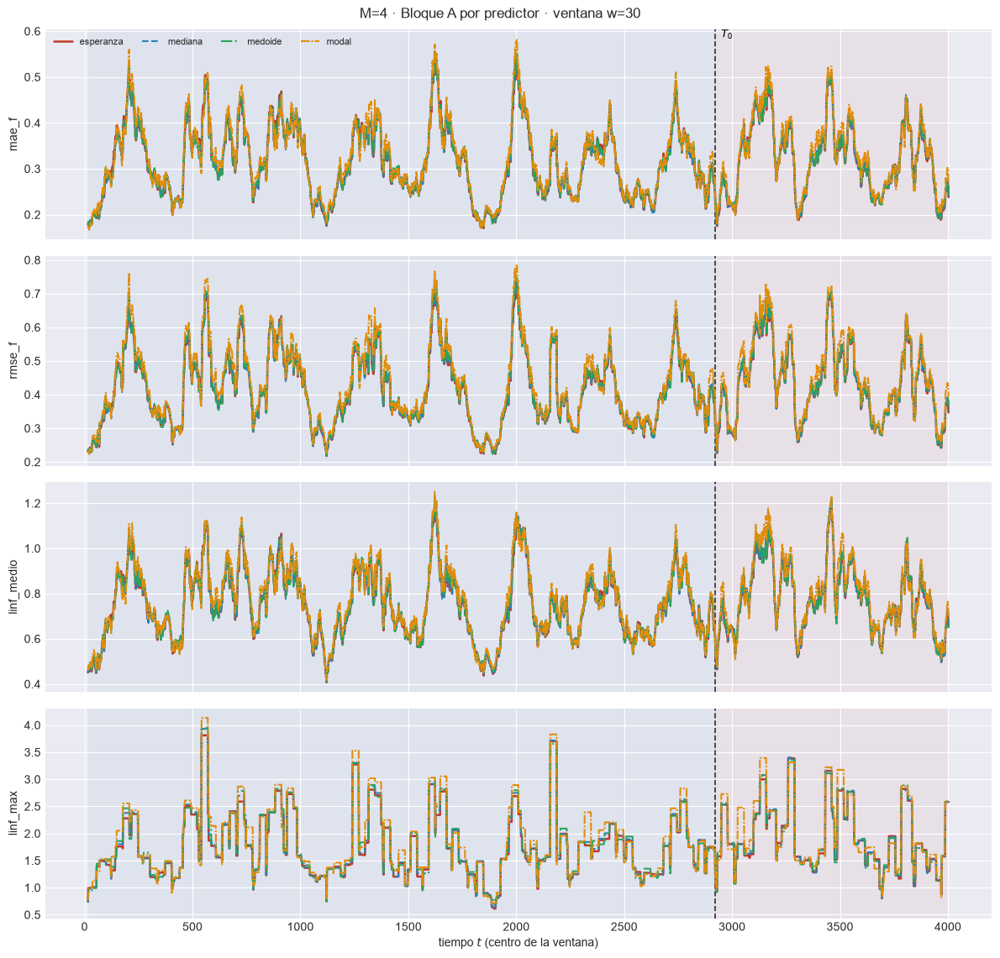

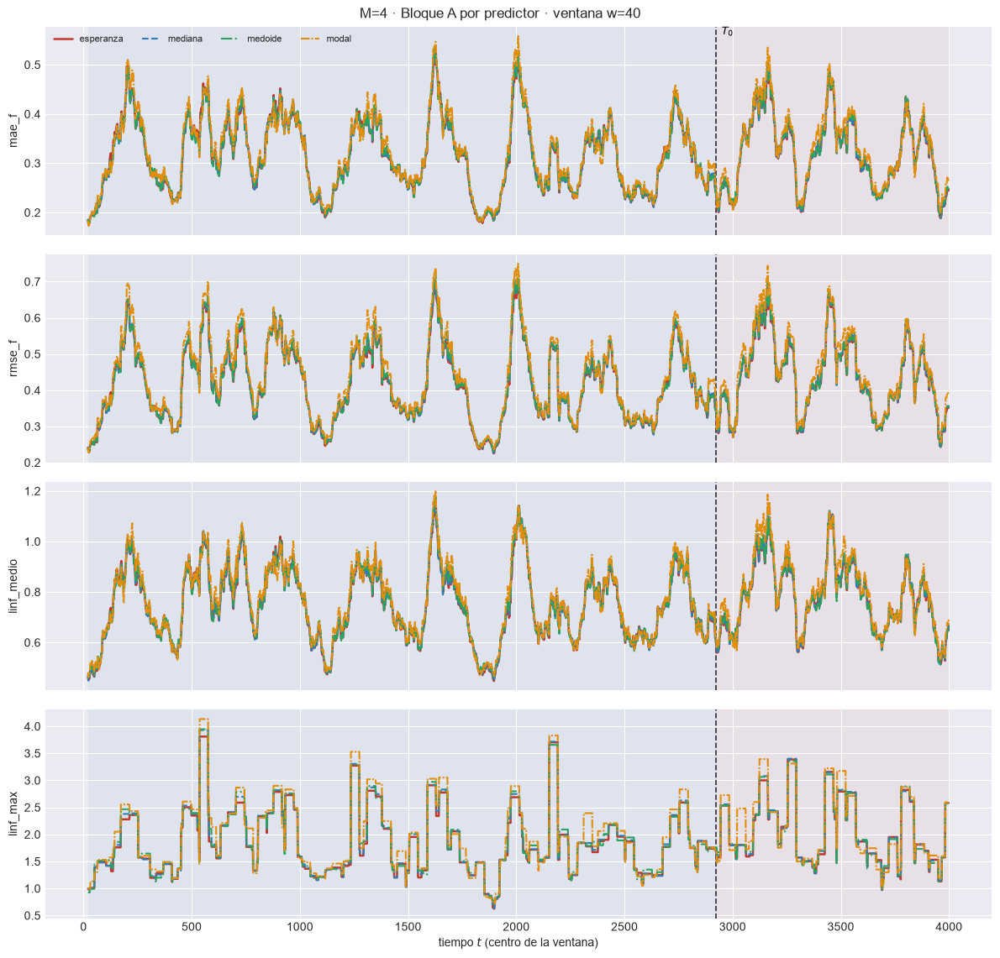

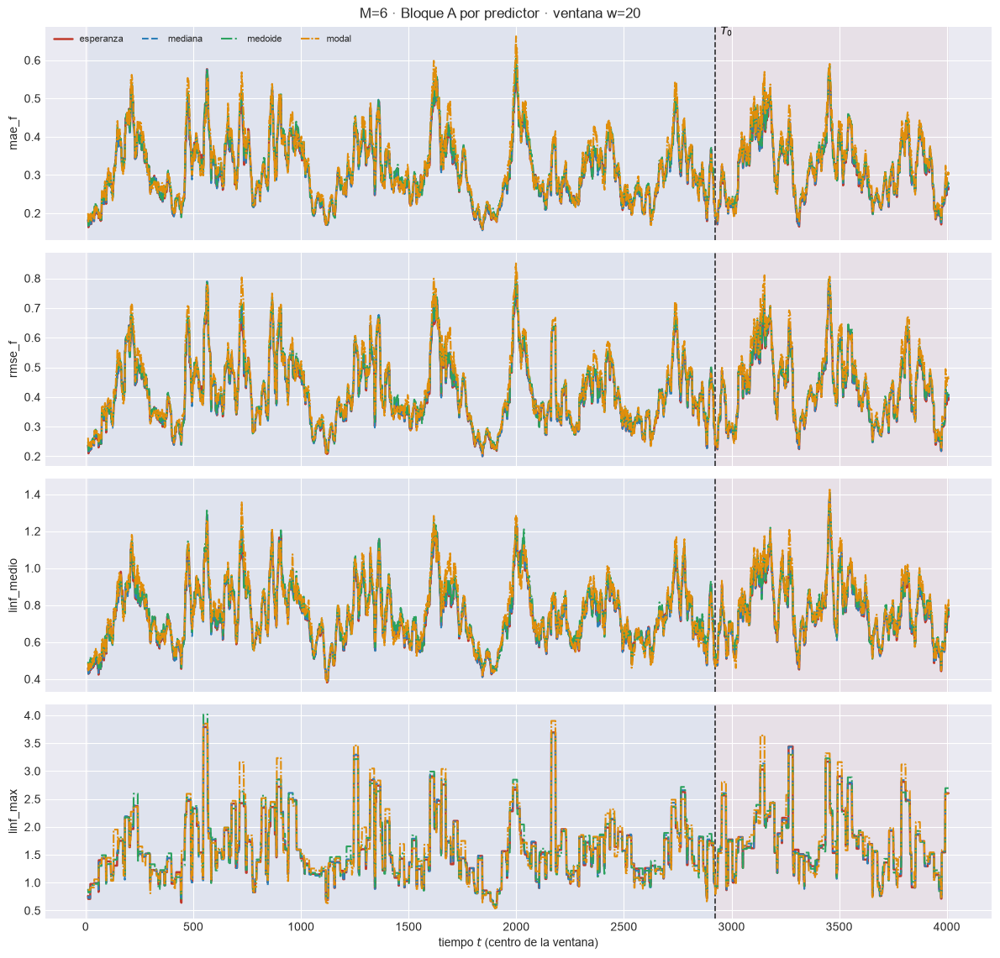

[plot_ventana_movil] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.1s  mae_f: w=30 train=0.3076  w=30 test=0.3252


  2/4 (50.0%) t=0.0s eta=0.0s  rmse_f: w=30 train=0.4027  w=30 test=0.4329


  3/4 (75.0%) t=0.0s eta=0.0s  linf_medio: w=30 train=0.7441  w=30 test=0.7757


  4/4 (100.0%) t=0.1s eta=0.0s  linf_max: w=30 train=1.659  w=30 test=1.815


[plot_ventana_movil] listo: 4 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_pm25_104_v02_m06\58_ventana_predictores_w30.png


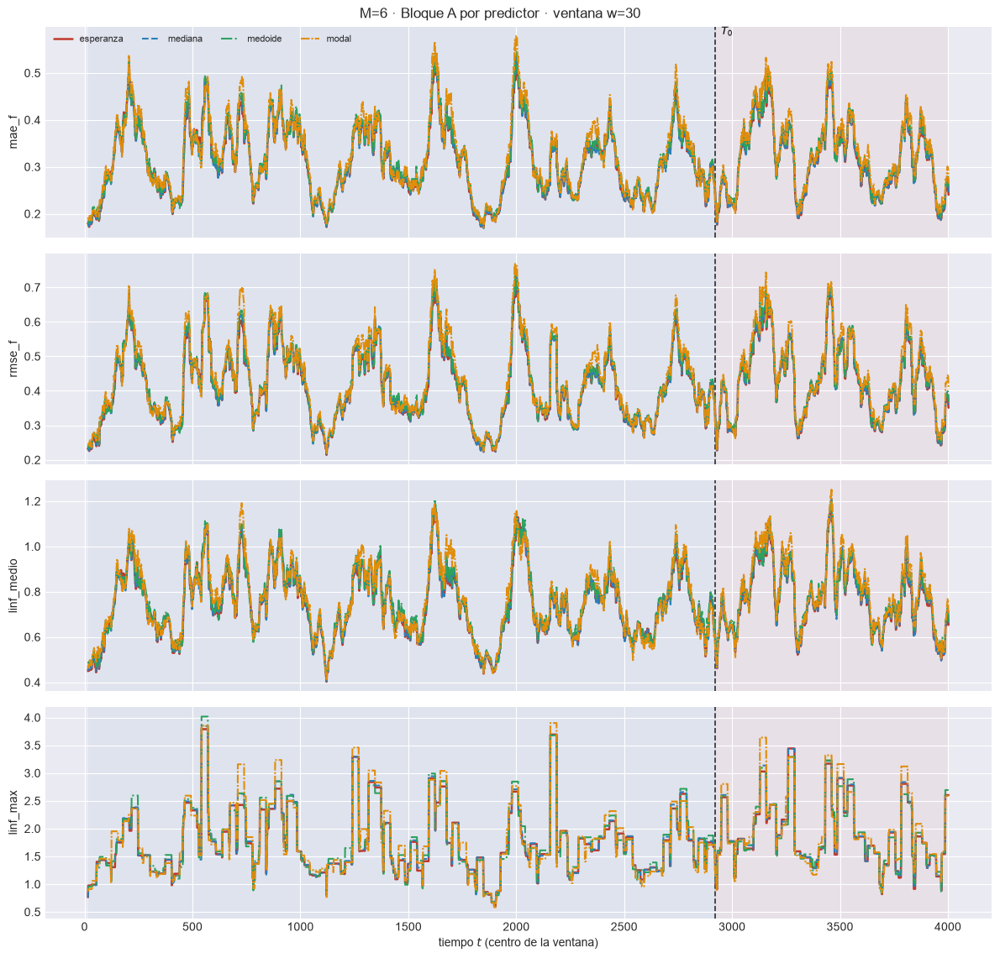

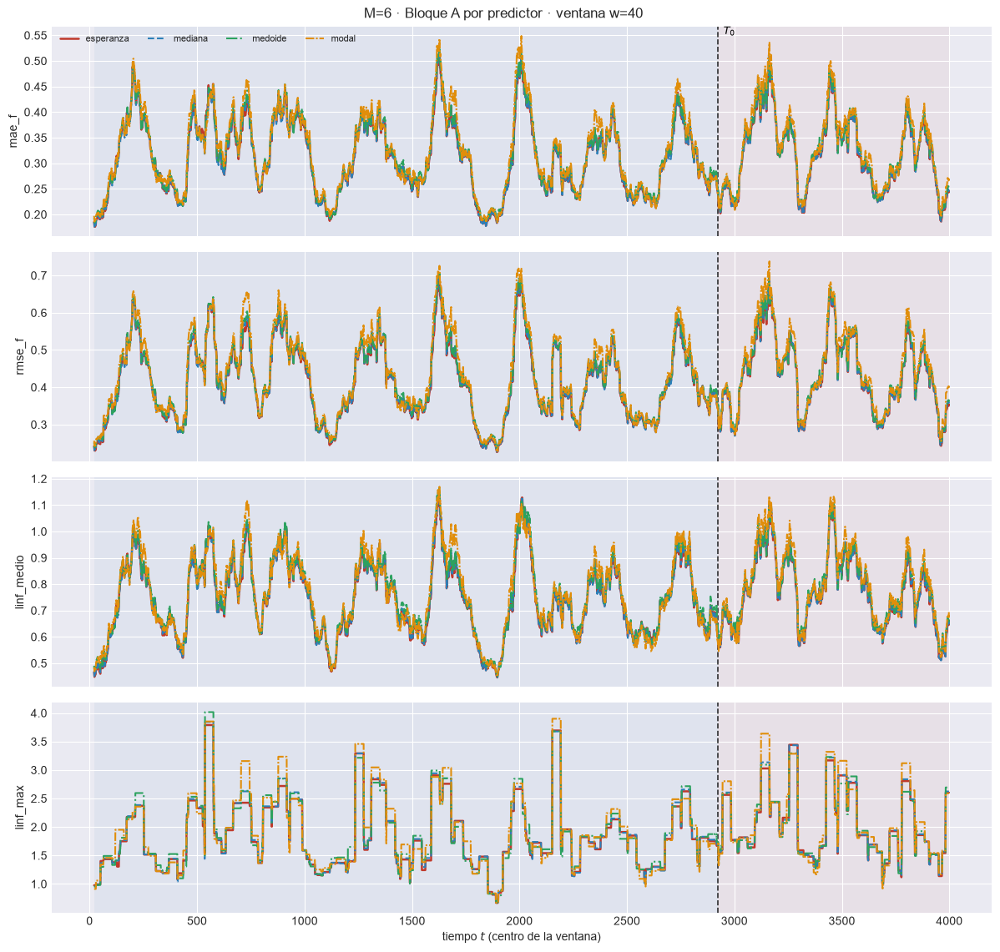

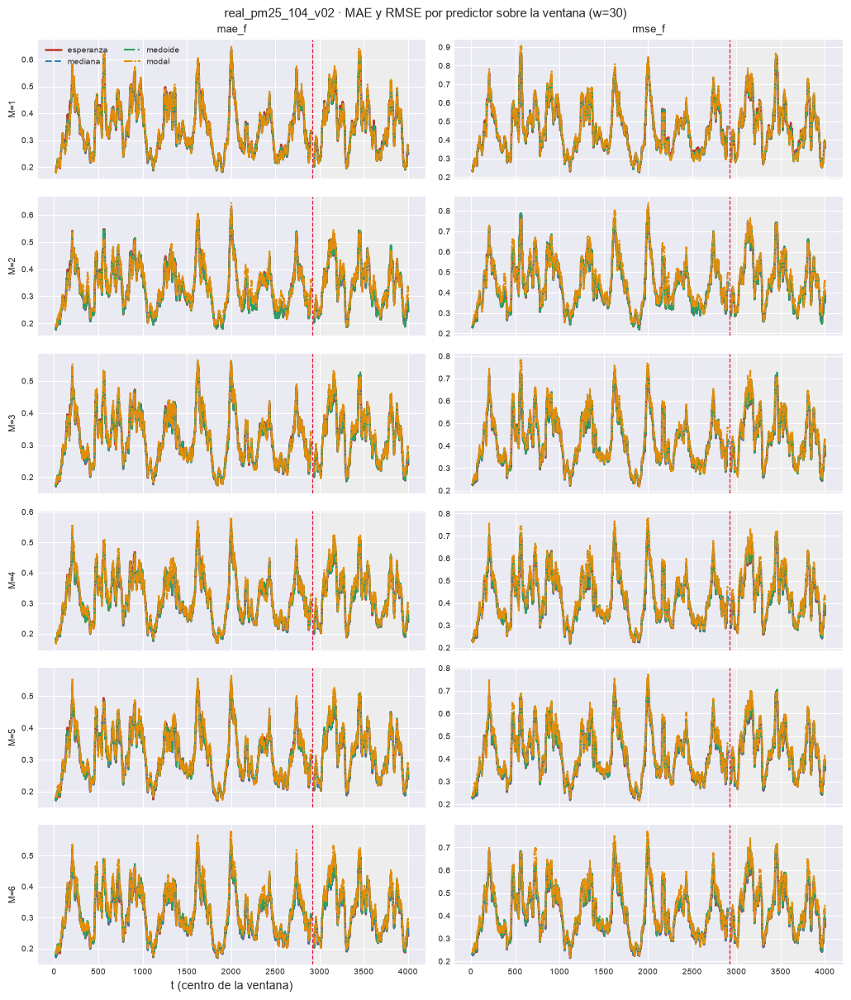

In [12]:
for M in (m for m in M_DETALLE if m in M_OK):
    for w in VENTANAS_W:
        tp = filtrar_ventana(EST[M]["tablas_fun"][w], intervalo="equicolas")
        tp.attrs["w"] = w
        plot_ventana_movil(
            tp, T0, METRICAS_A_COLS, columna_grupo="predictor", estilos=ESTILOS_PREDICTORES,
            title=f"M={M} · Bloque A por predictor · ventana w={w}",
            save_path=str(EST[M]["paths"]["out_report"] / f"58_ventana_predictores_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

plot_ventana_grupos_por_M(
    {M: filtrar_ventana(EST[M]["tablas_fun"][W_REF], intervalo="equicolas") for M in M_OK},
    ["mae_f", "rmse_f"], "predictor", T0, ESTILOS_PREDICTORES,
    f"{EXPERIMENT_BASE} · MAE y RMSE por predictor sobre la ventana (w={W_REF})",
    PATH_BARRIDO / f"108_predictores_ventana_w{W_REF}.png")
plt.show()

## 5. Bloque B por construcción de intervalo

Equi-colas, banda simultánea y HDR puntual (docs §03_05_05) sobre las mismas extracciones; las seis métricas van sobre la unión de tramos. Las figuras de los $M$ superpuestos son de la equi-colas.

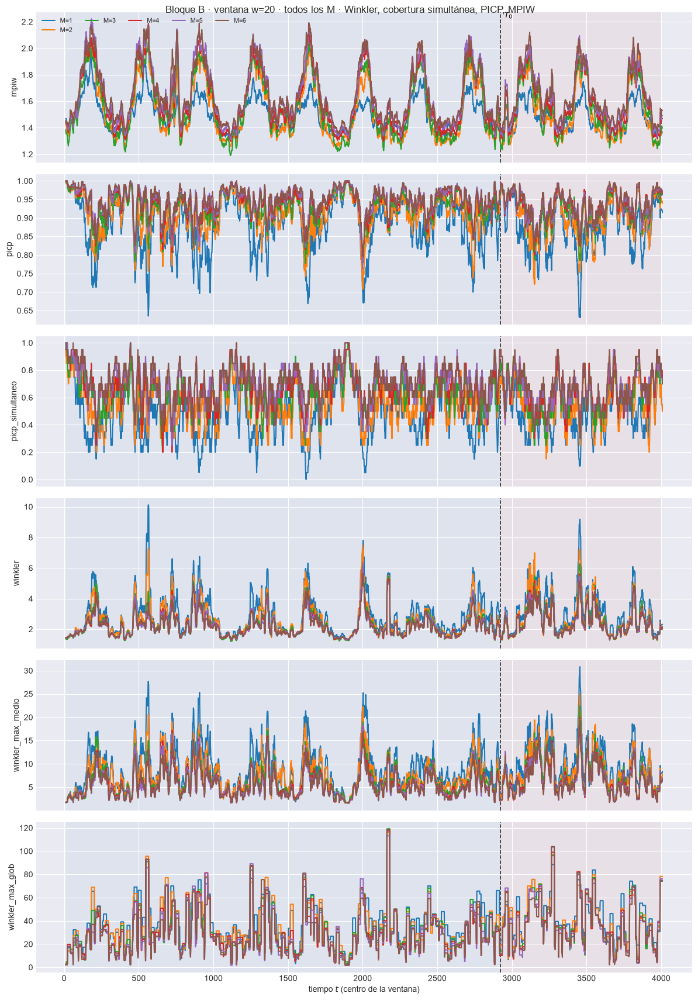

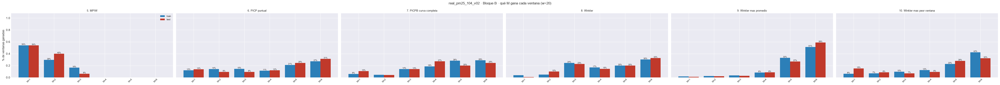

[plot_ventana_movil] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  mpiw: w=30 train=1.535  w=30 test=1.528


  2/6 (33.3%) t=0.1s eta=0.1s  picp: w=30 train=0.9361  w=30 test=0.9208


  3/6 (50.0%) t=0.1s eta=0.1s  picp_simultaneo: w=30 train=0.6333  w=30 test=0.6


  4/6 (66.7%) t=0.1s eta=0.0s  winkler: w=30 train=2.186  w=30 test=2.437


  5/6 (83.3%) t=0.1s eta=0.0s  winkler_max_medio: w=30 train=5.924  w=30 test=7.174


  6/6 (100.0%) t=0.2s eta=0.0s  winkler_max_glob: w=30 train=33.49  w=30 test=42.55


[plot_ventana_movil] listo: 6 pasos en 0.8s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_pm25_104_v02_barrido_M\86_bloqueB_w30.png


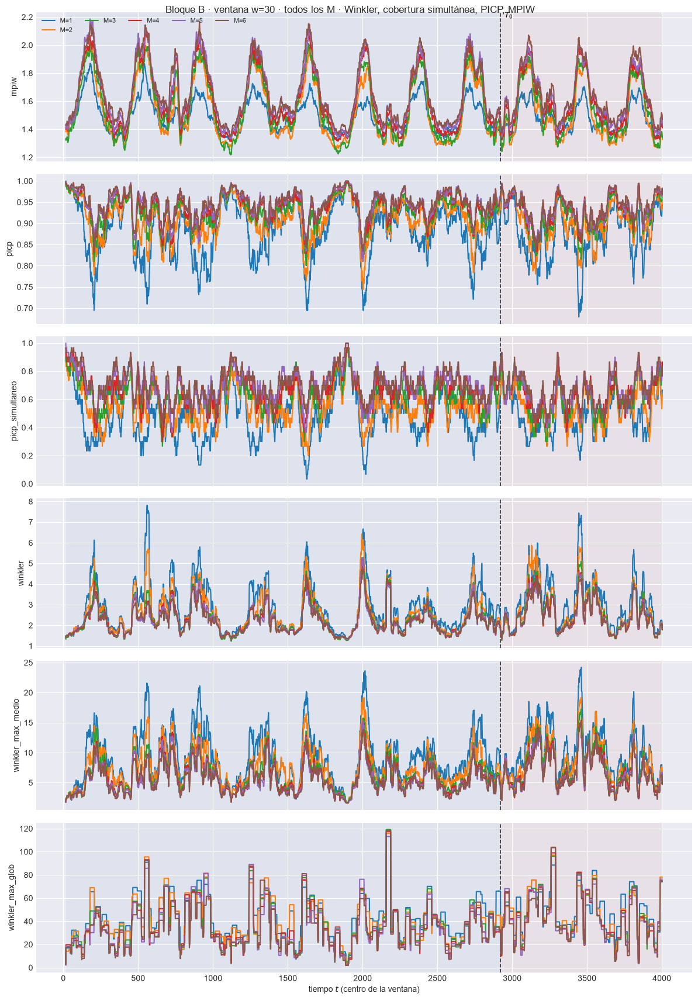

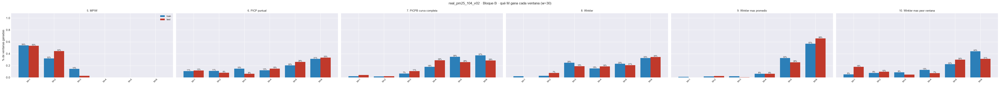

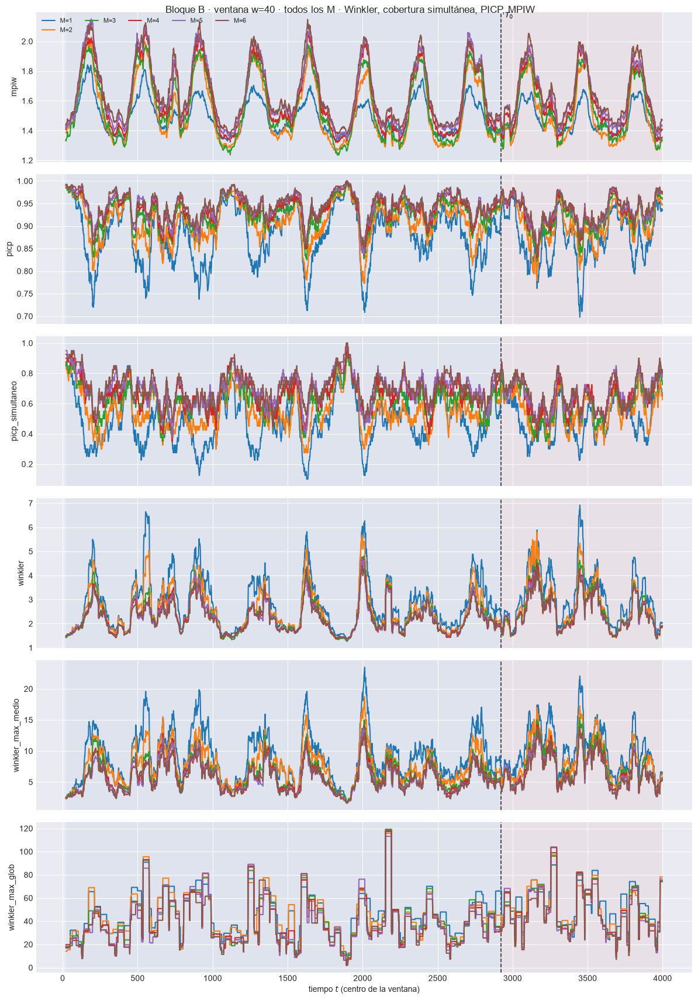

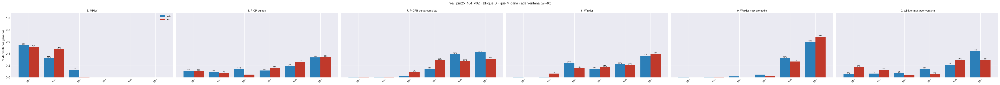

In [13]:
for w in VENTANAS_W:
    plot_ventana_movil(
        TABLAS_W[w], T0, METRICAS_B_COLS, columna_grupo="punto",
        title=f"Bloque B · ventana w={w} · todos los M · Winkler, cobertura simultánea, PICP, MPIW",
        save_path=str(PATH_BARRIDO / f"86_bloqueB_w{w}.png"), verbose=(w == W_REF))
    plt.show()
    # En picp el objetivo es el NOMINAL, no el mínimo.
    plot_ganador_ventana(GANA_B, METRICAS_B, w, M_OK,
                         f"{EXPERIMENT_BASE} · Bloque B · qué M gana cada ventana (w={w})",
                         PATH_BARRIDO / f"87_ganador_bloqueB_w{w}.png")
    plt.show()

display(tabla_ganadores_test(GANA_B).style.format("{:.1%}")
        .set_caption("Bloque B · % de ventanas TEST ganadas por M (87_ganador_bloqueB.csv)"))

### 5.1 Las tres construcciones en la ventana móvil

`59_ventana_intervalos_w<w>.png` por $M$ y quién gana cada ventana (`109_*`). En PICP y PICPB gana la más cercana al nominal.

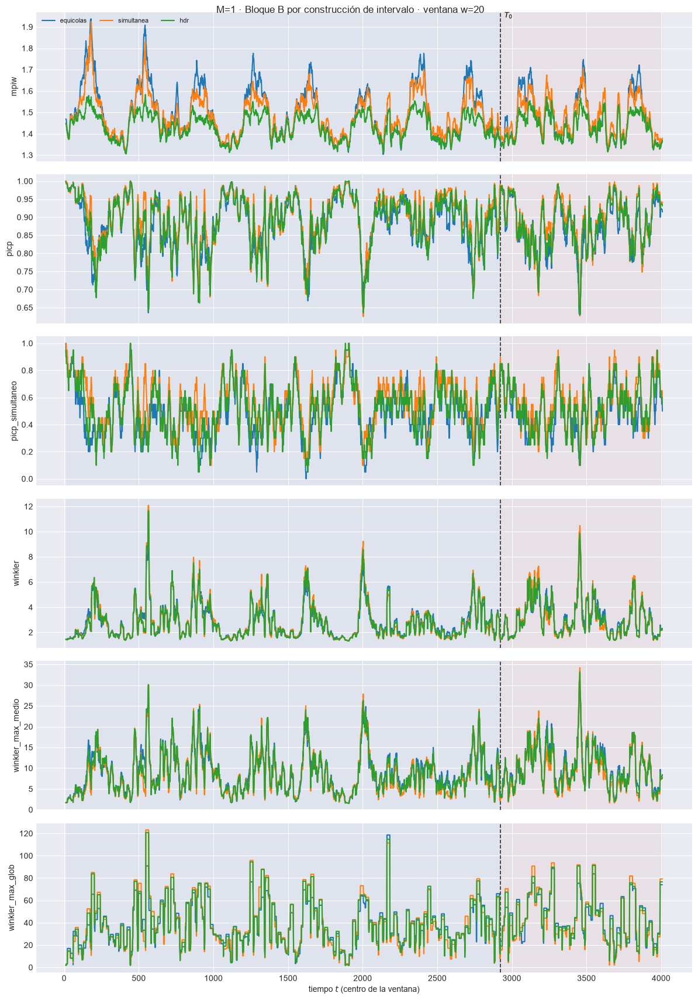

[plot_ventana_movil] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  mpiw: w=30 train=1.452  w=30 test=1.452


  2/6 (33.3%) t=0.0s eta=0.1s  picp: w=30 train=0.8972  w=30 test=0.8806


  3/6 (50.0%) t=0.0s eta=0.0s  picp_simultaneo: w=30 train=0.5  w=30 test=0.5


  4/6 (66.7%) t=0.1s eta=0.0s  winkler: w=30 train=2.476  w=30 test=2.856


  5/6 (83.3%) t=0.1s eta=0.0s  winkler_max_medio: w=30 train=8.066  w=30 test=9.4


  6/6 (100.0%) t=0.1s eta=0.0s  winkler_max_glob: w=30 train=41.99  w=30 test=50.03


[plot_ventana_movil] listo: 6 pasos en 0.7s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_pm25_104_v02_m01\59_ventana_intervalos_w30.png


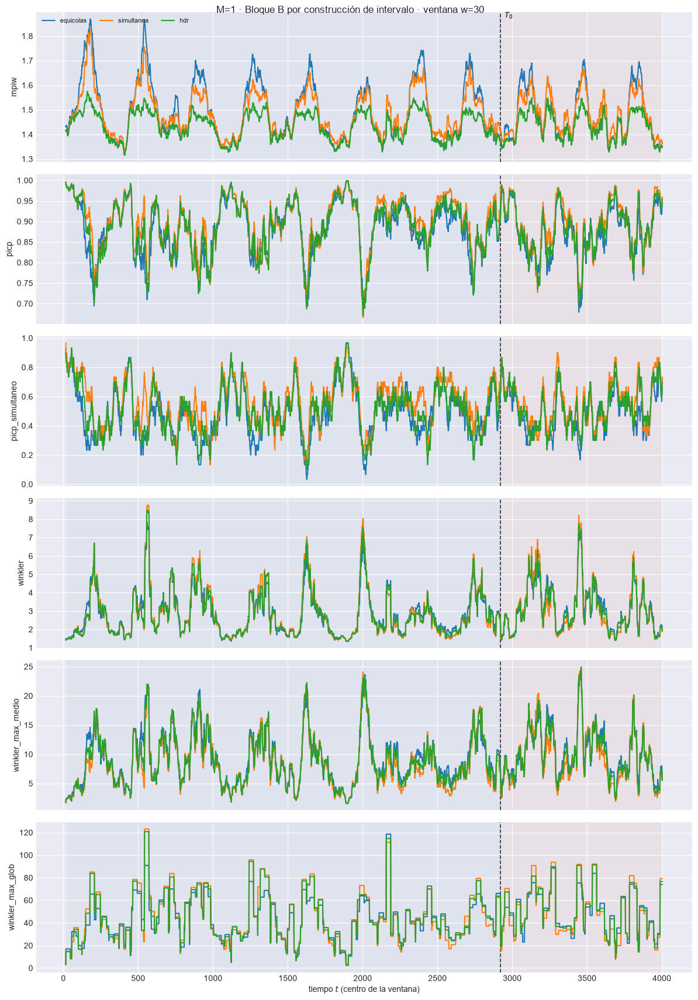

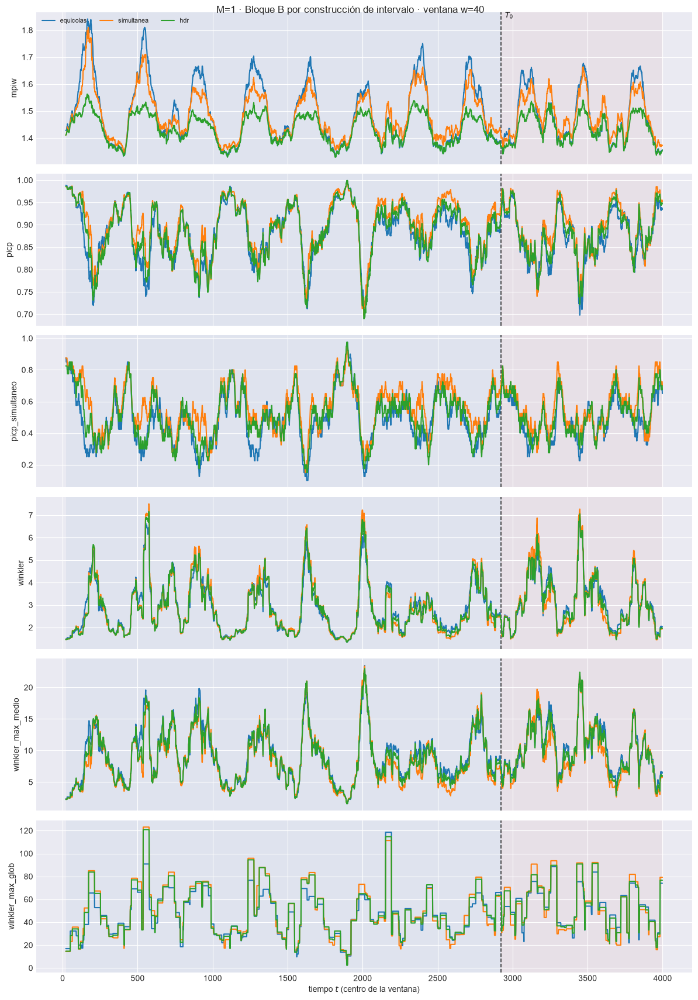

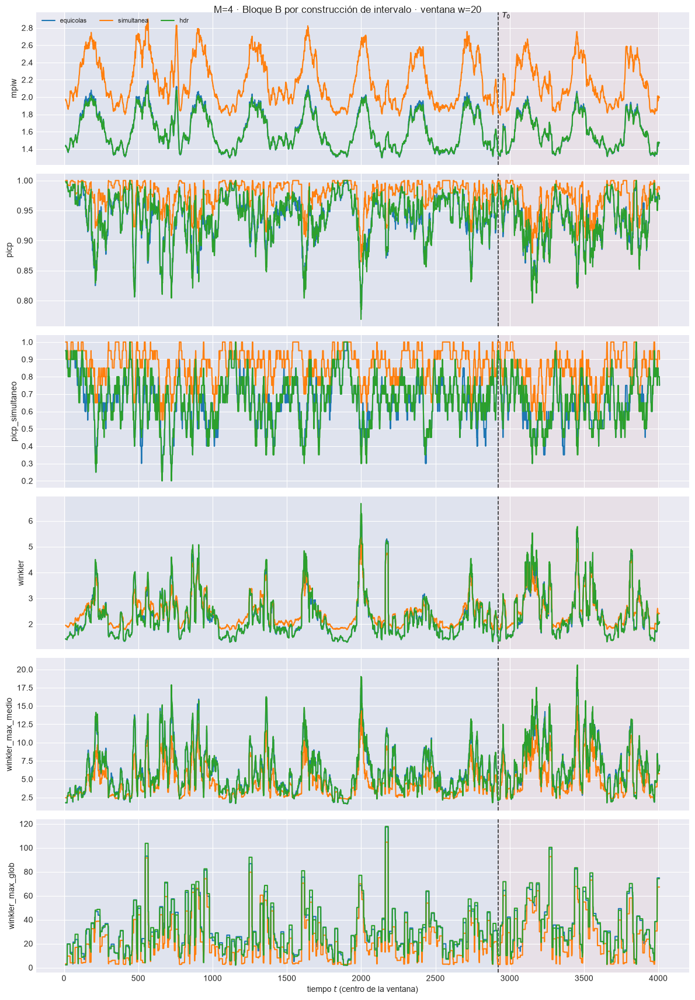

[plot_ventana_movil] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  mpiw: w=30 train=1.802  w=30 test=1.76


  2/6 (33.3%) t=0.0s eta=0.1s  picp: w=30 train=0.9583  w=30 test=0.9444


  3/6 (50.0%) t=0.0s eta=0.0s  picp_simultaneo: w=30 train=0.7333  w=30 test=0.7


  4/6 (66.7%) t=0.1s eta=0.0s  winkler: w=30 train=2.195  w=30 test=2.396


  5/6 (83.3%) t=0.1s eta=0.0s  winkler_max_medio: w=30 train=4.766  w=30 test=5.942


  6/6 (100.0%) t=0.1s eta=0.0s  winkler_max_glob: w=30 train=29.5  w=30 test=38.89


[plot_ventana_movil] listo: 6 pasos en 0.7s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_pm25_104_v02_m04\59_ventana_intervalos_w30.png


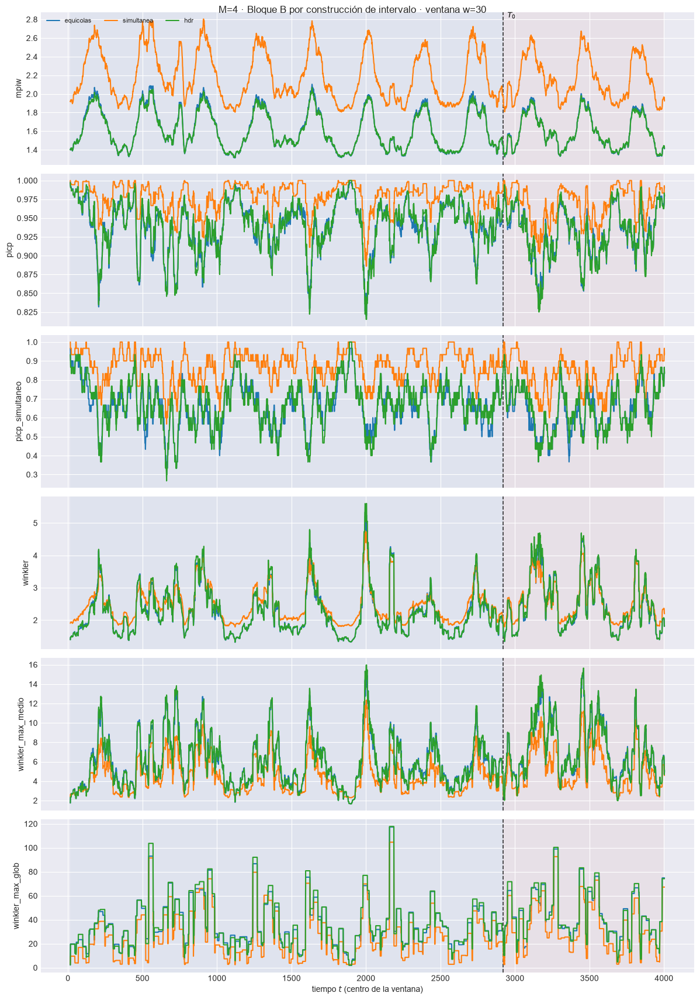

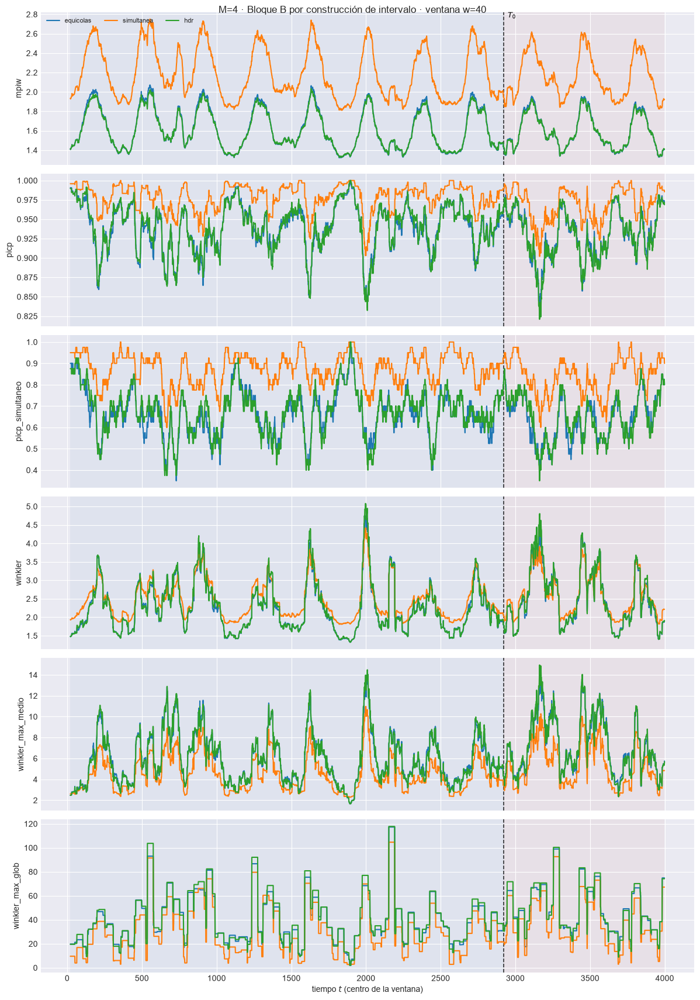

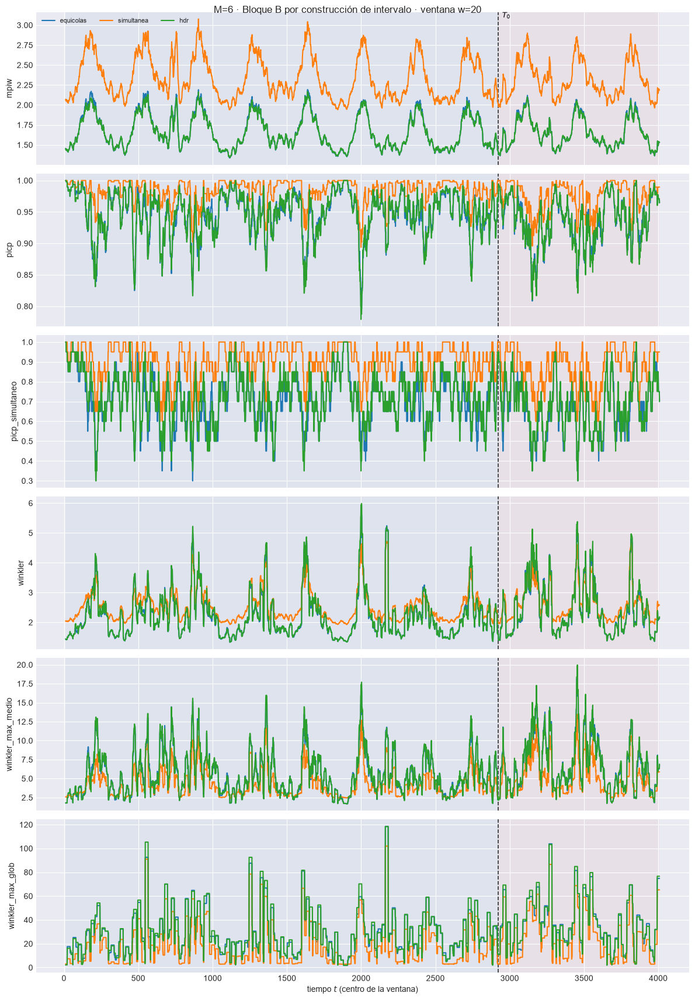

[plot_ventana_movil] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  mpiw: w=30 train=1.836  w=30 test=1.793


  2/6 (33.3%) t=0.0s eta=0.1s  picp: w=30 train=0.9667  w=30 test=0.9514


  3/6 (50.0%) t=0.0s eta=0.0s  picp_simultaneo: w=30 train=0.7667  w=30 test=0.7333


  4/6 (66.7%) t=0.3s eta=0.2s  winkler: w=30 train=2.229  w=30 test=2.418


  5/6 (83.3%) t=0.3s eta=0.1s  winkler_max_medio: w=30 train=4.475  w=30 test=5.555


  6/6 (100.0%) t=0.3s eta=0.0s  winkler_max_glob: w=30 train=27.45  w=30 test=36.17


[plot_ventana_movil] listo: 6 pasos en 1.0s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_pm25_104_v02_m06\59_ventana_intervalos_w30.png


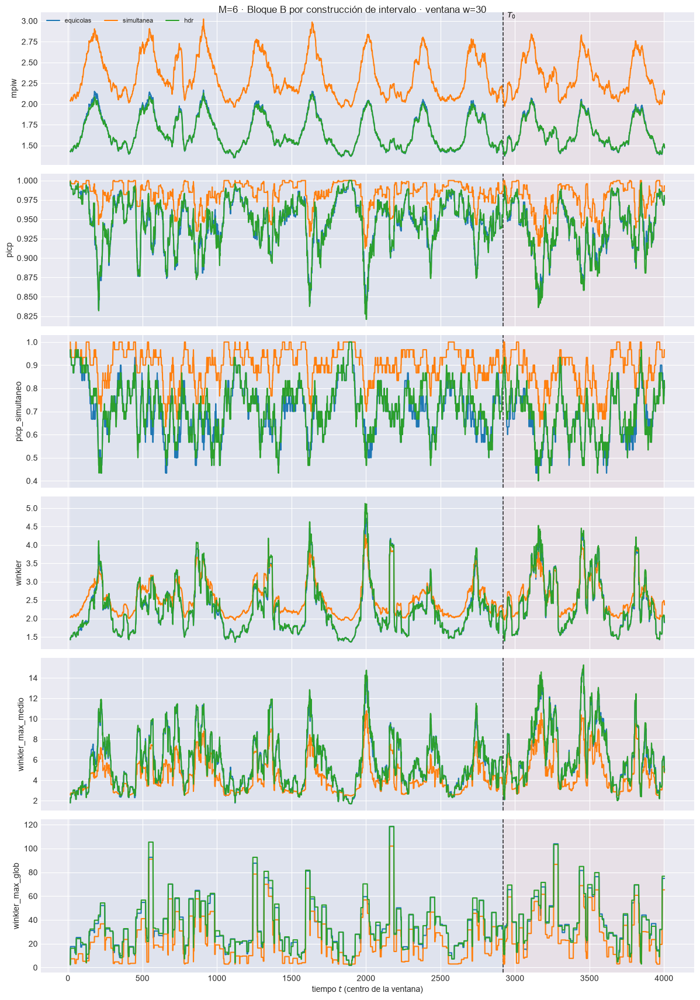

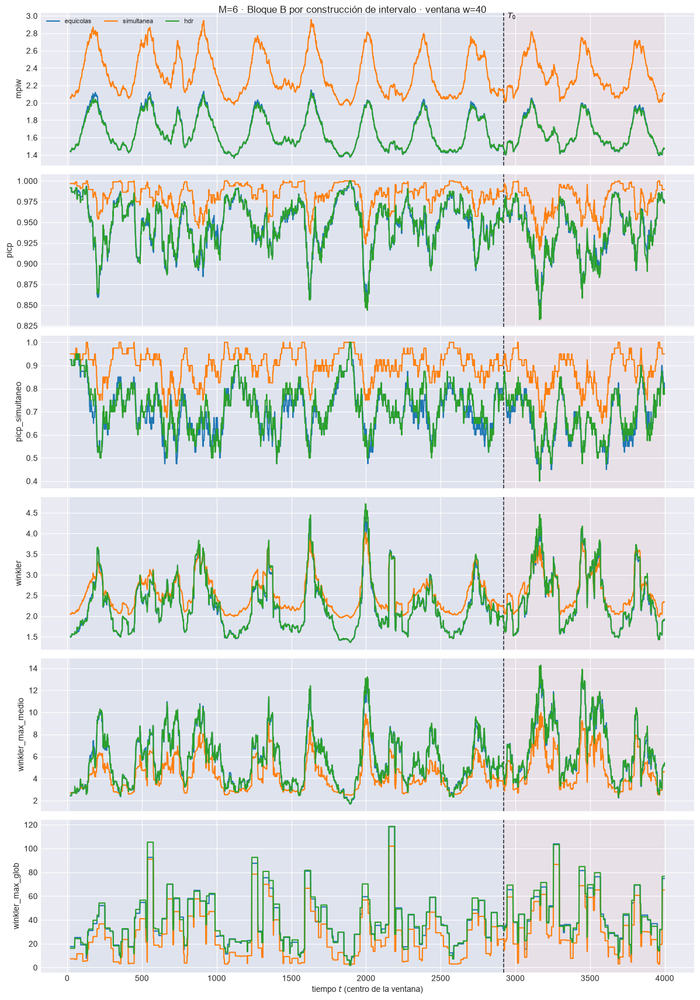

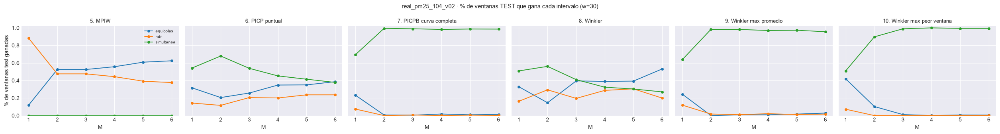

M,1,2,3,4,5,6
intervalo,,,,,,
equicolas,11.9%,52.5%,52.5%,55.7%,60.8%,62.4%
simultanea,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
hdr,88.1%,47.5%,47.5%,44.3%,39.2%,37.6%


M,1,2,3,4,5,6
intervalo,,,,,,
equicolas,31.6%,20.5%,25.7%,34.8%,35.0%,38.6%
simultanea,54.2%,67.9%,53.8%,45.2%,41.4%,37.8%
hdr,14.2%,11.6%,20.5%,20.1%,23.6%,23.6%


M,1,2,3,4,5,6
intervalo,,,,,,
equicolas,23.1%,0.7%,0.5%,1.8%,0.9%,1.3%
simultanea,69.4%,99.3%,98.9%,98.1%,98.6%,98.5%
hdr,7.4%,0.0%,0.7%,0.1%,0.5%,0.2%


M,1,2,3,4,5,6
intervalo,,,,,,
equicolas,32.8%,14.6%,39.5%,39.0%,39.3%,53.0%
simultanea,50.9%,56.0%,41.0%,32.3%,30.3%,27.0%
hdr,16.3%,29.3%,19.6%,28.7%,30.5%,20.0%


M,1,2,3,4,5,6
intervalo,,,,,,
equicolas,24.4%,0.0%,0.8%,0.9%,1.7%,2.8%
simultanea,63.7%,98.2%,98.1%,96.9%,97.2%,95.5%
hdr,11.9%,1.8%,1.0%,2.2%,1.1%,1.7%


M,1,2,3,4,5,6
intervalo,,,,,,
equicolas,41.8%,10.3%,1.1%,0.1%,0.7%,0.6%
simultanea,51.0%,89.7%,98.9%,99.9%,99.3%,99.3%
hdr,7.2%,0.0%,0.0%,0.0%,0.0%,0.1%


In [14]:
for M in (m for m in M_DETALLE if m in M_OK):
    for w in VENTANAS_W:
        ti = filtrar_ventana(EST[M]["tablas_fun"][w], predictor="esperanza")
        ti.attrs["w"] = w
        plot_ventana_movil(
            ti, T0, METRICAS_B_COLS, columna_grupo="intervalo",
            title=f"M={M} · Bloque B por construcción de intervalo · ventana w={w}",
            save_path=str(EST[M]["paths"]["out_report"] / f"59_ventana_intervalos_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

for M in M_OK:
    EST[M]["ventana_int"] = filtrar_ventana(EST[M]["tablas_fun"][W_REF], predictor="esperanza")
GANA_I, REL_I = ganadores_por_ventana(EST, "ventana_int", "intervalo", METRICAS_B, NIVEL)
GANA_I.to_csv(PATH_BARRIDO / f"109_ganador_intervalo_w{W_REF}.csv", index=False)
plot_ganador_grupo_vs_M(GANA_I, "intervalo", METRICAS_B,
                        f"{EXPERIMENT_BASE} · % de ventanas TEST que gana cada intervalo (w={W_REF})",
                        save_path=PATH_BARRIDO / f"109_ganador_intervalo_w{W_REF}.png")
plt.show()
for etiqueta, _c in METRICAS_B:
    display(GANA_I[(GANA_I.metrica == etiqueta) & (GANA_I.bloque == "test")]
            .pivot(index="intervalo", columns="M", values="pct_ventanas_ganadas").loc[list(INTERVALOS)]
            .style.format("{:.1%}").background_gradient(cmap="RdYlGn", axis=None)
            .set_caption(f"{etiqueta} · % de ventanas TEST ganadas por cada intervalo (w={W_REF})"))

## 6. Muestra de predicciones

Ventana de detalle, frontera train/test y ventanas con peor `METRICA_PEORES`.

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=3474 [test] cob=0.208 rmse=0.847


  2/10 (20.0%) t=0.0s eta=0.0s  t=3475 [test] cob=1.000 rmse=0.2758


  3/10 (30.0%) t=0.0s eta=0.0s  t=3476 [test] cob=0.792 rmse=0.3899


  4/10 (40.0%) t=0.0s eta=0.0s  t=3477 [test] cob=1.000 rmse=0.2535


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=3480 [test] cob=0.083 rmse=0.7871


  8/10 (80.0%) t=0.0s eta=0.0s  t=3481 [test] cob=1.000 rmse=0.1771


  9/10 (90.0%) t=0.0s eta=0.0s  t=3482 [test] cob=0.500 rmse=0.7033


  10/10 (100.0%) t=0.0s eta=0.0s  t=3483 [test] cob=0.917 rmse=0.4292


[plot_extractos_curvas] listo: 10 pasos en 0.8s  cob media train=nan test=0.721 (nominal 0.95)


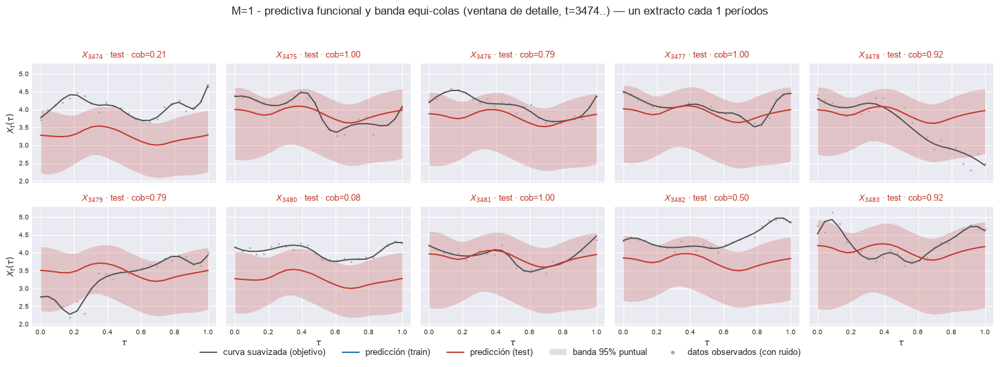

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=3474 [test] cob=0.292 rmse=0.8309


  2/10 (20.0%) t=0.0s eta=0.0s  t=3475 [test] cob=1.000 rmse=0.2588


  3/10 (30.0%) t=0.0s eta=0.0s  t=3476 [test] cob=0.958 rmse=0.4625


  4/10 (40.0%) t=0.0s eta=0.0s  t=3477 [test] cob=1.000 rmse=0.3011


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=3480 [test] cob=1.000 rmse=0.4721


  8/10 (80.0%) t=0.0s eta=0.0s  t=3481 [test] cob=1.000 rmse=0.1833


  9/10 (90.0%) t=0.0s eta=0.0s  t=3482 [test] cob=0.583 rmse=0.7192


  10/10 (100.0%) t=0.0s eta=0.0s  t=3483 [test] cob=1.000 rmse=0.4058


[plot_extractos_curvas] listo: 10 pasos en 0.8s  cob media train=nan test=0.875 (nominal 0.95)


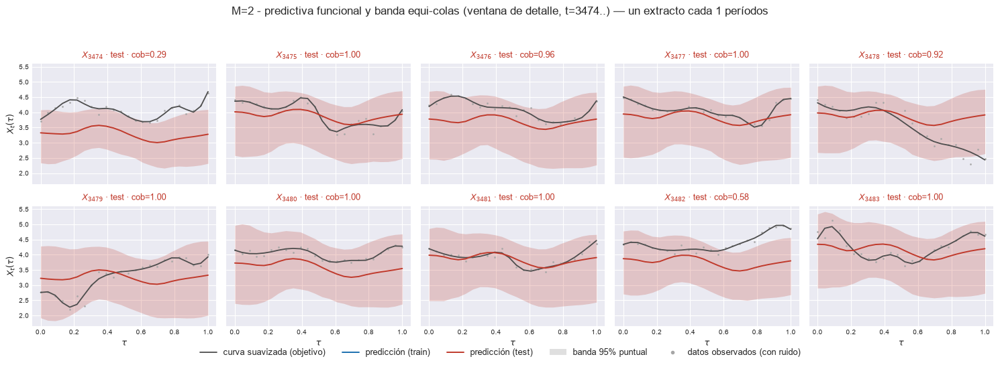

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=3474 [test] cob=0.250 rmse=0.8121


  2/10 (20.0%) t=0.0s eta=0.0s  t=3475 [test] cob=1.000 rmse=0.2425


  3/10 (30.0%) t=0.0s eta=0.0s  t=3476 [test] cob=0.958 rmse=0.4672


  4/10 (40.0%) t=0.0s eta=0.0s  t=3477 [test] cob=1.000 rmse=0.2982


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=3480 [test] cob=1.000 rmse=0.5771


  8/10 (80.0%) t=0.0s eta=0.0s  t=3481 [test] cob=1.000 rmse=0.1619


  9/10 (90.0%) t=0.0s eta=0.0s  t=3482 [test] cob=0.667 rmse=0.6697


  10/10 (100.0%) t=0.0s eta=0.0s  t=3483 [test] cob=1.000 rmse=0.3465


[plot_extractos_curvas] listo: 10 pasos en 0.8s  cob media train=nan test=0.875 (nominal 0.95)


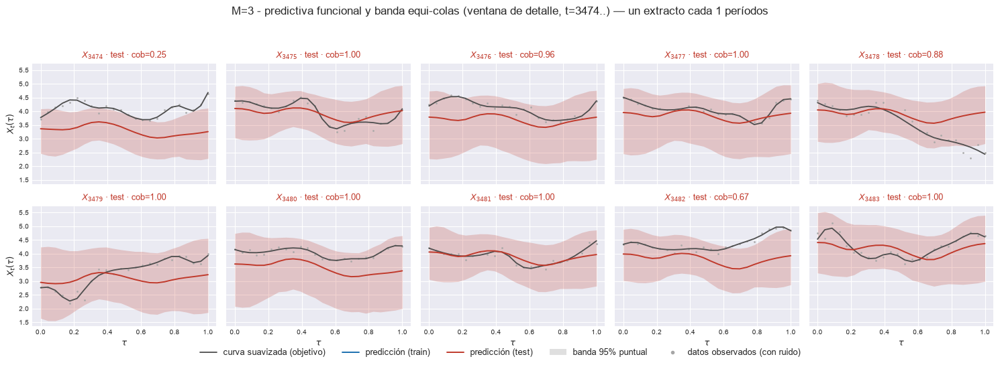

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=3474 [test] cob=0.542 rmse=0.7607


  2/10 (20.0%) t=0.0s eta=0.0s  t=3475 [test] cob=1.000 rmse=0.246


  3/10 (30.0%) t=0.0s eta=0.0s  t=3476 [test] cob=0.958 rmse=0.4453


  4/10 (40.0%) t=0.0s eta=0.0s  t=3477 [test] cob=1.000 rmse=0.3017


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=3480 [test] cob=1.000 rmse=0.6194


  8/10 (80.0%) t=0.0s eta=0.0s  t=3481 [test] cob=1.000 rmse=0.1595


  9/10 (90.0%) t=0.0s eta=0.0s  t=3482 [test] cob=0.667 rmse=0.6674


  10/10 (100.0%) t=0.0s eta=0.0s  t=3483 [test] cob=1.000 rmse=0.3212


[plot_extractos_curvas] listo: 10 pasos en 0.7s  cob media train=nan test=0.908 (nominal 0.95)


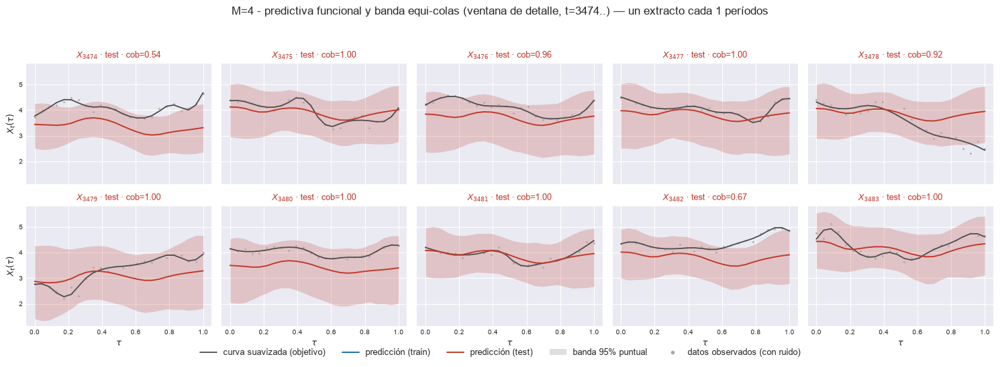

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=3474 [test] cob=0.542 rmse=0.7777


  2/10 (20.0%) t=0.0s eta=0.0s  t=3475 [test] cob=1.000 rmse=0.2336


  3/10 (30.0%) t=0.0s eta=0.0s  t=3476 [test] cob=1.000 rmse=0.4673


  4/10 (40.0%) t=0.0s eta=0.0s  t=3477 [test] cob=1.000 rmse=0.3224


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=3480 [test] cob=1.000 rmse=0.5648


  8/10 (80.0%) t=0.0s eta=0.0s  t=3481 [test] cob=1.000 rmse=0.1598


  9/10 (90.0%) t=0.0s eta=0.0s  t=3482 [test] cob=0.667 rmse=0.6634


  10/10 (100.0%) t=0.0s eta=0.0s  t=3483 [test] cob=1.000 rmse=0.3465


[plot_extractos_curvas] listo: 10 pasos en 0.8s  cob media train=nan test=0.912 (nominal 0.95)


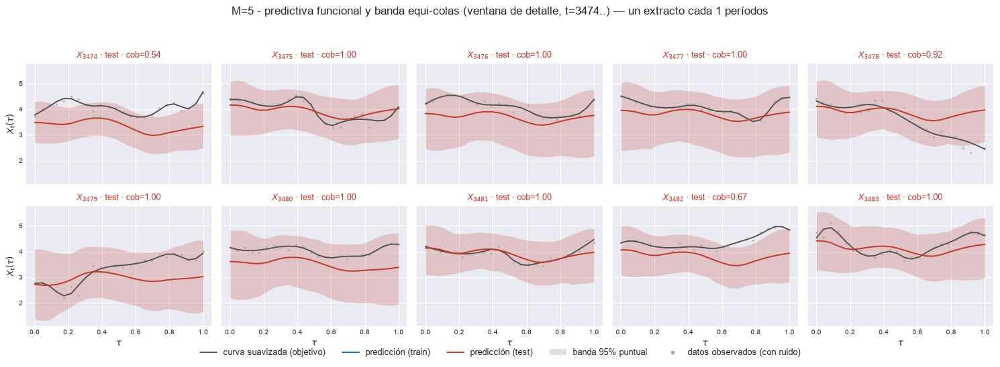

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=3474 [test] cob=0.542 rmse=0.7656


  2/10 (20.0%) t=0.0s eta=0.0s  t=3475 [test] cob=1.000 rmse=0.2204


  3/10 (30.0%) t=0.0s eta=0.0s  t=3476 [test] cob=1.000 rmse=0.4623


  4/10 (40.0%) t=0.0s eta=0.0s  t=3477 [test] cob=1.000 rmse=0.292


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=3480 [test] cob=1.000 rmse=0.6518


  8/10 (80.0%) t=0.0s eta=0.0s  t=3481 [test] cob=1.000 rmse=0.1659


  9/10 (90.0%) t=0.0s eta=0.0s  t=3482 [test] cob=0.667 rmse=0.6441


  10/10 (100.0%) t=0.0s eta=0.0s  t=3483 [test] cob=1.000 rmse=0.3507


[plot_extractos_curvas] listo: 10 pasos en 0.8s  cob media train=nan test=0.904 (nominal 0.95)


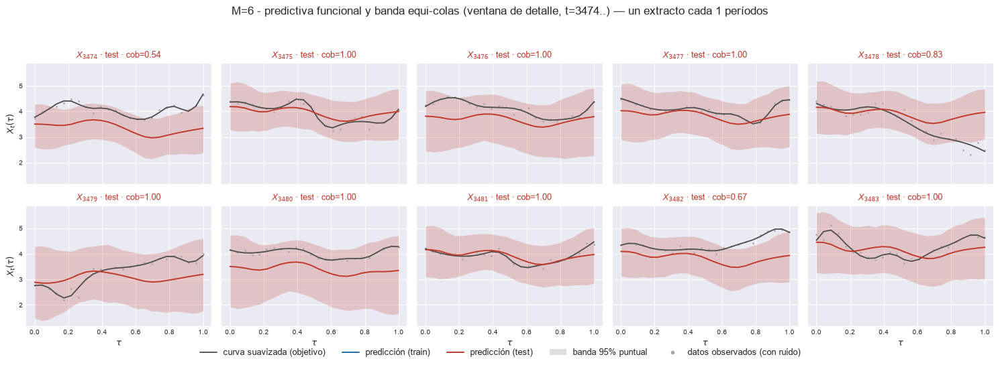

In [15]:
# Los N_DETALLE orígenes de la ventana de detalle (§3.2).
for M in M_OK:
    e = EST[M]
    plot_extractos_curvas(
        X_obj_ev[IDX_DET], e["X_pred"][IDX_DET], e["li_f"][IDX_DET], e["ls_f"][IDX_DET],
        grilla, T0, t=T_DET, cada=1, n_col=5, nivel=NIVEL,
        etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[IDX_DET],
        title=f"M={M} - predictiva funcional y banda equi-colas (ventana de detalle, t={T0_DET}..)",
        save_path=str(e["paths"]["out_report"] / "54_extractos_curvas_test.png"), verbose=True)
    plt.show()

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=2919 [train] cob=1.000 rmse=0.1688


  2/7 (28.6%) t=0.0s eta=0.0s  t=2920 [train] cob=1.000 rmse=0.2682


  3/7 (42.9%) t=0.0s eta=0.0s  t=2921 [train] cob=1.000 rmse=0.1984


  4/7 (57.1%) t=0.0s eta=0.0s  t=2922 [train] cob=1.000 rmse=0.2292


  5/7 (71.4%) t=0.0s eta=0.0s  t=2923 [test] cob=1.000 rmse=0.322


  6/7 (85.7%) t=0.0s eta=0.0s  t=2924 [test] cob=0.875 rmse=0.3861


  7/7 (100.0%) t=0.0s eta=0.0s  t=2925 [test] cob=1.000 rmse=0.1513


[plot_extractos_curvas] listo: 7 pasos en 0.6s  cob media train=1.000 test=0.958 (nominal 0.95)


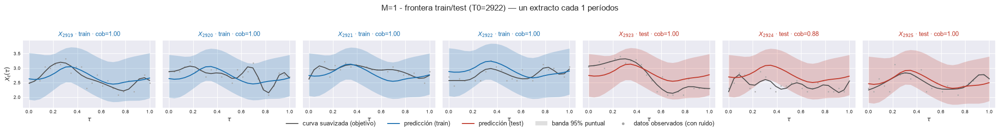

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=2919 [train] cob=1.000 rmse=0.2214


  2/7 (28.6%) t=0.0s eta=0.0s  t=2920 [train] cob=0.958 rmse=0.29


  3/7 (42.9%) t=0.0s eta=0.0s  t=2921 [train] cob=1.000 rmse=0.1987


  4/7 (57.1%) t=0.0s eta=0.0s  t=2922 [train] cob=1.000 rmse=0.2564


  5/7 (71.4%) t=0.0s eta=0.0s  t=2923 [test] cob=0.875 rmse=0.3698


  6/7 (85.7%) t=0.0s eta=0.0s  t=2924 [test] cob=1.000 rmse=0.2606


  7/7 (100.0%) t=0.0s eta=0.0s  t=2925 [test] cob=1.000 rmse=0.1408


[plot_extractos_curvas] listo: 7 pasos en 0.6s  cob media train=0.990 test=0.958 (nominal 0.95)


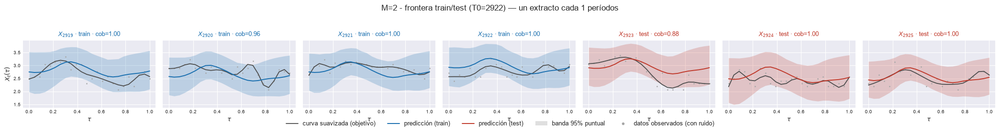

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=2919 [train] cob=1.000 rmse=0.2079


  2/7 (28.6%) t=0.0s eta=0.0s  t=2920 [train] cob=1.000 rmse=0.2716


  3/7 (42.9%) t=0.0s eta=0.0s  t=2921 [train] cob=1.000 rmse=0.1924


  4/7 (57.1%) t=0.0s eta=0.0s  t=2922 [train] cob=1.000 rmse=0.2528


  5/7 (71.4%) t=0.0s eta=0.0s  t=2923 [test] cob=1.000 rmse=0.3606


  6/7 (85.7%) t=0.0s eta=0.0s  t=2924 [test] cob=1.000 rmse=0.2848


  7/7 (100.0%) t=0.0s eta=0.0s  t=2925 [test] cob=1.000 rmse=0.1447


[plot_extractos_curvas] listo: 7 pasos en 0.6s  cob media train=1.000 test=1.000 (nominal 0.95)


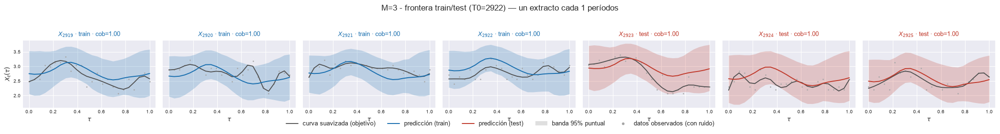

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=2919 [train] cob=1.000 rmse=0.2142


  2/7 (28.6%) t=0.0s eta=0.0s  t=2920 [train] cob=1.000 rmse=0.2728


  3/7 (42.9%) t=0.0s eta=0.0s  t=2921 [train] cob=1.000 rmse=0.1954


  4/7 (57.1%) t=0.0s eta=0.0s  t=2922 [train] cob=1.000 rmse=0.2187


  5/7 (71.4%) t=0.0s eta=0.0s  t=2923 [test] cob=1.000 rmse=0.3696


  6/7 (85.7%) t=0.0s eta=0.0s  t=2924 [test] cob=1.000 rmse=0.2863


  7/7 (100.0%) t=0.0s eta=0.0s  t=2925 [test] cob=1.000 rmse=0.1354


[plot_extractos_curvas] listo: 7 pasos en 0.6s  cob media train=1.000 test=1.000 (nominal 0.95)


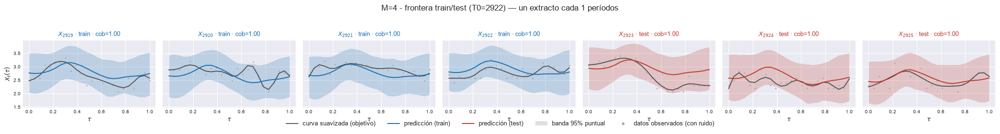

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=2919 [train] cob=1.000 rmse=0.2063


  2/7 (28.6%) t=0.0s eta=0.0s  t=2920 [train] cob=1.000 rmse=0.2748


  3/7 (42.9%) t=0.0s eta=0.0s  t=2921 [train] cob=1.000 rmse=0.1987


  4/7 (57.1%) t=0.0s eta=0.0s  t=2922 [train] cob=1.000 rmse=0.2282


  5/7 (71.4%) t=0.0s eta=0.0s  t=2923 [test] cob=1.000 rmse=0.3672


  6/7 (85.7%) t=0.0s eta=0.0s  t=2924 [test] cob=1.000 rmse=0.2878


  7/7 (100.0%) t=0.0s eta=0.0s  t=2925 [test] cob=1.000 rmse=0.1325


[plot_extractos_curvas] listo: 7 pasos en 0.6s  cob media train=1.000 test=1.000 (nominal 0.95)


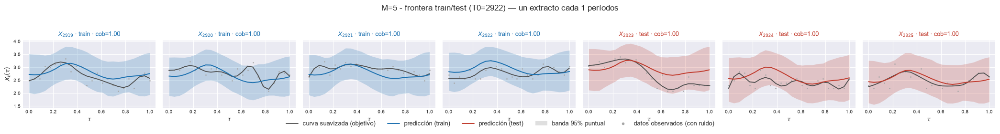

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=2919 [train] cob=1.000 rmse=0.2001


  2/7 (28.6%) t=0.0s eta=0.0s  t=2920 [train] cob=1.000 rmse=0.2627


  3/7 (42.9%) t=0.0s eta=0.0s  t=2921 [train] cob=1.000 rmse=0.2112


  4/7 (57.1%) t=0.0s eta=0.0s  t=2922 [train] cob=1.000 rmse=0.2095


  5/7 (71.4%) t=0.0s eta=0.0s  t=2923 [test] cob=1.000 rmse=0.3558


  6/7 (85.7%) t=0.0s eta=0.0s  t=2924 [test] cob=1.000 rmse=0.2931


  7/7 (100.0%) t=0.0s eta=0.0s  t=2925 [test] cob=1.000 rmse=0.1404


[plot_extractos_curvas] listo: 7 pasos en 0.6s  cob media train=1.000 test=1.000 (nominal 0.95)


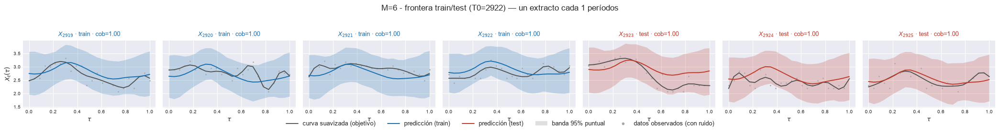

In [16]:
# Zoom sobre la frontera: los últimos orígenes de train y los primeros de test.
i_corte = int(np.searchsorted(t_orig, T0))
sel = np.arange(max(0, i_corte - 3), min(n_orig, i_corte + 4))
for M in M_OK:
    e = EST[M]
    plot_extractos_curvas(
        X_obj_ev[sel], e["X_pred"][sel], e["li_f"][sel], e["ls_f"][sel], grilla, T0,
        t=t_orig[sel], cada=1, n_col=len(sel), nivel=NIVEL,
        etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[sel],
        title=f"M={M} - frontera train/test (T0={T0})",
        save_path=str(e["paths"]["out_report"] / "55_extractos_frontera.png"), verbose=True)
    plt.show()

[M=1] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[3431, 3460]  rmse_f=0.828701


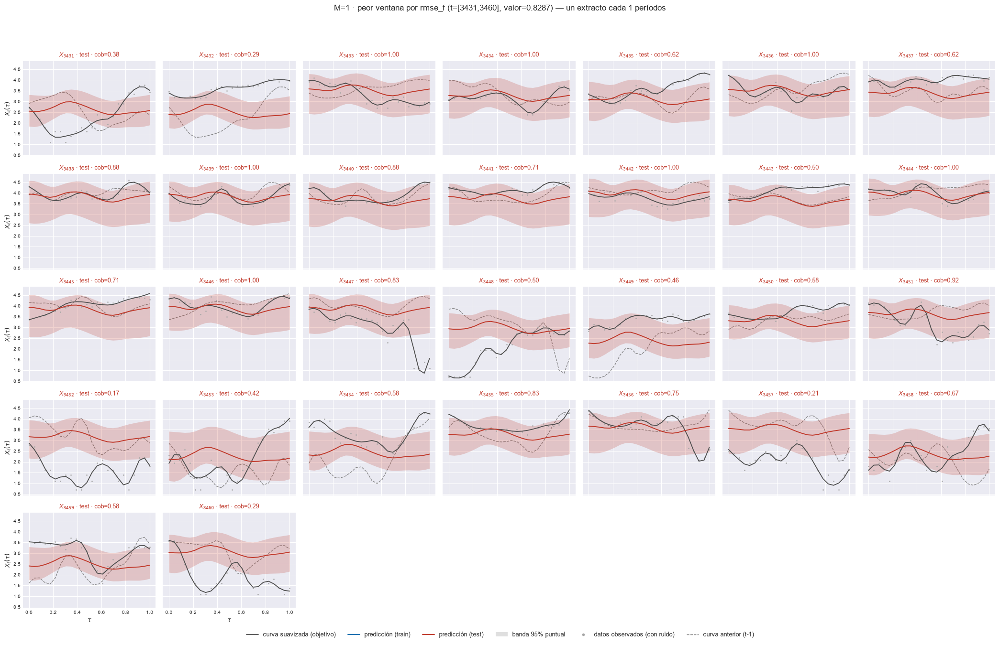

    t=[3432, 3461]  rmse_f=0.825461


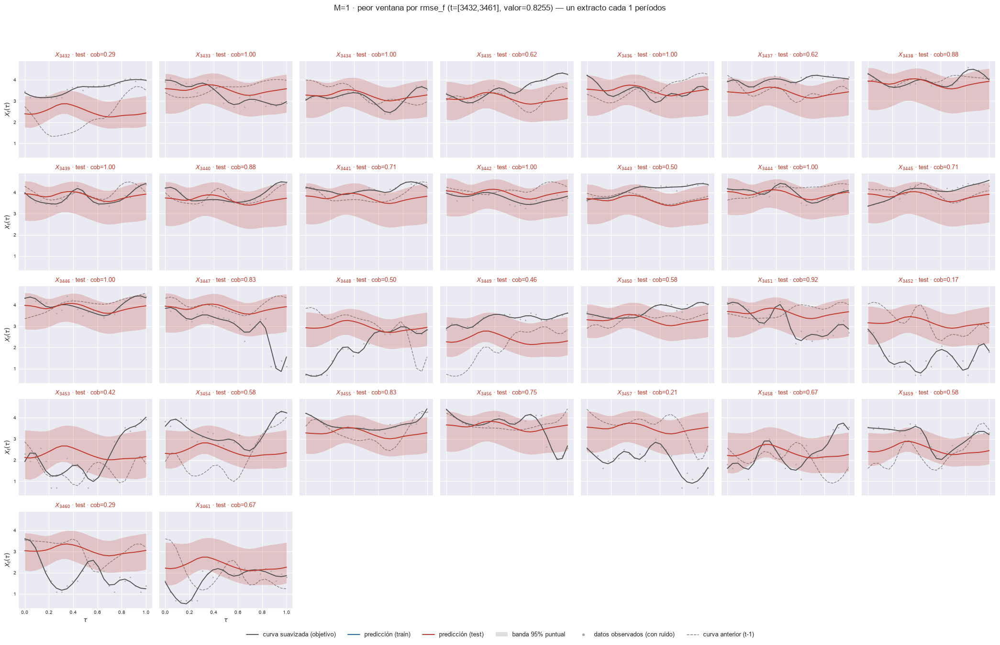

    t=[3445, 3474]  rmse_f=0.822658


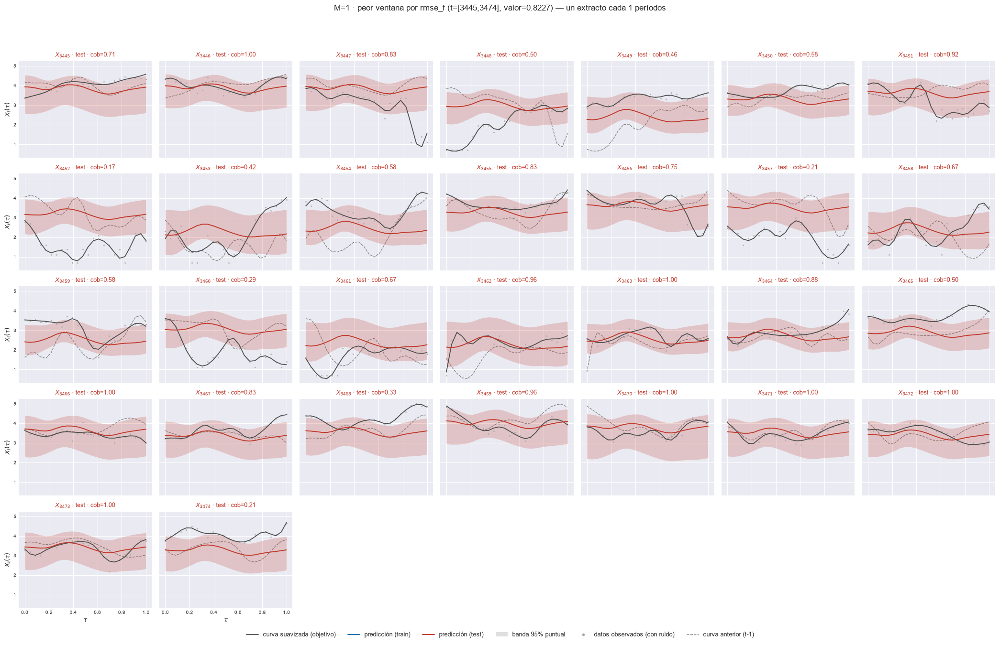

    t=[3447, 3476]  rmse_f=0.822539


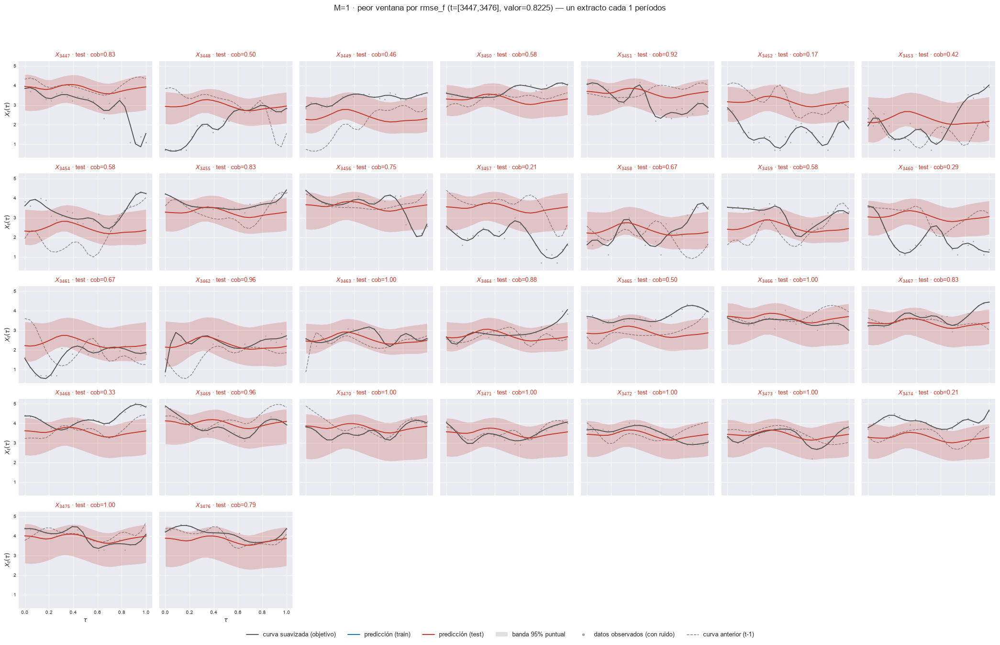

    t=[3446, 3475]  rmse_f=0.820873


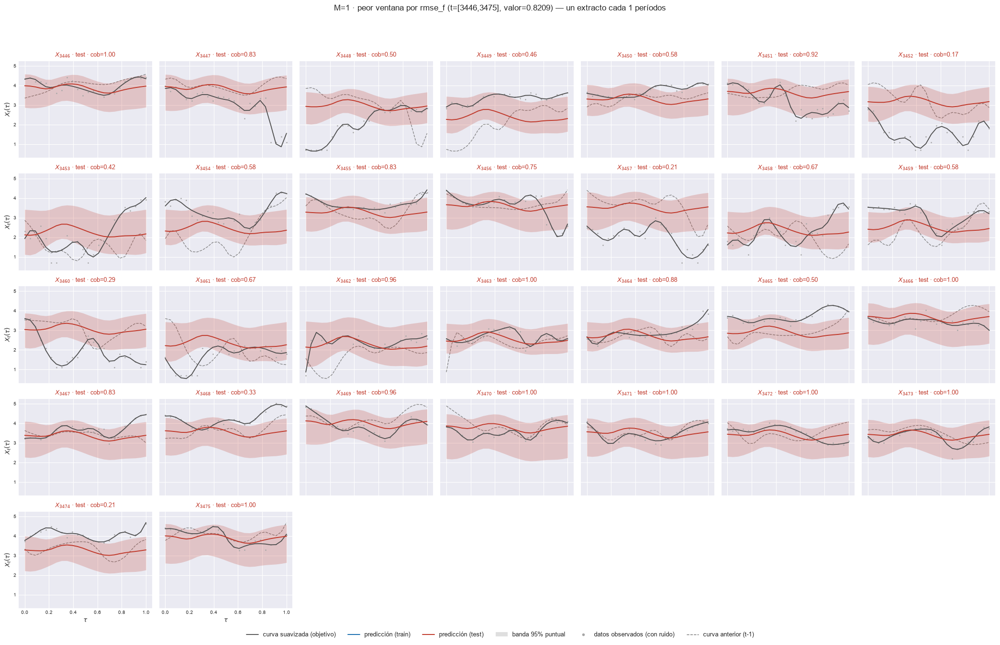

[M=2] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[3115, 3144]  rmse_f=0.743159


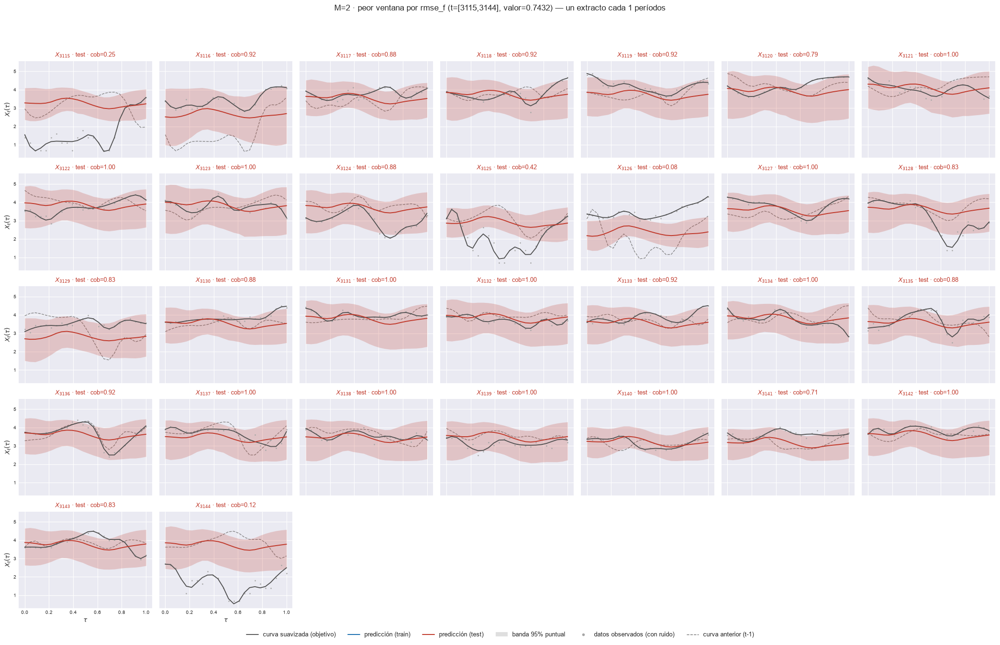

    t=[3431, 3460]  rmse_f=0.737684


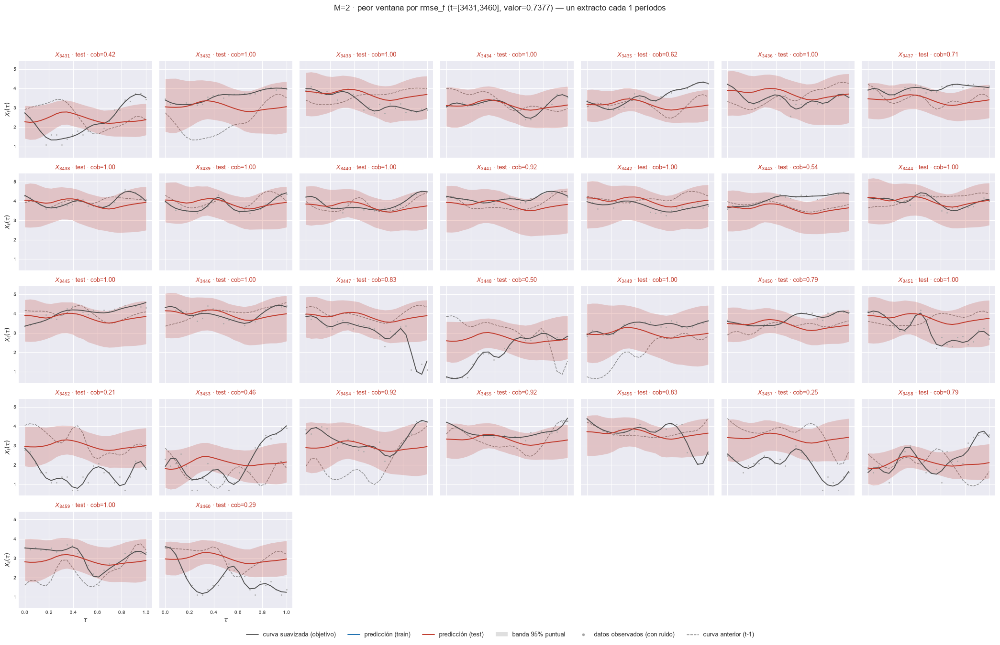

    t=[3447, 3476]  rmse_f=0.733589


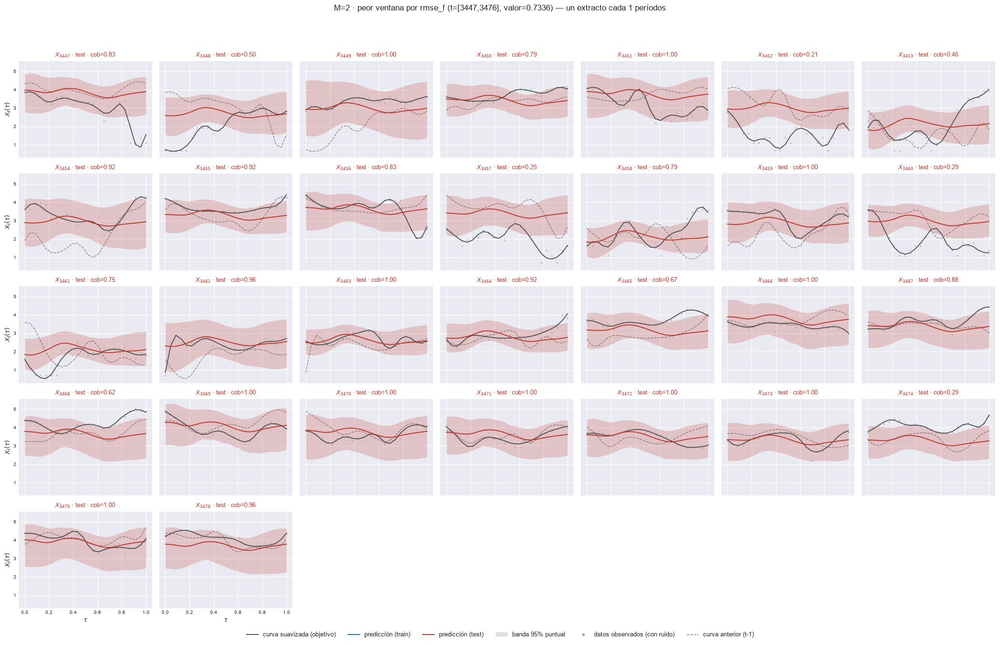

    t=[3445, 3474]  rmse_f=0.733034


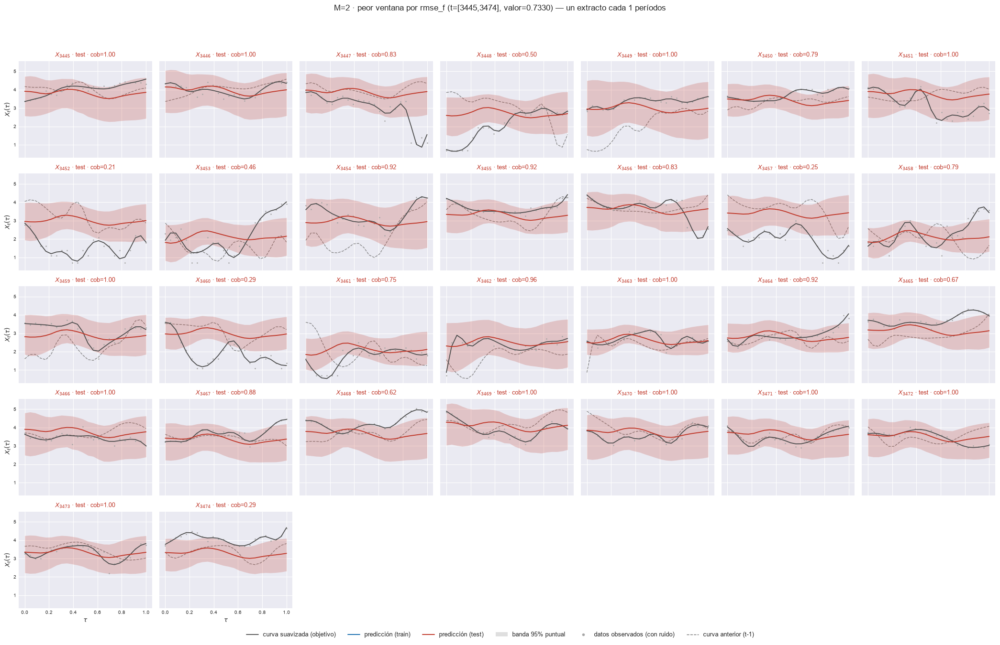

    t=[3446, 3475]  rmse_f=0.730195


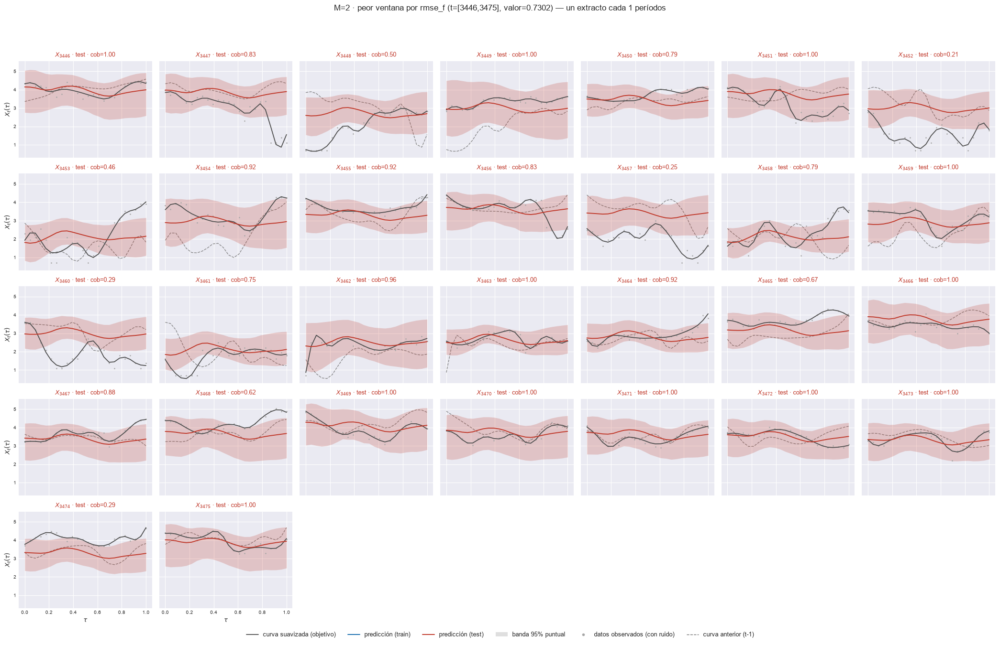

[M=3] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[3447, 3476]  rmse_f=0.713300


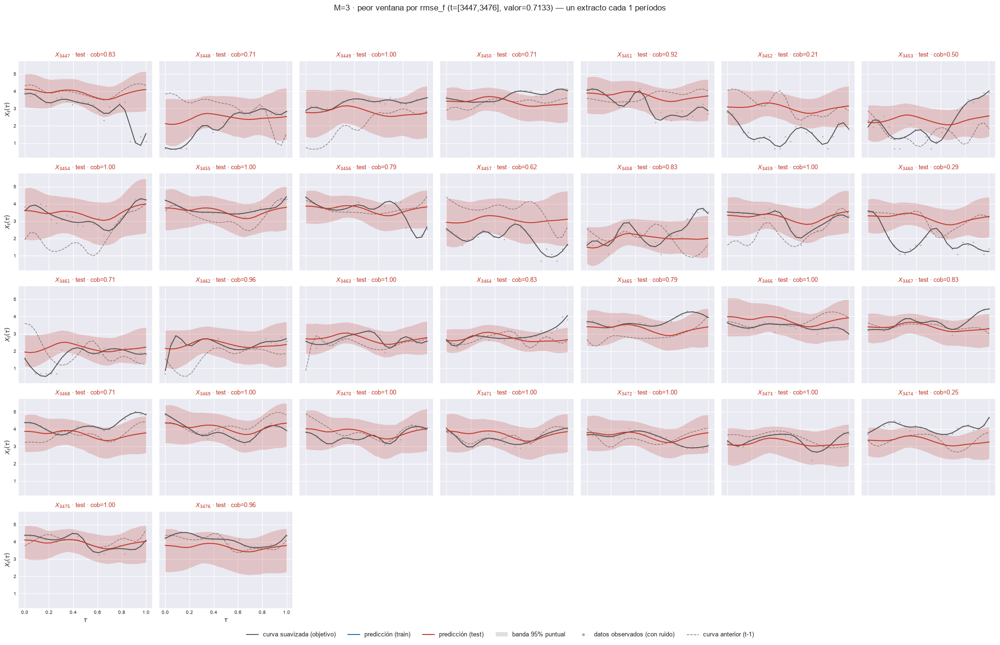

    t=[3445, 3474]  rmse_f=0.712939


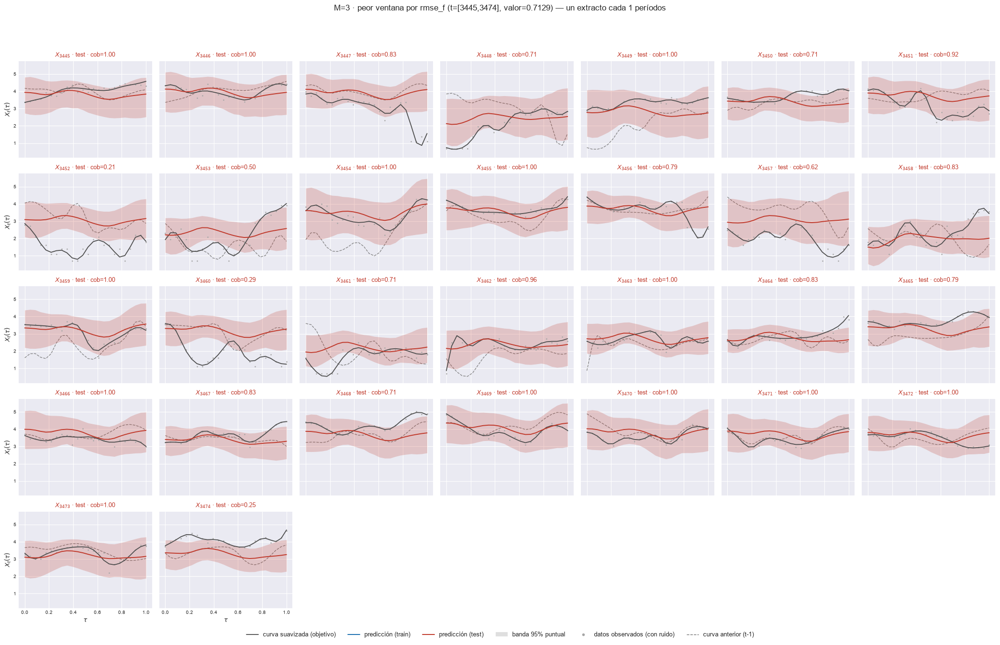

    t=[3446, 3475]  rmse_f=0.709892


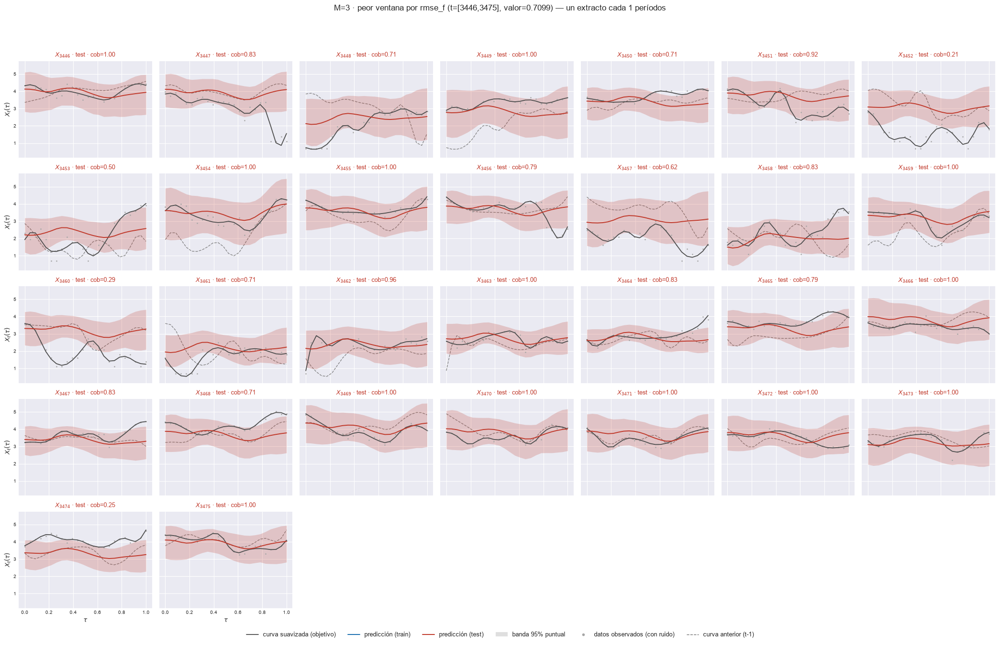

    t=[3431, 3460]  rmse_f=0.706802


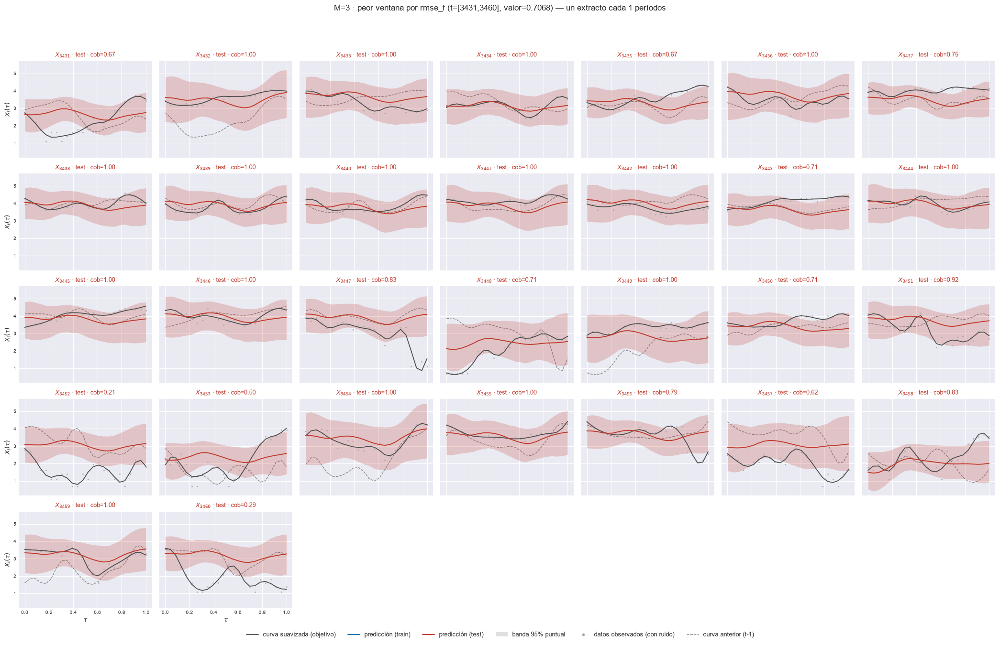

    t=[3443, 3472]  rmse_f=0.705059


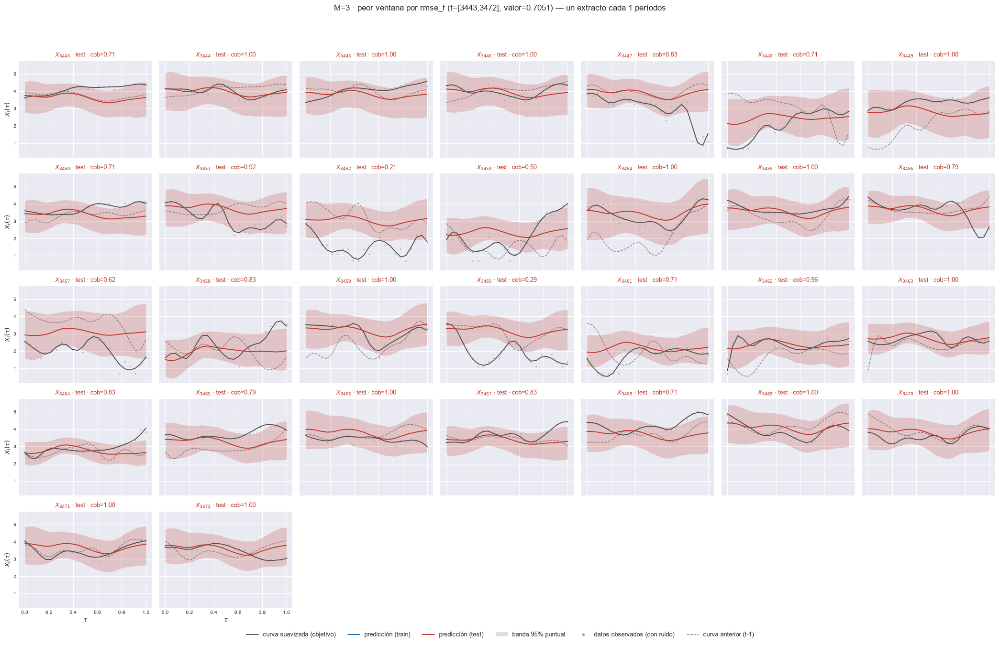

[M=4] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[3431, 3460]  rmse_f=0.697825


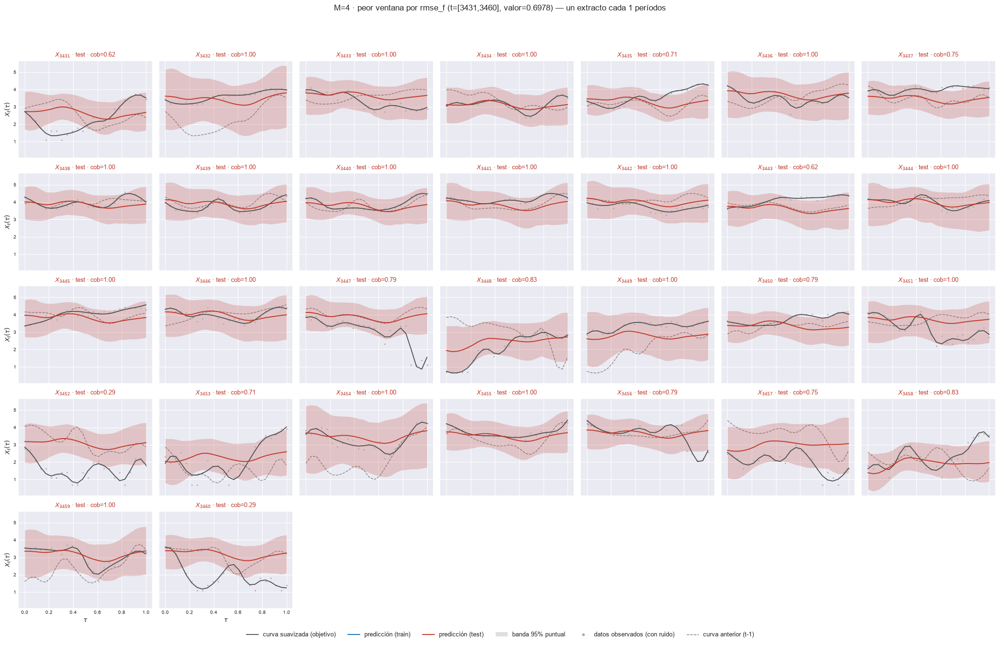

    t=[3445, 3474]  rmse_f=0.697576


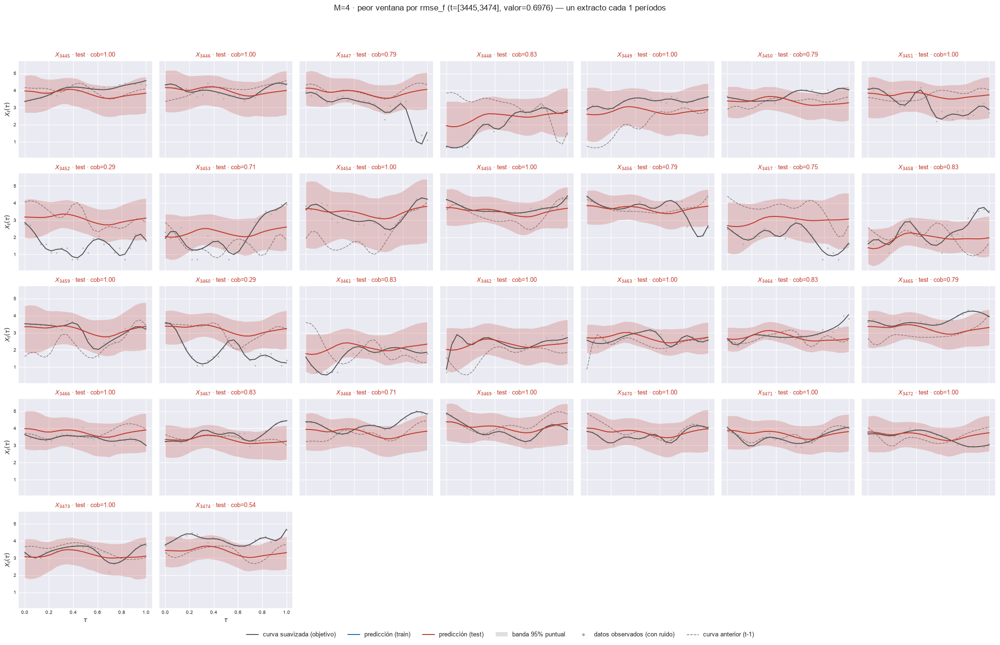

    t=[3447, 3476]  rmse_f=0.697515


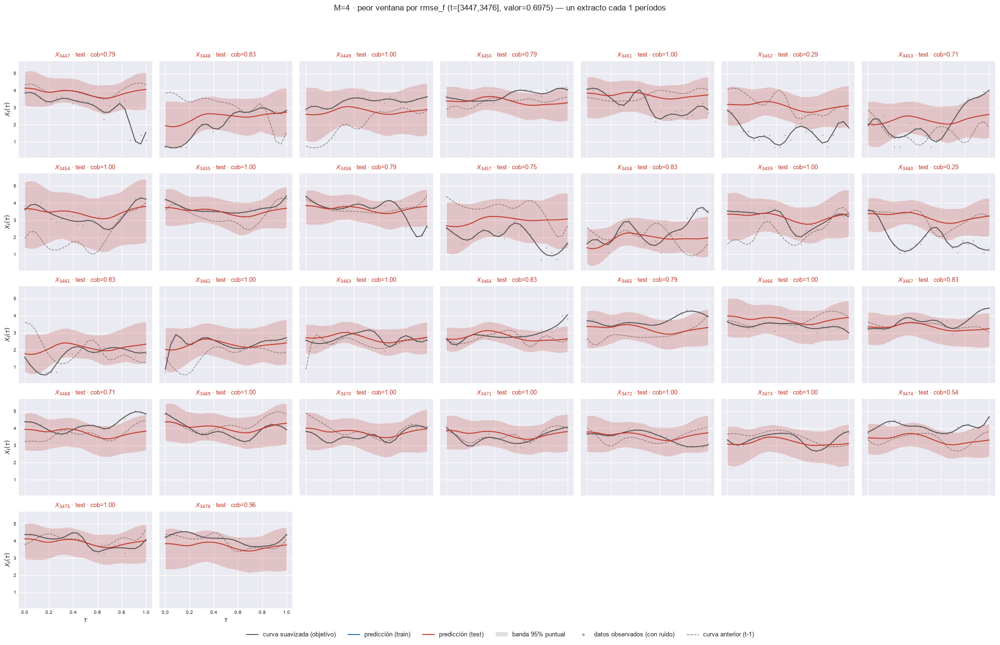

    t=[3446, 3475]  rmse_f=0.694383


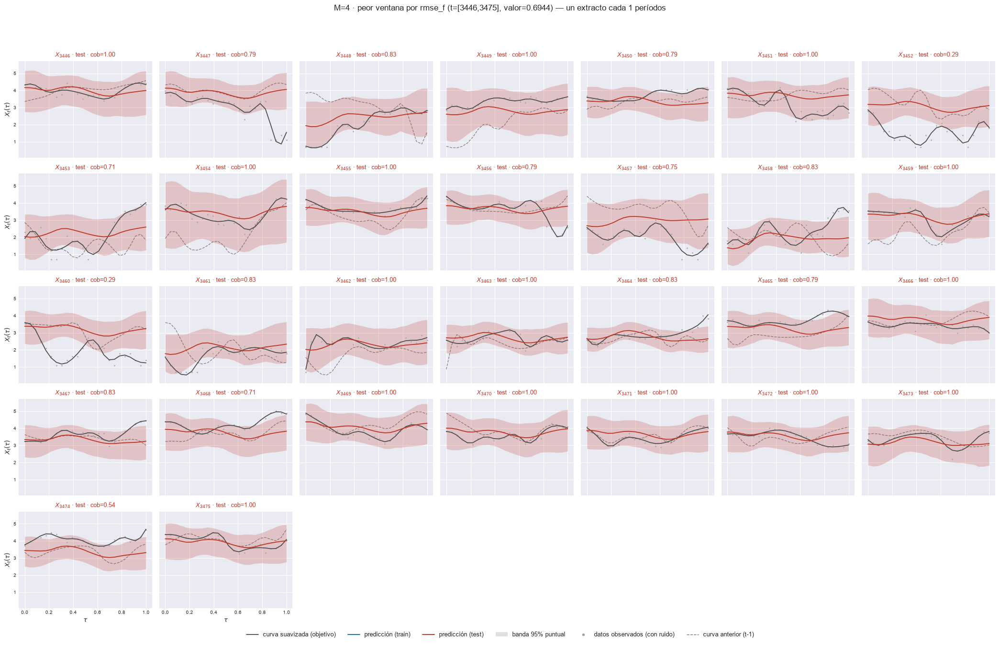

    t=[3443, 3472]  rmse_f=0.691541


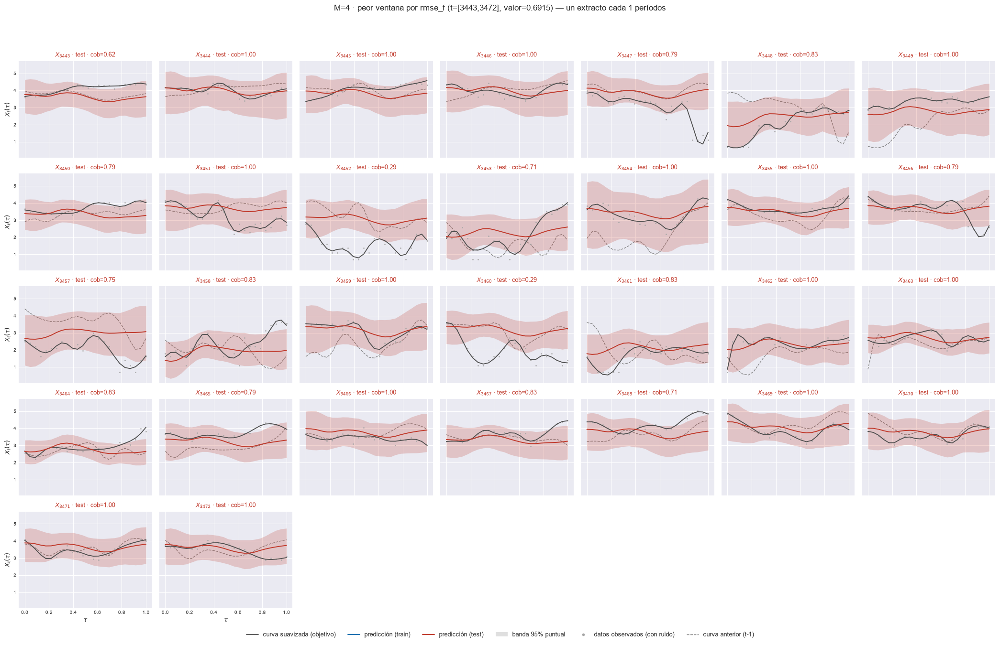

[M=5] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[3445, 3474]  rmse_f=0.687872


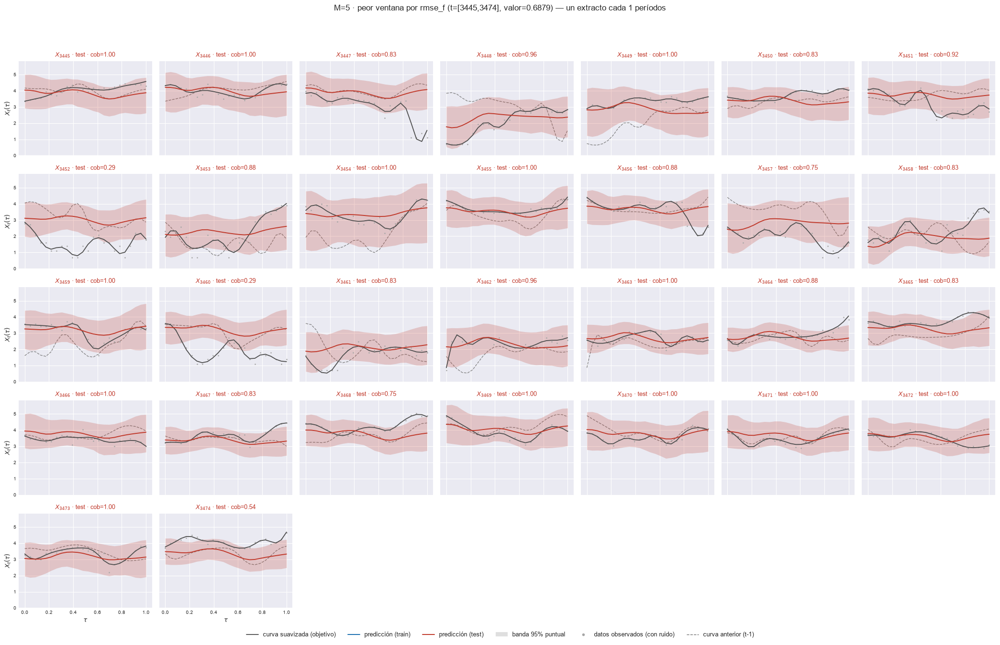

    t=[3447, 3476]  rmse_f=0.687742


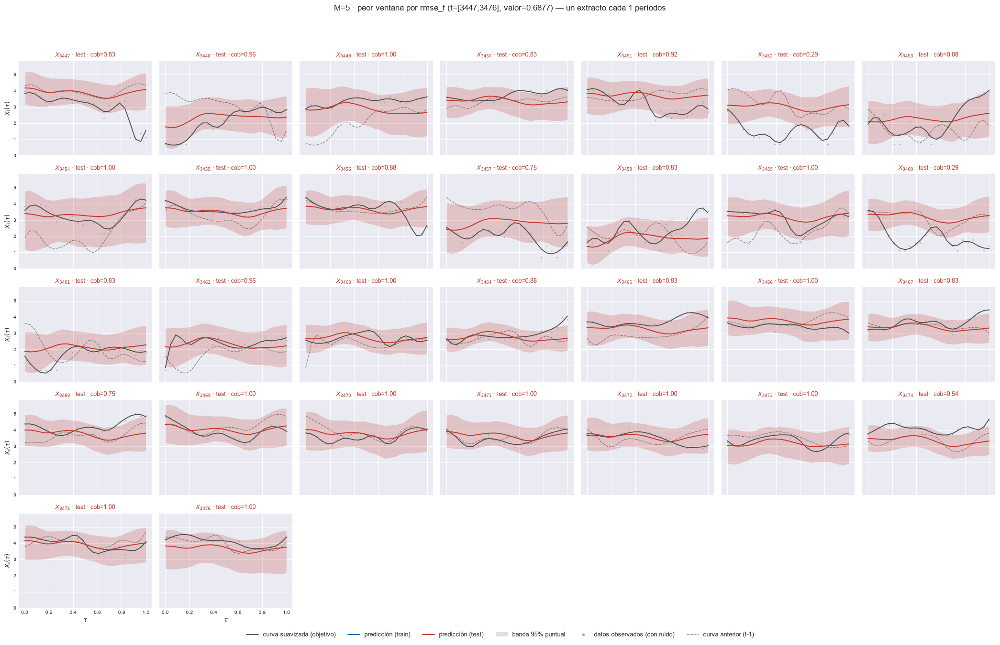

    t=[3431, 3460]  rmse_f=0.687095


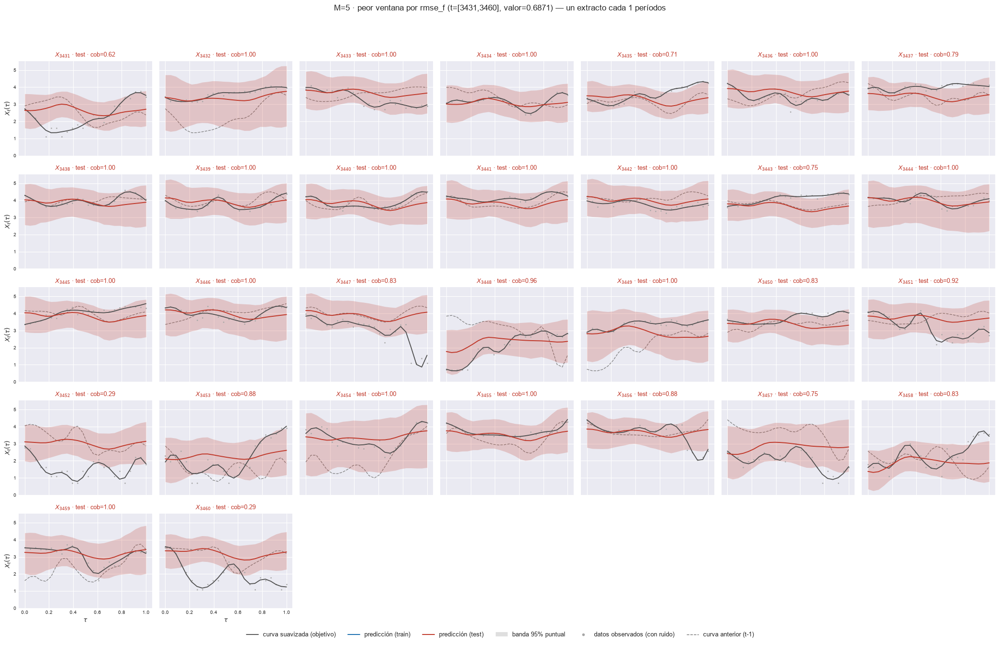

    t=[3446, 3475]  rmse_f=0.684311


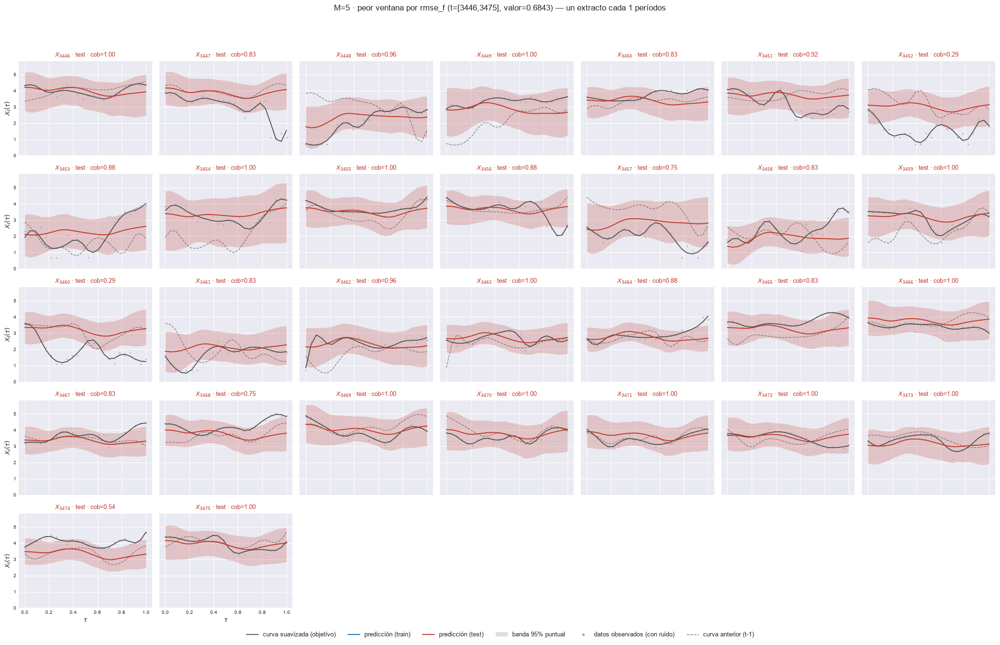

    t=[3443, 3472]  rmse_f=0.680706


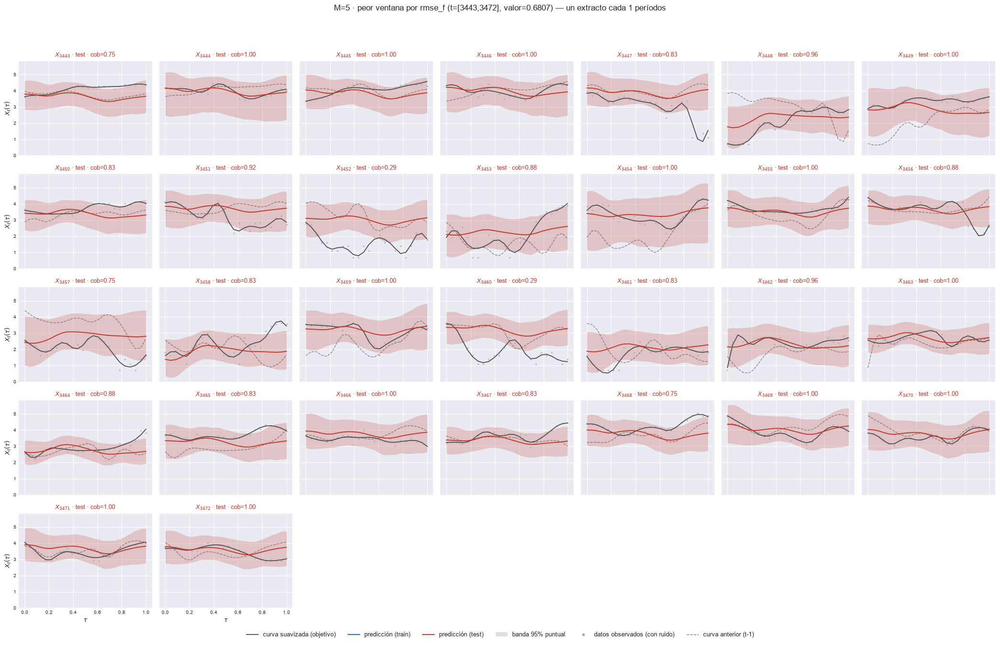

[M=6] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[3431, 3460]  rmse_f=0.684935


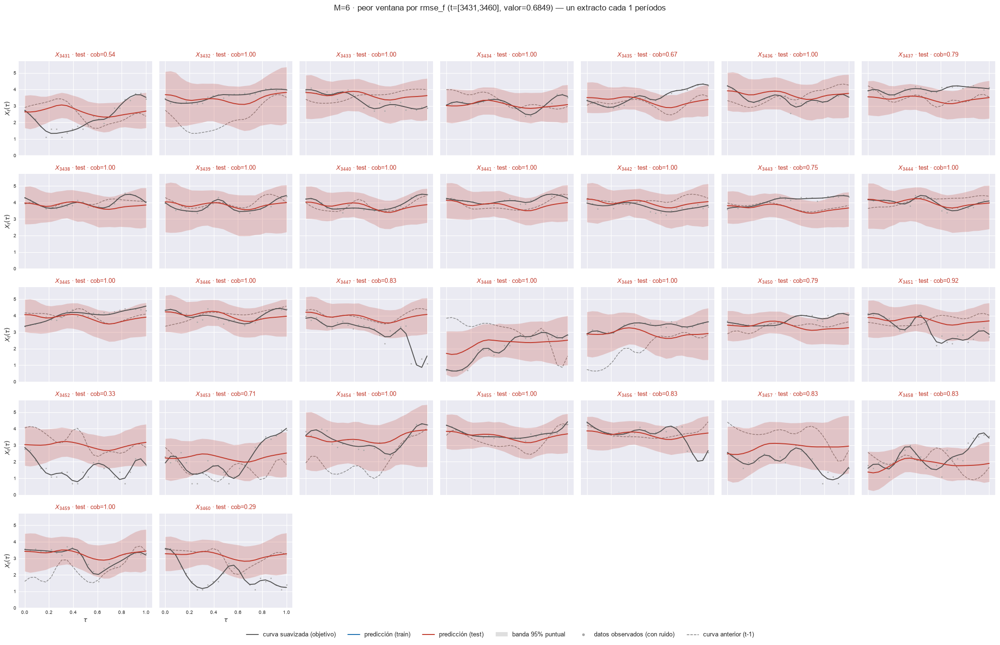

    t=[3445, 3474]  rmse_f=0.684056


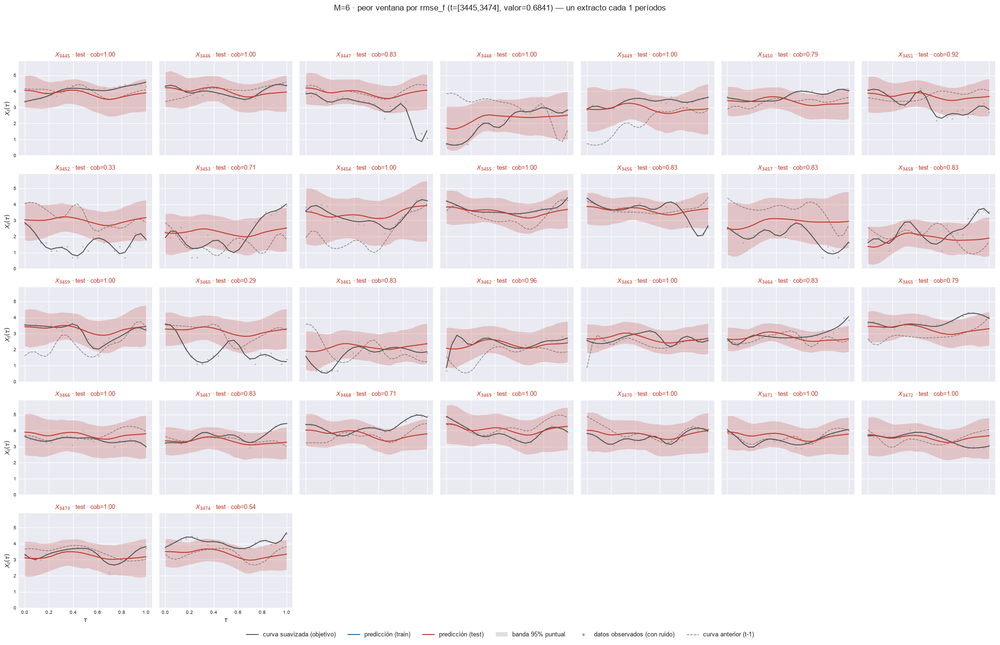

    t=[3447, 3476]  rmse_f=0.683960


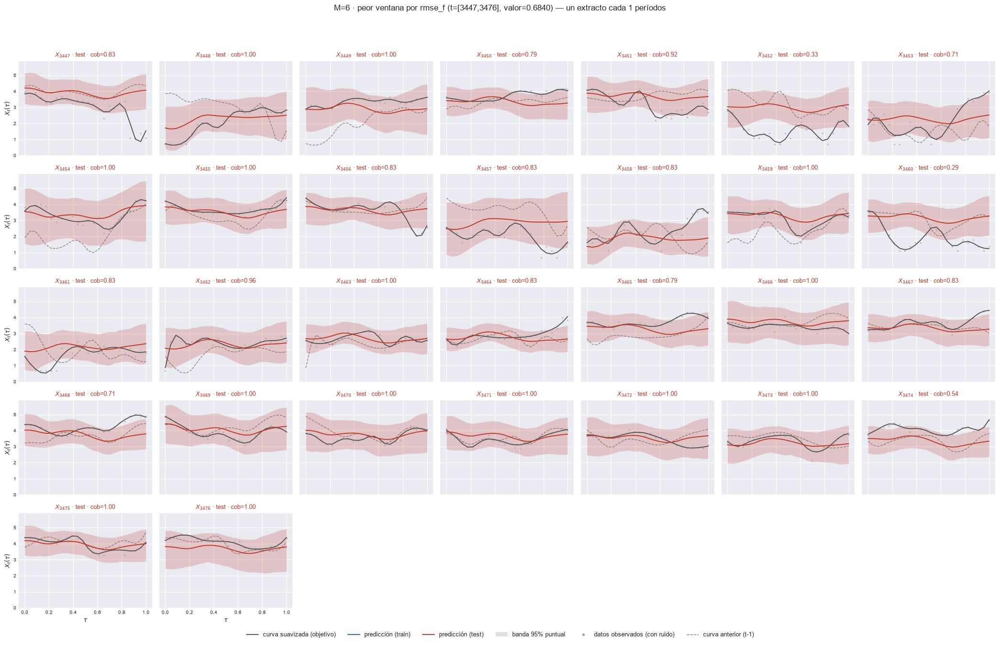

    t=[3446, 3475]  rmse_f=0.680437


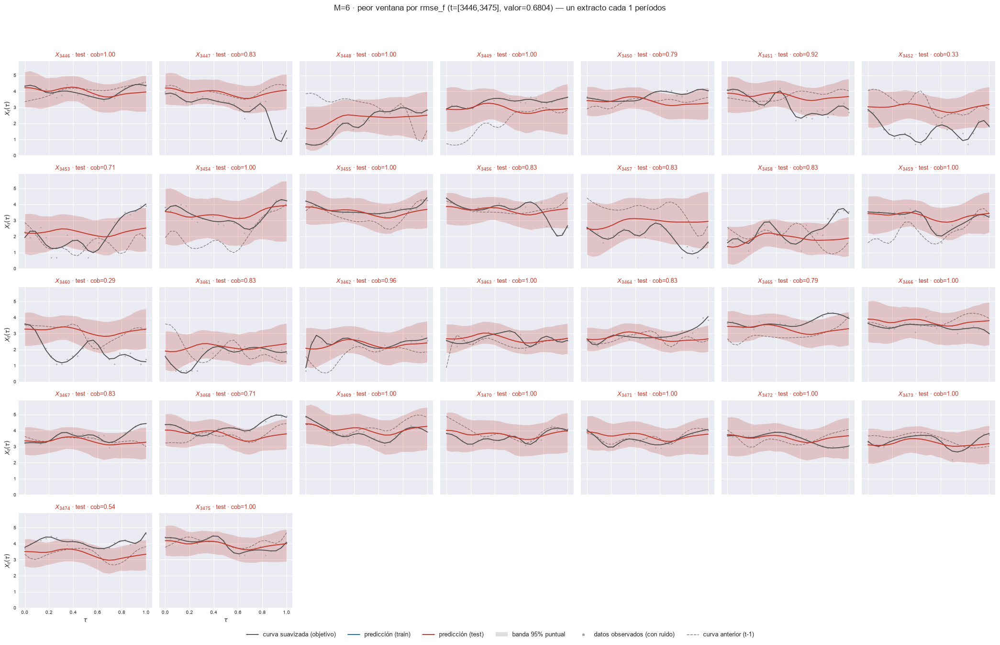

    t=[3443, 3472]  rmse_f=0.677154


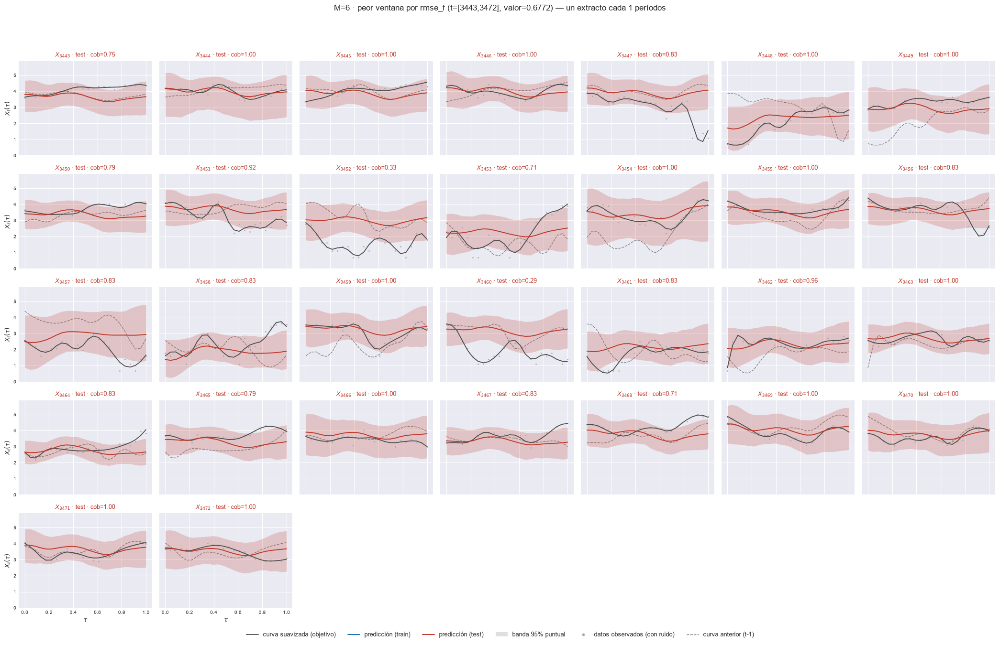

In [17]:
# Peores ventanas de test, con la curva anterior (t-1) al lado.
X_prev_full = np.full_like(X_obj_ev, np.nan)
X_prev_full[1:] = X_obj_ev[:-1]

for M in M_OK:
    e = EST[M]
    peores = peores_ventanas(e, W_REF, METRICA_PEORES, N_PEORES)
    print(f"[M={M}] peores {len(peores)} ventanas por {METRICA_PEORES} (w={W_REF}, test, sin cruzar T0)")
    for _, row in peores.iterrows():
        ini, fin = int(row["t_ini"]), int(row["t_fin"])
        print(f"    t=[{ini}, {fin}]  {METRICA_PEORES}={row[METRICA_PEORES]:.6f}")
        sel = np.where((t_orig >= ini) & (t_orig <= fin))[0]
        if sel.size == 0:
            continue
        plot_extractos_curvas(
            X_obj_ev[sel], e["X_pred"][sel], e["li_f"][sel], e["ls_f"][sel], grilla, T0,
            t=t_orig[sel], cada=1, n_col=min(len(sel), 7), nivel=NIVEL,
            etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[sel],
            X_prev=X_prev_full[sel],
            title=f"M={M} · peor ventana por {METRICA_PEORES} (t=[{ini},{fin}], "
                  f"valor={row[METRICA_PEORES]:.4f})",
            save_path=str(e["paths"]["out_report"] / f"56b_peor_ventana_{METRICA_PEORES}_t{ini}.png"),
            verbose=False)
        plt.show()

## 7. Probabilidades posteriores de inclusión (PIP)

PIP global por covariable: el rezago 1 de cada score, propio y cruzados. Sin soporte verdadero contra el cual contrastar y, con una cadena, sin dispersión entre cadenas. La lectura que importa en la 104 es qué scores rezagados gobiernan cada componente; en la 28 la media era casi lineal y lo que importaba era la heterocedasticidad de $\xi_1$ (candidato tipo GARCH, como la 301).


In [18]:
for M in M_OK:
    pip_df = pip_punto(EST[M], SD_PIP_MAX)
    display(pip_df.style
        .background_gradient(subset=[c for c in pip_df.columns if not c.endswith("_sd")],
                             cmap="RdYlGn", vmin=0, vmax=1)
        .format("{:.3f}")
        .set_caption(f"M={M} · P(gamma_j = 1 | datos), inclusión global, media entre cadenas ± sd"))

[matriz_pip] inicio (1 pasos)


  1/1 (100.0%) t=0.0s eta=0.0s  FPC 1: 1 cadenas, 1 variables, PIP en [1.000, 1.000]


[matriz_pip] listo: 1 pasos en 0.0s  tabla 1x2


[M=1] dispersion maxima entre cadenas: 0.000   OK las cadenas coinciden


,FPC 1,FPC 1_sd
variable,,
fpc_1_lag1,1.000,0.000


...

  5/6 (83.3%) t=0.0s eta=0.0s  FPC 5: 1 cadenas, 6 variables, PIP en [0.064, 1.000]


  6/6 (100.0%) t=0.0s eta=0.0s  FPC 6: 1 cadenas, 6 variables, PIP en [0.093, 1.000]


[matriz_pip] listo: 6 pasos en 0.0s  tabla 6x12


[M=6] dispersion maxima entre cadenas: 0.000   OK las cadenas coinciden


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd
variable,,,,,,,,,,,,
fpc_1_lag1,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000
fpc_2_lag1,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000
fpc_3_lag1,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,0.098,0.000,0.110,0.000
fpc_4_lag1,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,0.068,0.000,0.093,0.000
fpc_5_lag1,0.119,0.000,0.111,0.000,0.848,0.000,0.039,0.000,1.000,0.000,0.117,0.000
fpc_6_lag1,1.000,0.000,1.000,0.000,0.076,0.000,0.055,0.000,0.064,0.000,1.000,0.000


## 8. Cuadro resumen: mínimo, máximo y promedio

Por métrica y bloque train/test, sin las ventanas que cruzan $T_0$.

In [19]:
# Los dos objetivos, los cuatro predictores y los tres intervalos en 66_metricas_resumen.csv (por M) y 89_resumen_por_M.csv.
for M in M_OK:
    resumen_metricas(EST[M], M, DIS, ORIG)
resumen_bar = resumen_barrido(EST, M_OK, PATH_BARRIDO)

_esp = resumen_bar[(resumen_bar.bloque == "test") & (resumen_bar.objetivo == "curva_suavizada")
                   & (resumen_bar.predictor == "esperanza") & (resumen_bar.intervalo == "equicolas")]
display(_esp.pivot(index="metrica", columns="M", values="promedio").style.format("{:.6f}")
        .set_caption("Esperanza · promedio en TEST contra M, objetivo=curva_suavizada (89_resumen_por_M.csv)"))

[M=1] curva_suavizada      PICP puntual test = 0.8712 (nominal 0.95)  ·  PICP simultaneo test = 0.4893


[M=1] representacion_fpca  PICP puntual test = 0.9372 (nominal 0.95)  ·  PICP simultaneo test = 0.9372


[M=2] curva_suavizada      PICP puntual test = 0.9030 (nominal 0.95)  ·  PICP simultaneo test = 0.5479


[M=2] representacion_fpca  PICP puntual test = 0.9401 (nominal 0.95)  ·  PICP simultaneo test = 0.8747


[M=3] curva_suavizada      PICP puntual test = 0.9213 (nominal 0.95)  ·  PICP simultaneo test = 0.6058


...

[M=5] curva_suavizada      PICP puntual test = 0.9332 (nominal 0.95)  ·  PICP simultaneo test = 0.6490


[M=5] representacion_fpca  PICP puntual test = 0.9432 (nominal 0.95)  ·  PICP simultaneo test = 0.7840


[M=6] curva_suavizada      PICP puntual test = 0.9357 (nominal 0.95)  ·  PICP simultaneo test = 0.6612


[M=6] representacion_fpca  PICP puntual test = 0.9428 (nominal 0.95)  ·  PICP simultaneo test = 0.7593


M,1,2,3,4,5,6
metrica,,,,,,
1. MAE (L^1),0.355666,0.338077,0.327053,0.323665,0.322845,0.320915
10. Winkler max peor ventana,50.368941,47.196319,45.613157,44.971510,44.430362,43.952500
2. RMSE (L^2),0.479064,0.455645,0.442658,0.438538,0.437032,0.435198
3. E_max promedio por curva,0.837522,0.810184,0.787698,0.781856,0.780514,0.778519
4. E_max peor de la ventana,2.002127,1.950218,1.954757,1.957261,1.951122,1.961409
5. MPIW,1.475379,1.510521,1.546860,1.594635,1.632270,1.653995
6. PICP puntual,0.871234,0.902965,0.921315,0.929427,0.933217,0.935685
7. PICPB curva completa,0.489347,0.547923,0.605842,0.637113,0.649047,0.661231
8. Winkler,3.169767,2.744391,2.560769,2.499133,2.480133,2.465470


### 8.1 Bloque A por predictor

Promedio en test por predictor y $M$ (`101_*`); cambio relativo contra la esperanza.

M,1,2,3,4,5,6
predictor,,,,,,
esperanza,0.3557,0.3381,0.3271,0.3237,0.3228,0.3209
mediana,0.3539,0.3376,0.3270,0.3238,0.3226,0.3215
medoide,0.3538,0.3377,0.3277,0.3258,0.3272,0.3268
modal,0.3566,0.3482,0.3351,0.3339,0.3311,0.3344


M,1,2,3,4,5,6
predictor,,,,,,
esperanza,0.4791,0.4556,0.4427,0.4385,0.4370,0.4352
mediana,0.4784,0.4561,0.4438,0.4399,0.4380,0.4370
medoide,0.4784,0.4564,0.4444,0.4421,0.4426,0.4428
modal,0.4818,0.4702,0.4556,0.4579,0.4512,0.4552


M,1,2,3,4,5,6
predictor,,,,,,
esperanza,0.8375,0.8102,0.7877,0.7819,0.7805,0.7785
mediana,0.8341,0.8094,0.7877,0.7823,0.7814,0.7799
medoide,0.8341,0.8095,0.7893,0.7847,0.7903,0.7932
modal,0.8359,0.8252,0.8038,0.8029,0.8000,0.8064


M,1,2,3,4,5,6
predictor,,,,,,
esperanza,2.0021,1.9502,1.9548,1.9573,1.9511,1.9614
mediana,2.0114,1.9606,1.9565,1.9648,1.9587,1.9720
medoide,2.0113,1.9639,1.9589,1.9606,1.9703,1.9673
modal,2.0309,2.0127,1.9974,2.0262,2.0029,2.0372


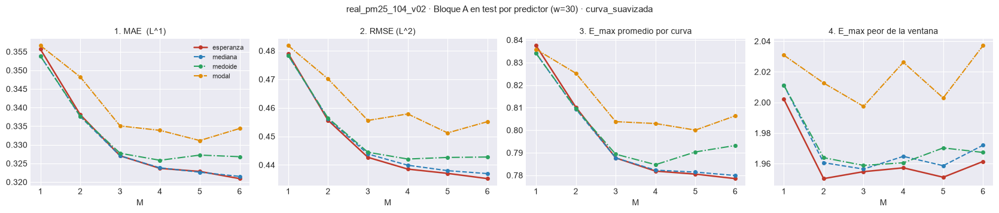

M,1,2,3,4,5,6
predictor,,,,,,
esperanza,0.2590,0.2829,0.2912,0.3000,0.3073,0.3109
mediana,0.2563,0.2819,0.2912,0.3001,0.3072,0.3115
medoide,0.2563,0.2821,0.2922,0.3023,0.3119,0.3171
modal,0.2589,0.2945,0.3003,0.3110,0.3161,0.3249


M,1,2,3,4,5,6
predictor,,,,,,
esperanza,0.3454,0.3797,0.3946,0.4064,0.4148,0.4202
mediana,0.3439,0.3801,0.3959,0.4079,0.4158,0.4220
medoide,0.3439,0.3806,0.3966,0.4102,0.4207,0.4281
modal,0.3481,0.3972,0.4090,0.4271,0.4297,0.4409


M,1,2,3,4,5,6
predictor,,,,,,
esperanza,0.2998,0.4896,0.5643,0.6114,0.6420,0.6773
mediana,0.2968,0.4887,0.5643,0.6125,0.6426,0.6787
medoide,0.2968,0.4887,0.5657,0.6142,0.6539,0.6944
modal,0.2997,0.5060,0.5800,0.6342,0.6627,0.7056


M,1,2,3,4,5,6
predictor,,,,,,
esperanza,1.0938,1.4058,1.5299,1.6255,1.6495,1.7253
mediana,1.0976,1.4147,1.5352,1.6335,1.6643,1.7388
medoide,1.0975,1.4181,1.5412,1.6322,1.6838,1.7407
modal,1.1062,1.4914,1.6022,1.7218,1.7307,1.7937


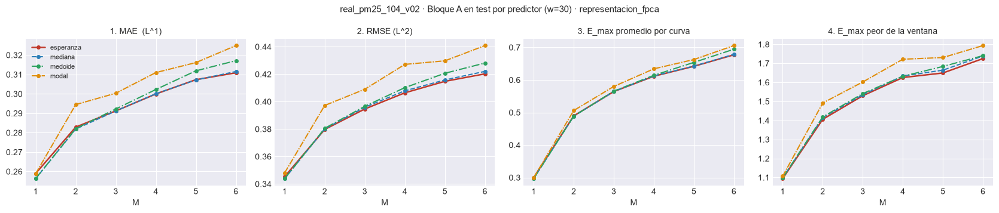

In [20]:
for objetivo in ("curva_suavizada", "representacion_fpca"):
    TAB_PRED = tabla_predictores(resumen_bar, PATH_BARRIDO, objetivo=objetivo)
    for etiqueta, col in METRICAS_A:
        display(TAB_PRED.loc[col].style.format("{:.4f}").highlight_min(axis=0, props="font-weight: bold")
                .set_caption(f"{etiqueta} · TEST · objetivo={objetivo}"))
    rel = TAB_PRED.div(TAB_PRED.xs("esperanza", level="predictor"), level="columna") - 1
    display(rel.style.format("{:+.1%}").background_gradient(cmap="RdYlGn_r", vmin=-0.1, vmax=0.1)
            .set_caption(f"Cambio relativo contra la esperanza · TEST · objetivo={objetivo}"))
    plot_predictores_vs_M(TAB_PRED, METRICAS_A,
                          f"{EXPERIMENT_BASE} · Bloque A en test por predictor (w={W_REF}) · {objetivo}",
                          save_path=PATH_BARRIDO / f"101_bloqueA_predictores_vs_M_{objetivo}.png")
    plt.show()

### 8.2 Bloque B por intervalo

Seis métricas en test por construcción y $M$ (`110_*`), con la esperanza.

M,1,2,3,4,5,6
intervalo,,,,,,
equicolas,1.4754,1.5105,1.5469,1.5946,1.6323,1.6540
simultanea,1.4836,1.8471,2.0228,2.1618,2.2612,2.3240
hdr,1.4346,1.4871,1.5365,1.5896,1.6296,1.6499


M,1,2,3,4,5,6
intervalo,,,,,,
equicolas,0.8712,0.9030,0.9213,0.9294,0.9332,0.9357
simultanea,0.8886,0.9428,0.9615,0.9688,0.9736,0.9763
hdr,0.8805,0.9032,0.9207,0.9282,0.9330,0.9351


M,1,2,3,4,5,6
intervalo,,,,,,
equicolas,0.4893,0.5479,0.6058,0.6371,0.6490,0.6612
simultanea,0.5512,0.7166,0.8017,0.8376,0.8574,0.8686
hdr,0.5225,0.5599,0.6065,0.6418,0.6580,0.6706


M,1,2,3,4,5,6
intervalo,,,,,,
equicolas,3.1698,2.7444,2.5608,2.4991,2.4801,2.4655
simultanea,3.1176,2.6563,2.5622,2.5862,2.6215,2.6437
hdr,3.1272,2.7621,2.5957,2.5344,2.5057,2.4942


M,1,2,3,4,5,6
intervalo,,,,,,
equicolas,10.3012,8.6044,7.6479,7.2141,6.9580,6.8037
simultanea,9.5620,6.7430,5.7865,5.3053,5.0913,4.9806
hdr,10.0309,8.6468,7.7709,7.2717,7.0081,6.8825


M,1,2,3,4,5,6
intervalo,,,,,,
equicolas,50.3689,47.1963,45.6132,44.9715,44.4304,43.9525
simultanea,50.6662,42.2099,37.6171,35.1940,33.4114,32.3589
hdr,51.5864,48.8452,46.7487,45.8842,44.9422,44.7339


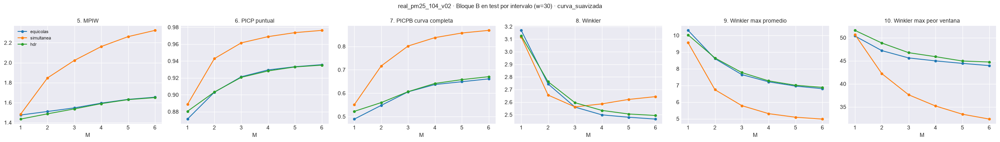

M,1,2,3,4,5,6
intervalo,,,,,,
equicolas,1.4754,1.5105,1.5469,1.5946,1.6323,1.6540
simultanea,1.4836,1.8471,2.0228,2.1618,2.2612,2.3240
hdr,1.4346,1.4871,1.5365,1.5896,1.6296,1.6499


M,1,2,3,4,5,6
intervalo,,,,,,
equicolas,0.9372,0.9401,0.9444,0.9449,0.9432,0.9428
simultanea,0.9438,0.9651,0.9725,0.9760,0.9772,0.9788
hdr,0.9372,0.9391,0.9432,0.9435,0.9429,0.9418


M,1,2,3,4,5,6
intervalo,,,,,,
equicolas,0.9372,0.8747,0.8423,0.8077,0.7840,0.7593
simultanea,0.9438,0.9283,0.9191,0.9108,0.9095,0.9098
hdr,0.9372,0.8802,0.8438,0.8115,0.7887,0.7641


M,1,2,3,4,5,6
intervalo,,,,,,
equicolas,2.0503,2.1488,2.2066,2.2806,2.3432,2.3741
simultanea,2.1351,2.2355,2.3392,2.4753,2.5622,2.6062
hdr,2.0629,2.1714,2.2349,2.3205,2.3718,2.4025


M,1,2,3,4,5,6
intervalo,,,,,,
equicolas,2.3737,3.3200,3.9775,4.5241,4.9089,5.3347
simultanea,2.4720,3.1704,3.6320,3.9904,4.1899,4.3426
hdr,2.3883,3.3904,4.0489,4.6266,4.9864,5.4295


M,1,2,3,4,5,6
intervalo,,,,,,
equicolas,14.4046,22.6008,26.7913,31.8212,33.1663,35.6171
simultanea,14.8560,17.6210,19.6241,23.5022,24.0336,25.5353
hdr,14.7163,23.1037,27.7326,32.2211,33.5669,36.7207


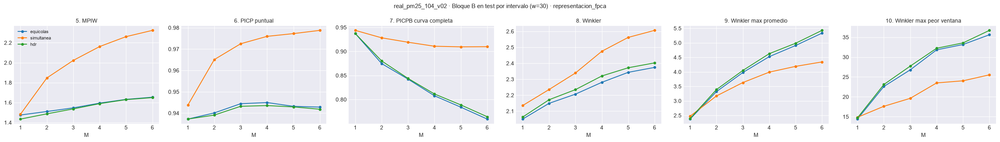

In [21]:
for objetivo in ("curva_suavizada", "representacion_fpca"):
    TAB_INT = tabla_intervalos(resumen_bar, PATH_BARRIDO, objetivo=objetivo)
    for etiqueta, col in METRICAS_B:
        display(TAB_INT.loc[col].style.format("{:.4f}")
                .set_caption(f"{etiqueta} · TEST · objetivo={objetivo}"))
    plot_predictores_vs_M(TAB_INT, METRICAS_B,
                          f"{EXPERIMENT_BASE} · Bloque B en test por intervalo (w={W_REF}) · {objetivo}",
                          save_path=PATH_BARRIDO / f"110_intervalos_vs_M_{objetivo}.png")
    plt.show()

## 9. Monitoreo univariado por componente FPCA

MAE, RMSE y MISE del score por componente sobre la ventana móvil. Solo monitoreo.

[ventana_movil_scores[FPC 1, w=30]] inicio (3988 pasos)


  1/3988 ( 0.0%) t=0.0s eta=4.0s  t=16 [train] rmse=0.1379


  199/3988 ( 5.0%) t=0.0s eta=0.3s  t=214 [train] rmse=0.4847


  398/3988 (10.0%) t=0.0s eta=0.2s  t=413 [train] rmse=0.1751


  597/3988 (15.0%) t=0.0s eta=0.2s  t=612 [train] rmse=0.2761


...

  3582/3988 (89.8%) t=0.3s eta=0.0s  t=3597 [test] rmse=0.2723


  3781/3988 (94.8%) t=0.3s eta=0.0s  t=3796 [test] rmse=0.4605


  3980/3988 (99.8%) t=0.3s eta=0.0s  t=3995 [test] rmse=0.2338


  3988/3988 (100.0%) t=0.3s eta=0.0s  t=4003 [test] rmse=0.2201


[ventana_movil_scores[FPC 1, w=30]] listo: 3988 pasos en 0.3s  29 ventanas cruzan T0


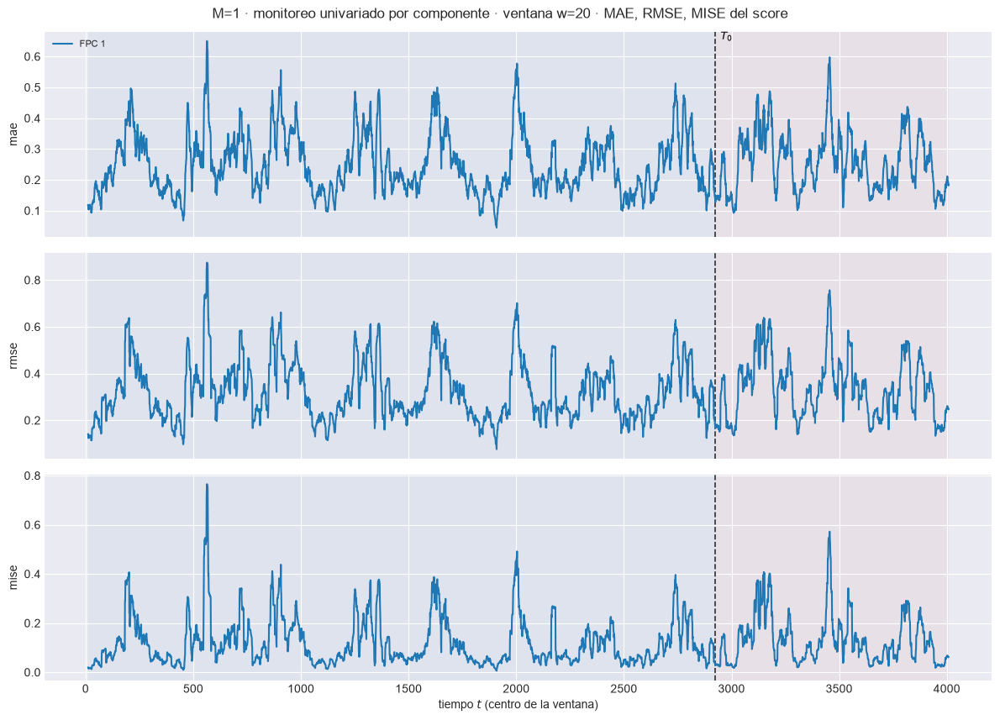

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.2365  w=30 test=0.2579


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.3104  w=30 test=0.3395


  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.09632  w=30 test=0.1152


[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_pm25_104_v02_m01\91_ventana_univariado_w30.png


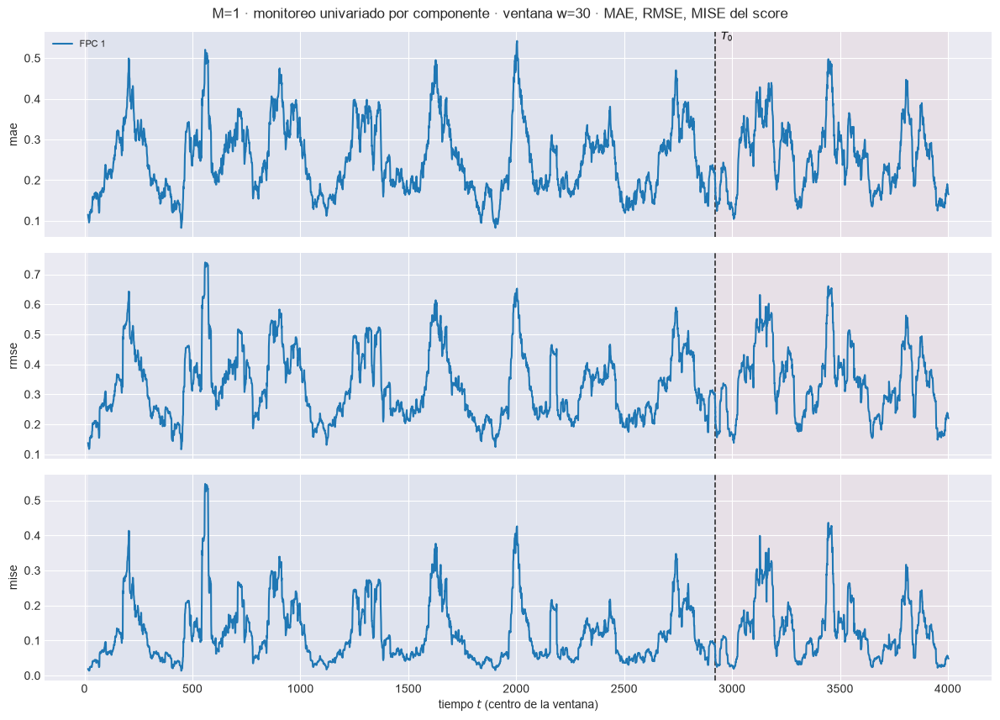

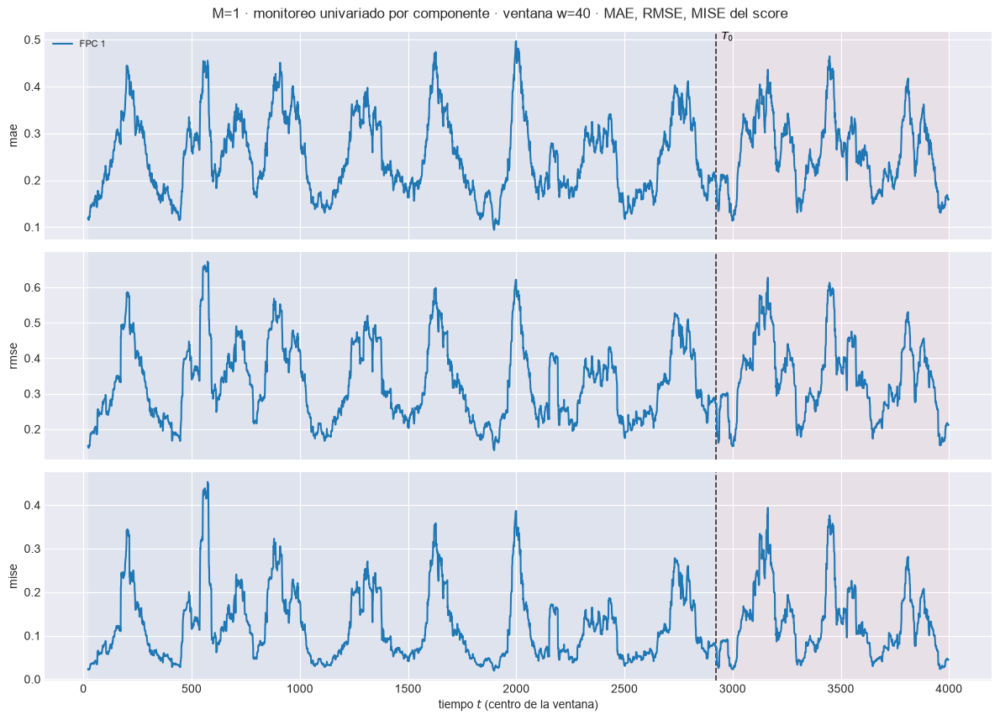

[ventana_movil_scores[FPC 1, w=30]] inicio (3988 pasos)


  1/3988 ( 0.0%) t=0.0s eta=3.4s  t=16 [train] rmse=0.1342


  199/3988 ( 5.0%) t=0.0s eta=0.3s  t=214 [train] rmse=0.4584


  398/3988 (10.0%) t=0.0s eta=0.3s  t=413 [train] rmse=0.1639


  597/3988 (15.0%) t=0.0s eta=0.2s  t=612 [train] rmse=0.2678


...

  3582/3988 (89.8%) t=0.5s eta=0.1s  t=3597 [test] rmse=0.1679


  3781/3988 (94.8%) t=0.6s eta=0.0s  t=3796 [test] rmse=0.2138


  3980/3988 (99.8%) t=0.6s eta=0.0s  t=3995 [test] rmse=0.2015


  3988/3988 (100.0%) t=0.6s eta=0.0s  t=4003 [test] rmse=0.1795


[ventana_movil_scores[FPC 2, w=30]] listo: 3988 pasos en 0.6s  29 ventanas cruzan T0


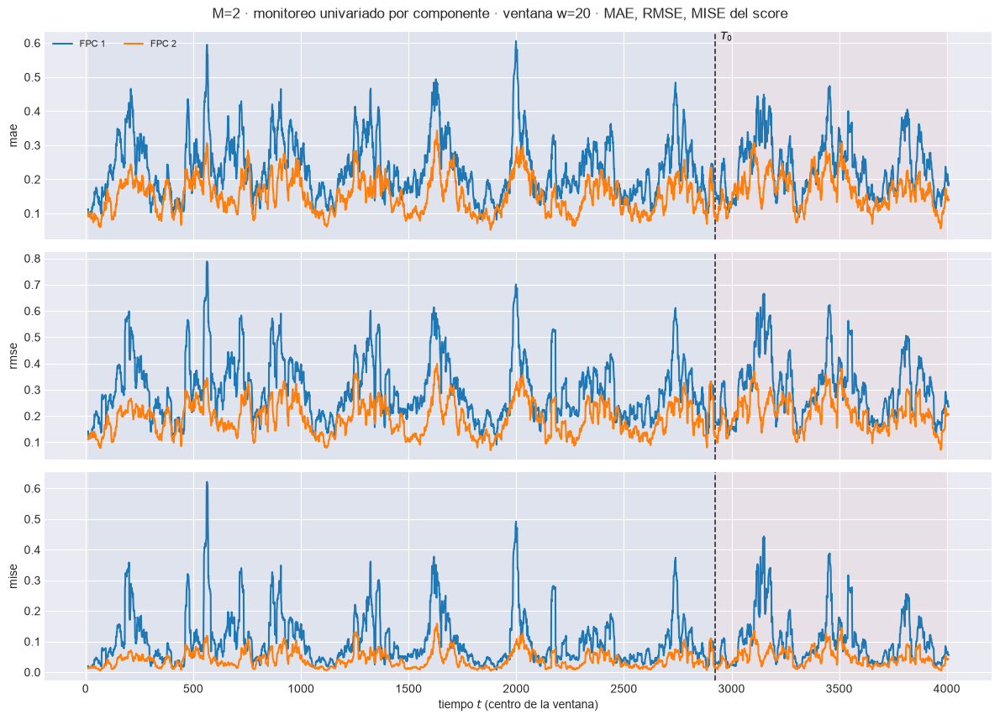

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.1799  w=30 test=0.1907


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.2298  w=30 test=0.2476


  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.05279  w=30 test=0.06133


[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_pm25_104_v02_m02\91_ventana_univariado_w30.png


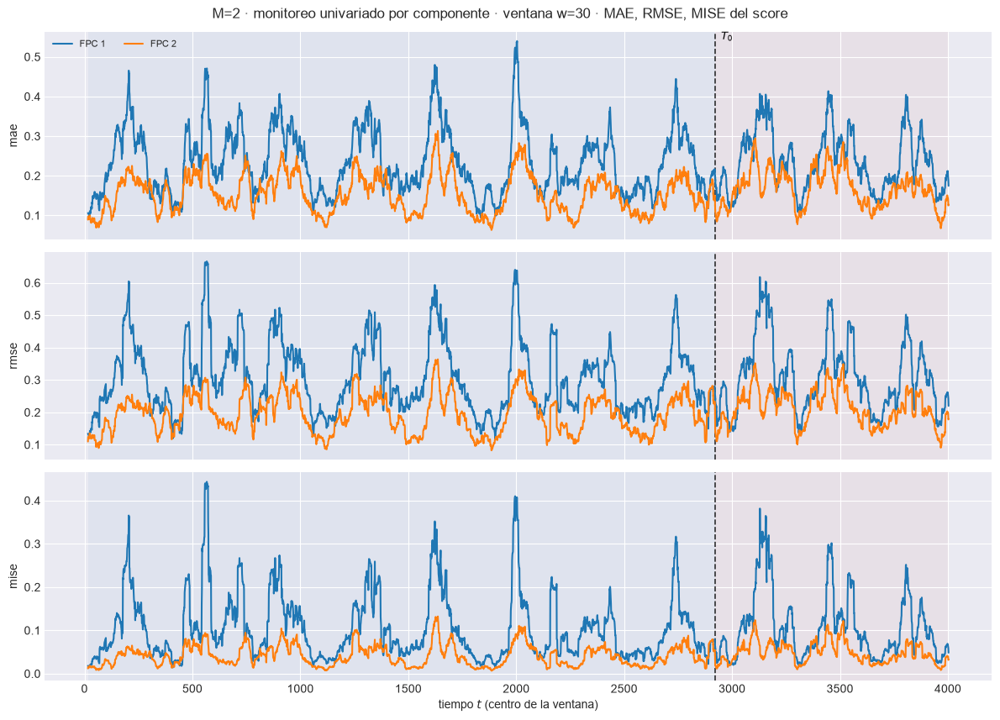

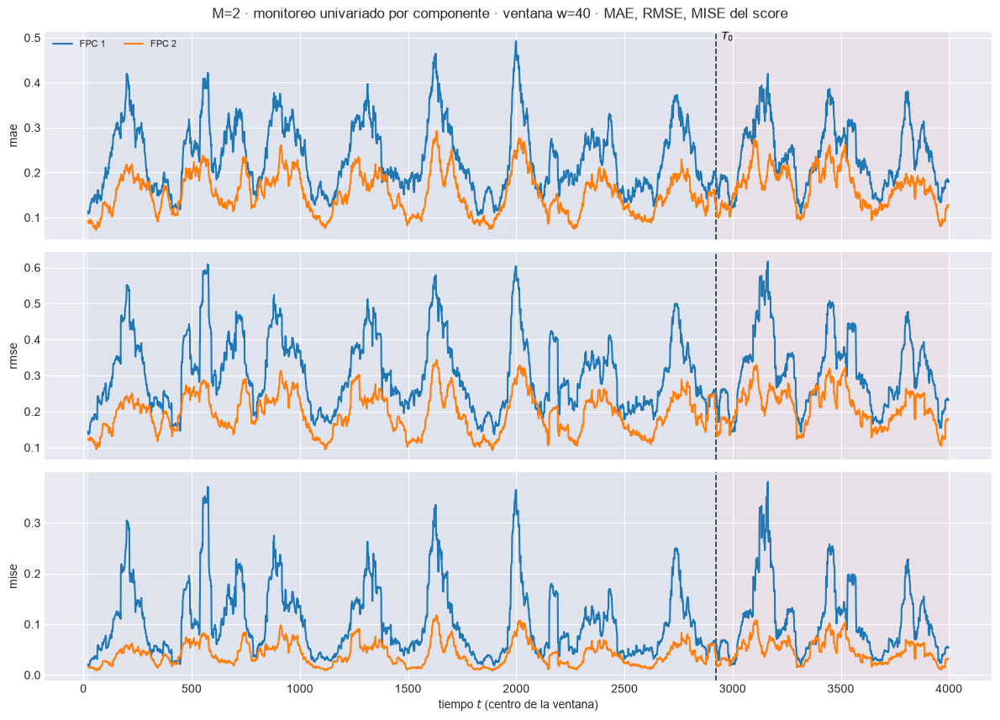

[ventana_movil_scores[FPC 1, w=30]] inicio (3988 pasos)


  1/3988 ( 0.0%) t=0.0s eta=3.9s  t=16 [train] rmse=0.1428


  199/3988 ( 5.0%) t=0.0s eta=0.3s  t=214 [train] rmse=0.4691


  398/3988 (10.0%) t=0.0s eta=0.3s  t=413 [train] rmse=0.1643


  597/3988 (15.0%) t=0.0s eta=0.3s  t=612 [train] rmse=0.2589


...

  3582/3988 (89.8%) t=0.2s eta=0.0s  t=3597 [test] rmse=0.1083


  3781/3988 (94.8%) t=0.3s eta=0.0s  t=3796 [test] rmse=0.121


  3980/3988 (99.8%) t=0.3s eta=0.0s  t=3995 [test] rmse=0.103

  3988/3988 (100.0%) t=0.3s eta=0.0s  t=4003 [test] rmse=0.1127


[ventana_movil_scores[FPC 3, w=30]] listo: 3988 pasos en 0.3s  29 ventanas cruzan T0


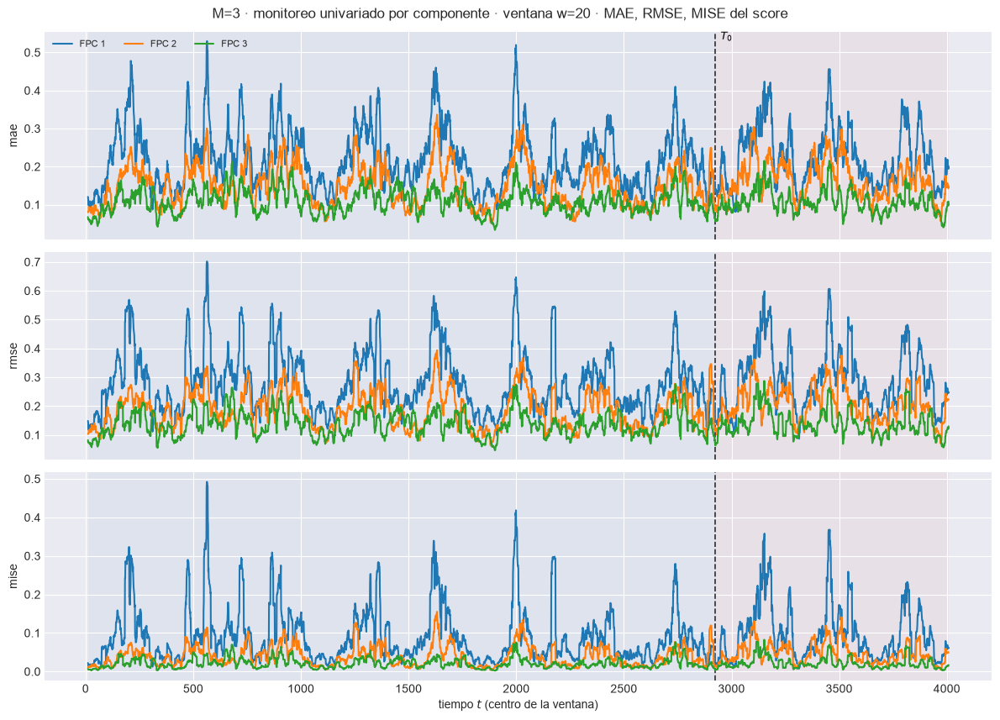

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.1424  w=30 test=0.1518


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.1843  w=30 test=0.1986


  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.03396  w=30 test=0.03943


[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_pm25_104_v02_m03\91_ventana_univariado_w30.png


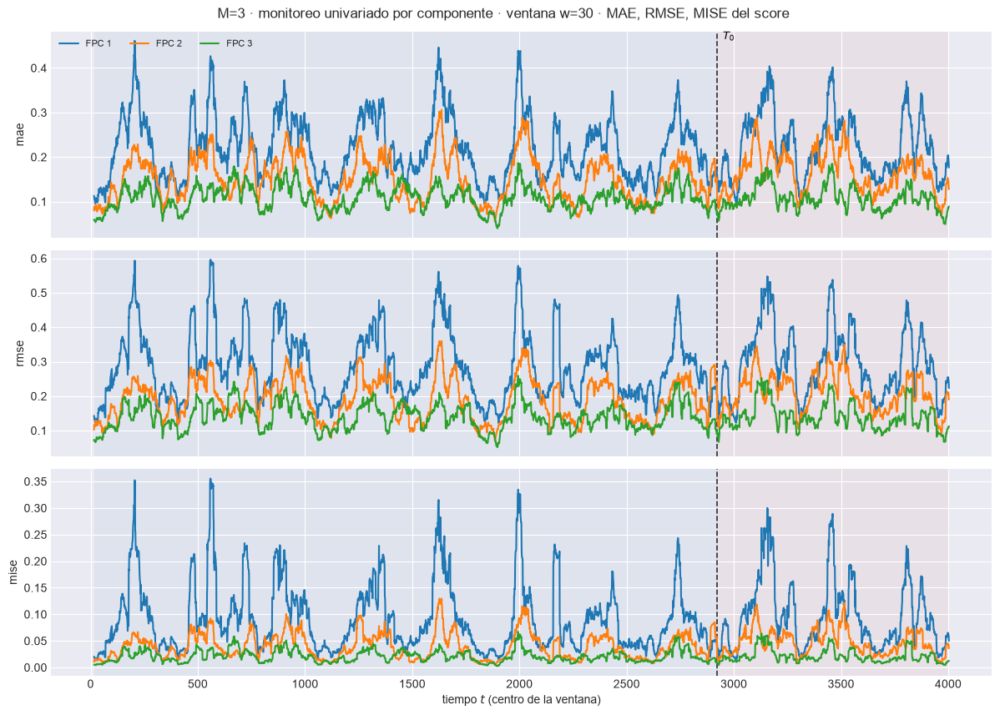

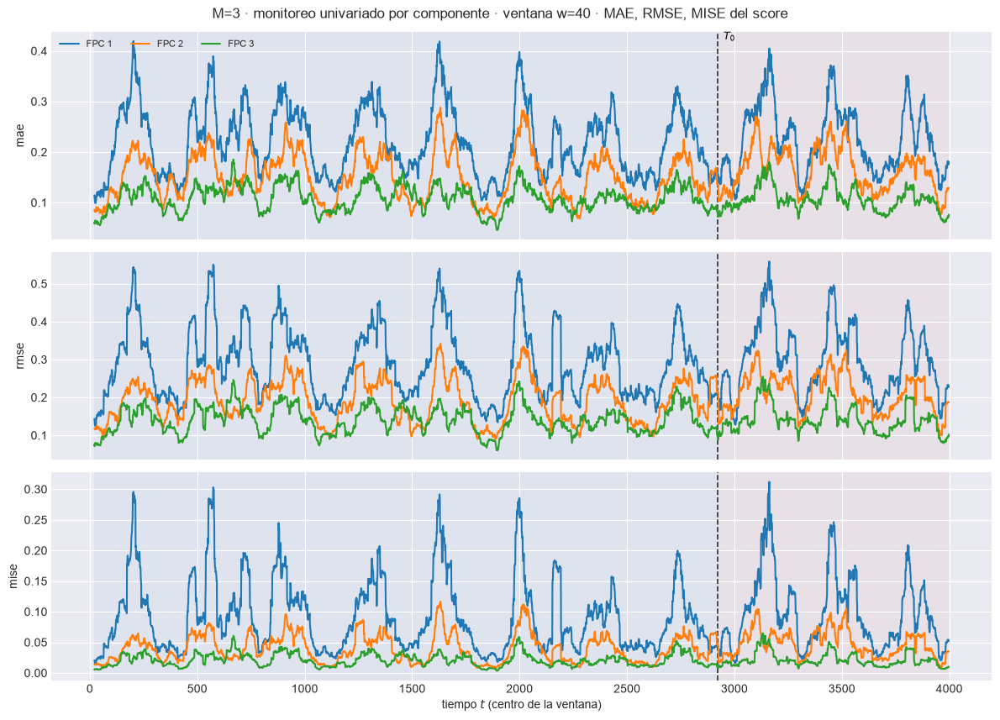

[ventana_movil_scores[FPC 1, w=30]] inicio (3988 pasos)


  1/3988 ( 0.0%) t=0.0s eta=4.0s  t=16 [train] rmse=0.1525


  199/3988 ( 5.0%) t=0.0s eta=0.3s  t=214 [train] rmse=0.4596


  398/3988 (10.0%) t=0.0s eta=0.3s  t=413 [train] rmse=0.1658


  597/3988 (15.0%) t=0.1s eta=0.3s  t=612 [train] rmse=0.2479


...

  3582/3988 (89.8%) t=0.3s eta=0.0s  t=3597 [test] rmse=0.1135


  3781/3988 (94.8%) t=0.3s eta=0.0s  t=3796 [test] rmse=0.06882


  3980/3988 (99.8%) t=0.3s eta=0.0s  t=3995 [test] rmse=0.09391


  3988/3988 (100.0%) t=0.3s eta=0.0s  t=4003 [test] rmse=0.07746


[ventana_movil_scores[FPC 4, w=30]] listo: 3988 pasos en 0.3s  29 ventanas cruzan T0


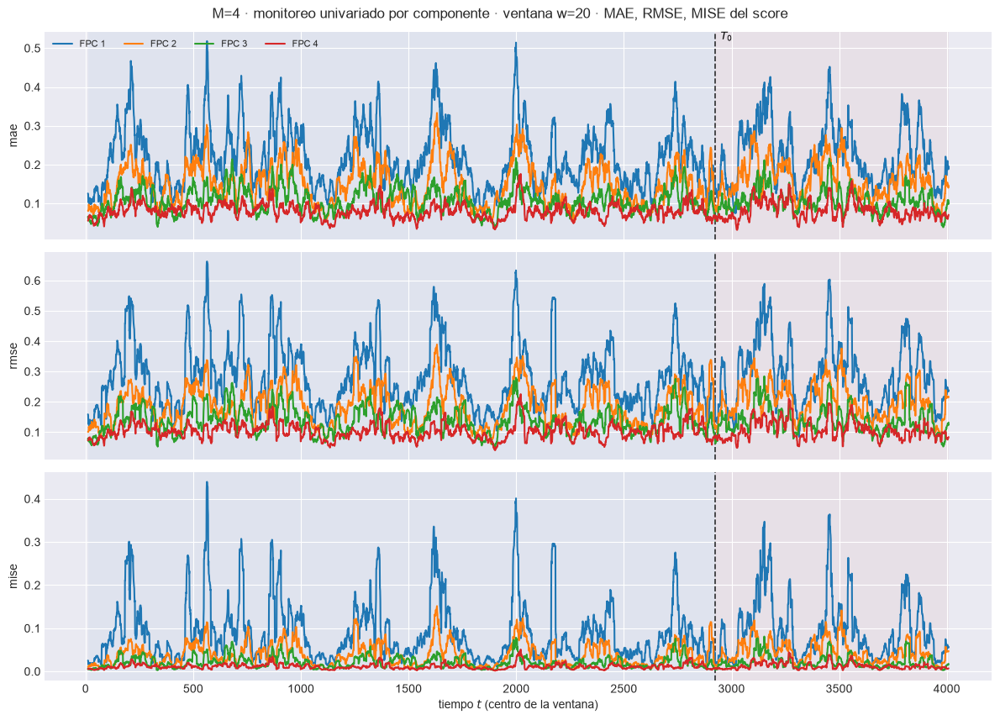

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.118  w=30 test=0.1242


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.1542  w=30 test=0.159


  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.02377  w=30 test=0.02529


[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_pm25_104_v02_m04\91_ventana_univariado_w30.png


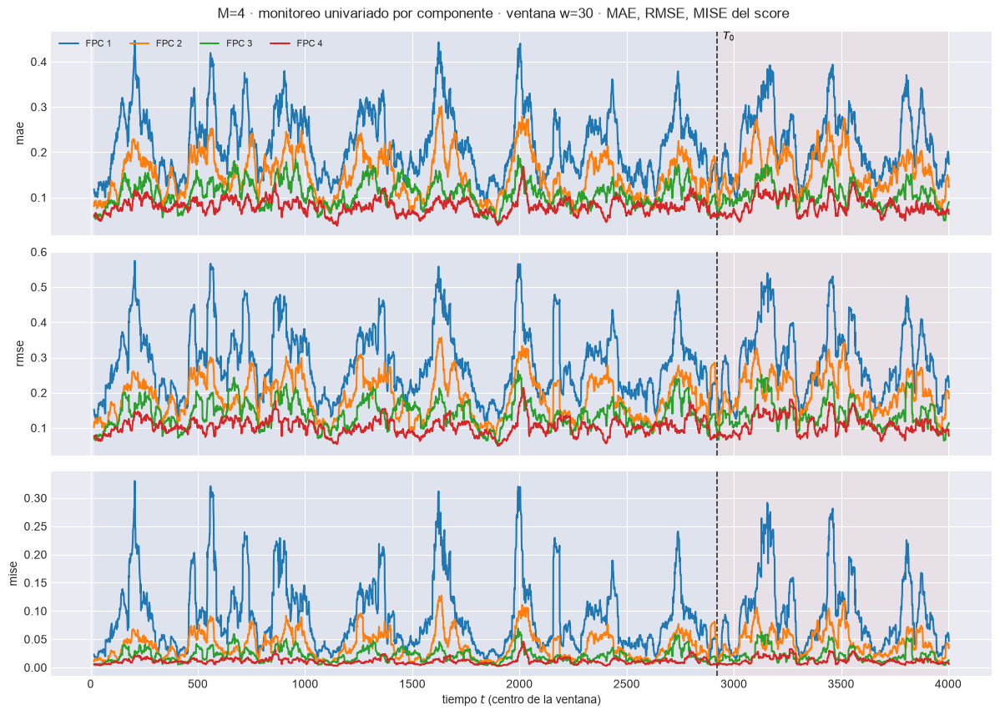

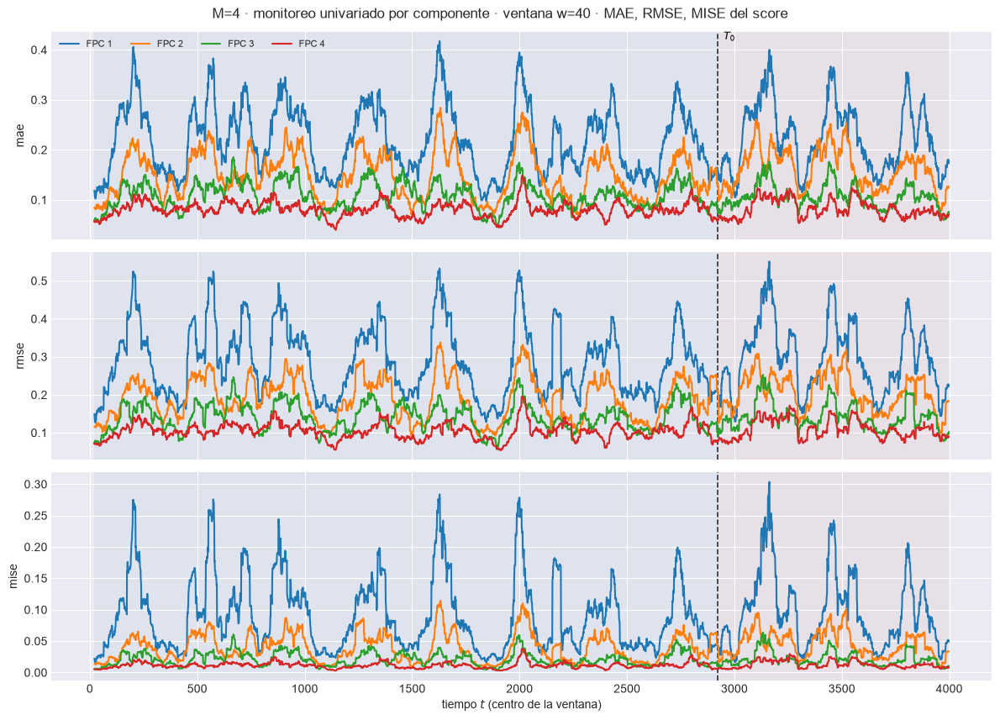

[ventana_movil_scores[FPC 1, w=30]] inicio (3988 pasos)


  1/3988 ( 0.0%) t=0.0s eta=3.7s  t=16 [train] rmse=0.1493


  199/3988 ( 5.0%) t=0.0s eta=0.3s  t=214 [train] rmse=0.4566


  398/3988 (10.0%) t=0.0s eta=0.3s  t=413 [train] rmse=0.1674


  597/3988 (15.0%) t=0.0s eta=0.3s  t=612 [train] rmse=0.2526


...

  3582/3988 (89.8%) t=0.2s eta=0.0s  t=3597 [test] rmse=0.1112


  3781/3988 (94.8%) t=0.3s eta=0.0s  t=3796 [test] rmse=0.07415


  3980/3988 (99.8%) t=0.3s eta=0.0s  t=3995 [test] rmse=0.06972


  3988/3988 (100.0%) t=0.3s eta=0.0s  t=4003 [test] rmse=0.06432


[ventana_movil_scores[FPC 5, w=30]] listo: 3988 pasos en 0.3s  29 ventanas cruzan T0


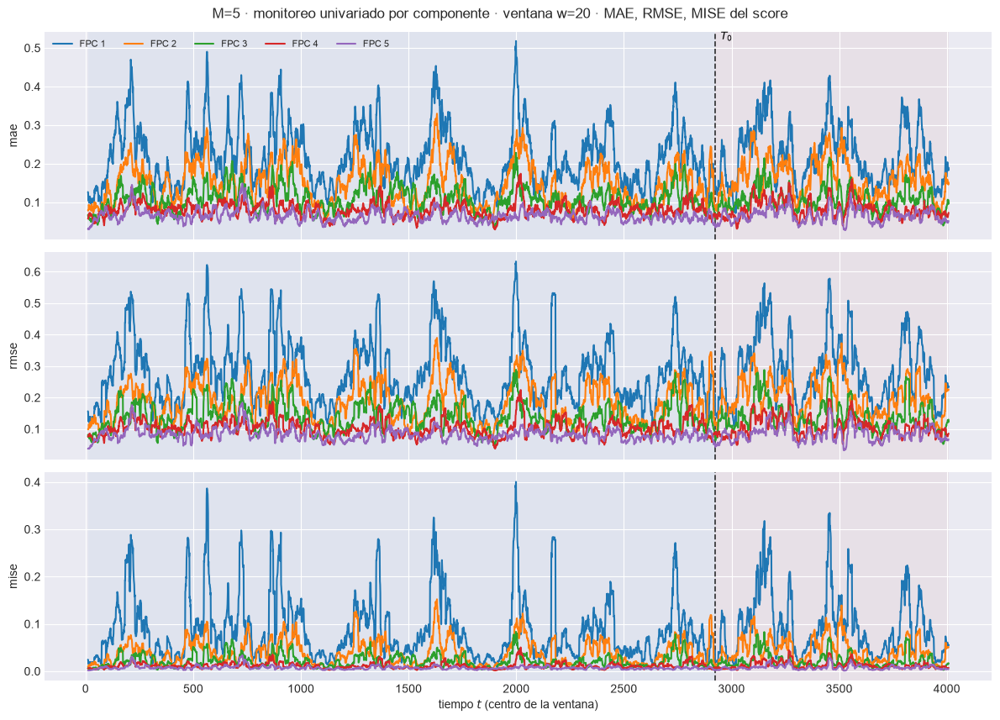

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.1006  w=30 test=0.106


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.1294  w=30 test=0.1392


  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.01674  w=30 test=0.01937


[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_pm25_104_v02_m05\91_ventana_univariado_w30.png


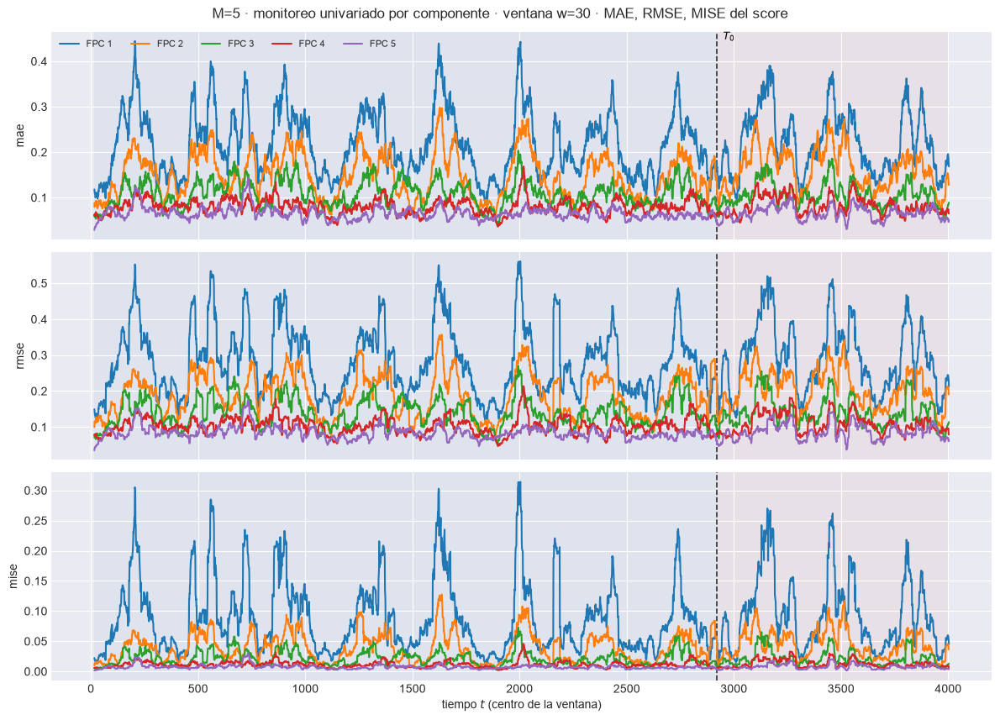

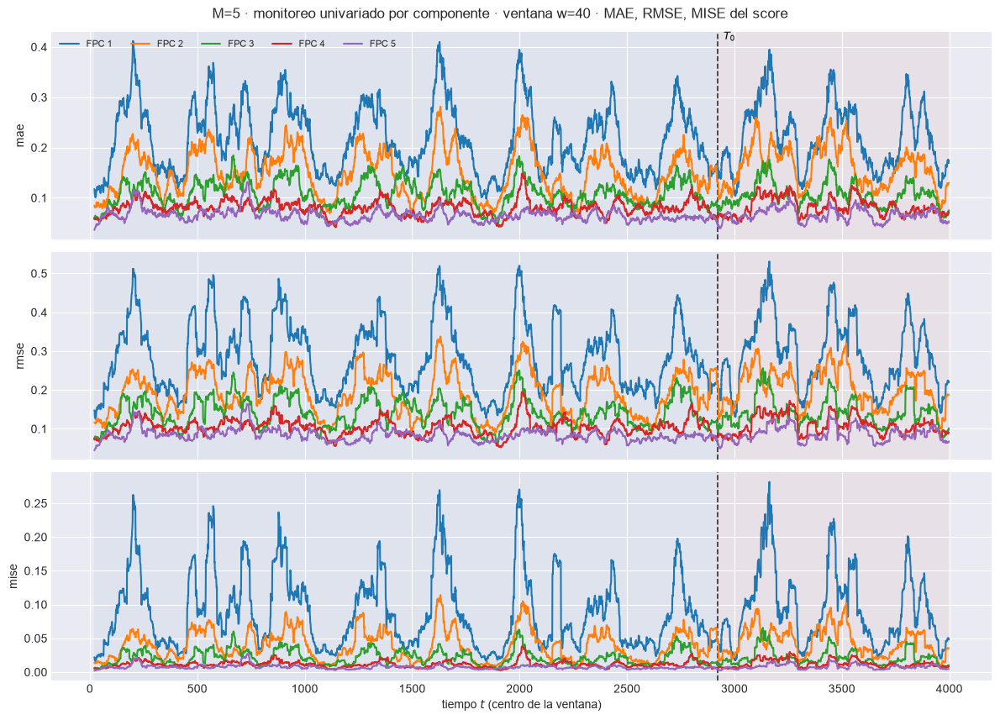

[ventana_movil_scores[FPC 1, w=30]] inicio (3988 pasos)


  1/3988 ( 0.0%) t=0.0s eta=3.8s  t=16 [train] rmse=0.1531


  199/3988 ( 5.0%) t=0.0s eta=0.3s  t=214 [train] rmse=0.4473


  398/3988 (10.0%) t=0.0s eta=0.3s  t=413 [train] rmse=0.1658


  597/3988 (15.0%) t=0.0s eta=0.2s  t=612 [train] rmse=0.2488


...

  3582/3988 (89.8%) t=0.3s eta=0.0s  t=3597 [test] rmse=0.08386

  3781/3988 (94.8%) t=0.3s eta=0.0s  t=3796 [test] rmse=0.08246


  3980/3988 (99.8%) t=0.3s eta=0.0s  t=3995 [test] rmse=0.0816


  3988/3988 (100.0%) t=0.3s eta=0.0s  t=4003 [test] rmse=0.06893


[ventana_movil_scores[FPC 6, w=30]] listo: 3988 pasos en 0.3s  29 ventanas cruzan T0


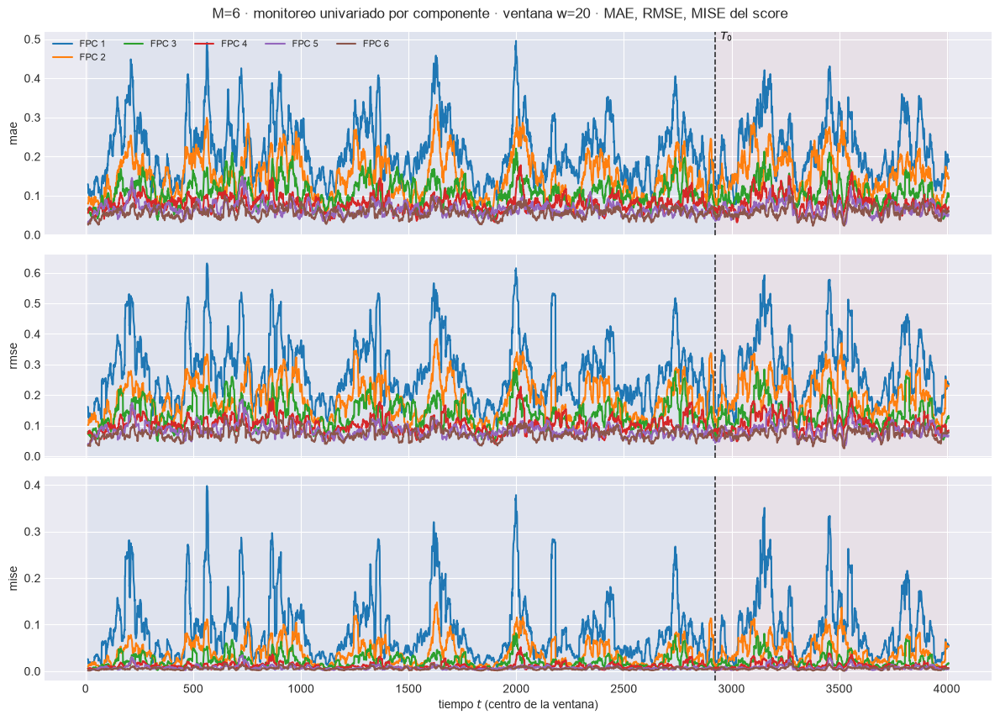

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.0875  w=30 test=0.09259


  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.1121  w=30 test=0.1221


  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.01257  w=30 test=0.0149


[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_pm25_104_v02_m06\91_ventana_univariado_w30.png


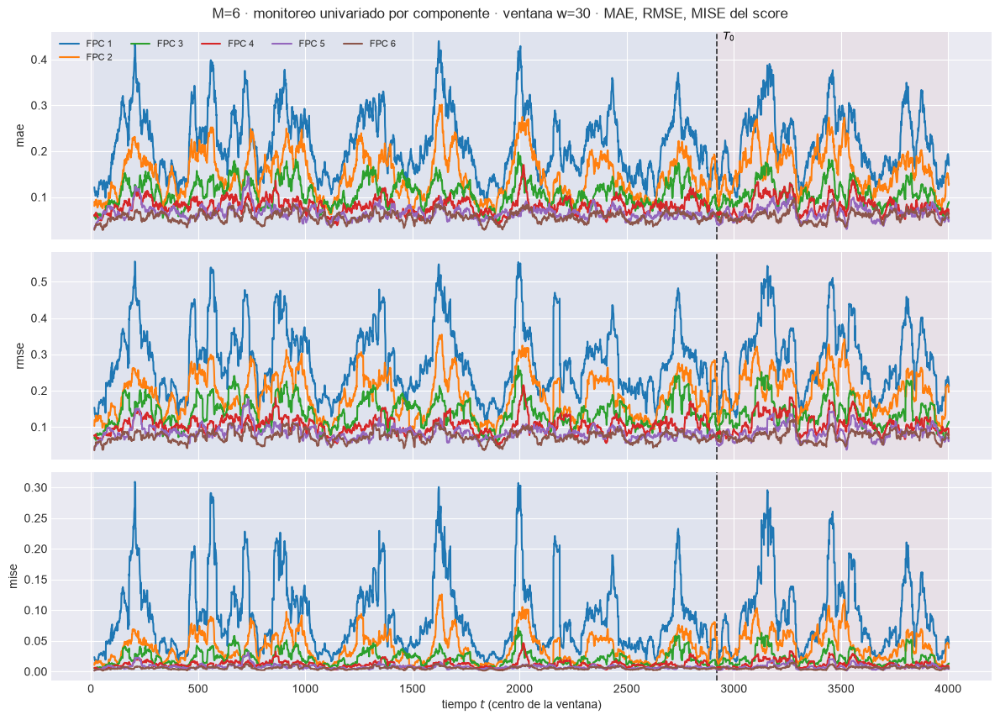

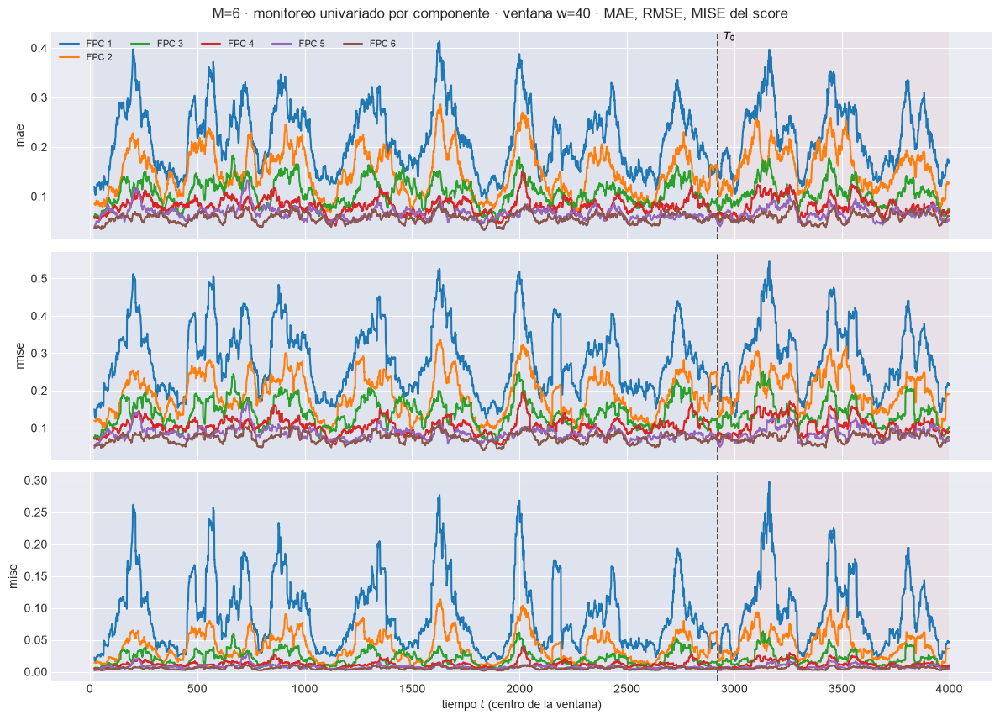

In [22]:
for M in M_OK:
    e = EST[M]
    monitoreo_scores(e, DIS, ORIG)
    for w in VENTANAS_W:
        tsc = e["tablas_score"][w].copy()
        tsc["mise"] = tsc["rmse"] ** 2      # MSE del score: análogo puntual del MISE
        plot_ventana_movil(
            tsc, T0, ["mae", "rmse", "mise"], columna_grupo="componente",
            title=f"M={M} · monitoreo univariado por componente · ventana w={w} · MAE, RMSE, MISE del score",
            save_path=str(e["paths"]["out_report"] / f"91_ventana_univariado_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

## 10. Evaluación puntual de los scores (coeficientes FPCA)

La banda es `li_s`/`ls_s` de §3, antes de propagar.

### 10.1 Cómo se mueve el intervalo de credibilidad de cada score

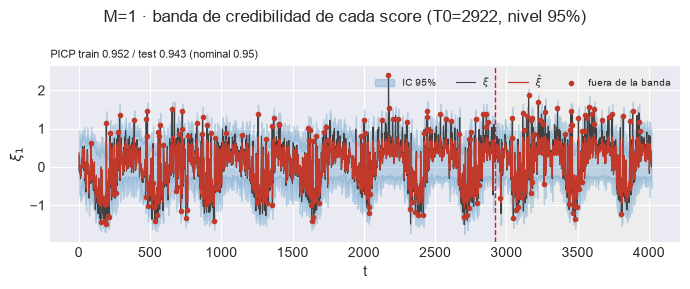

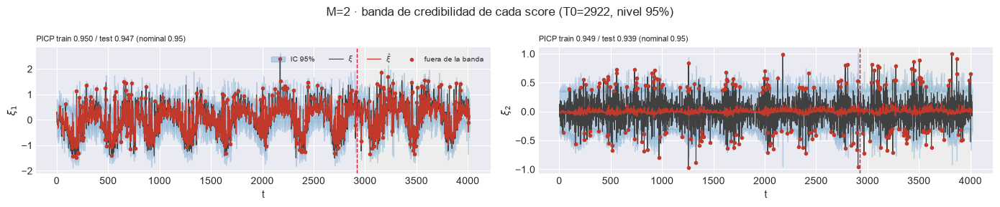

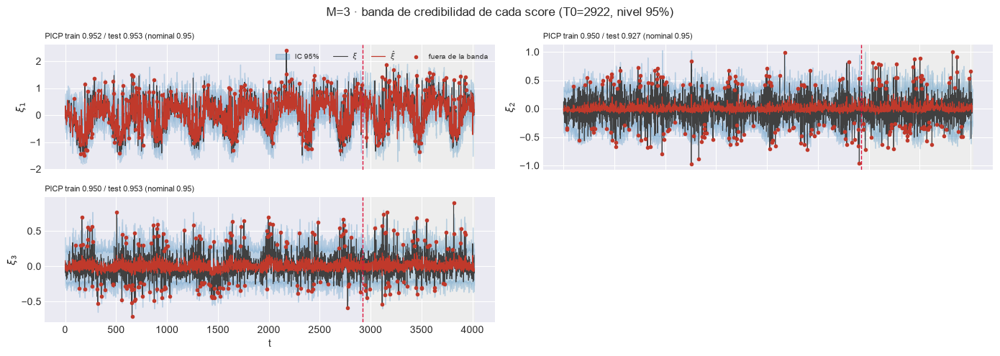

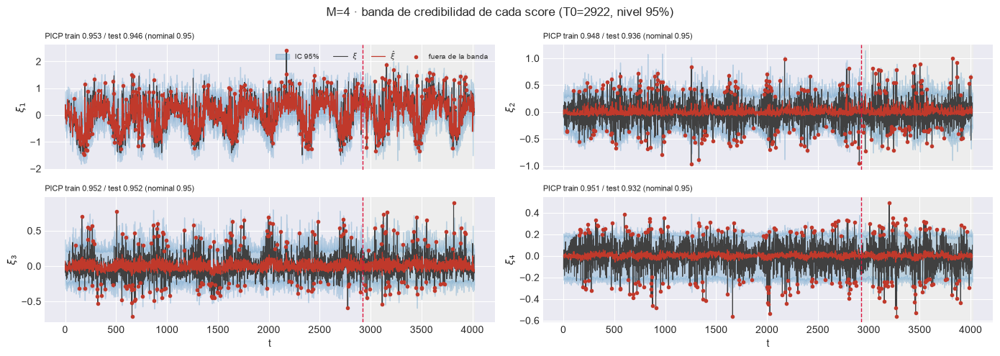

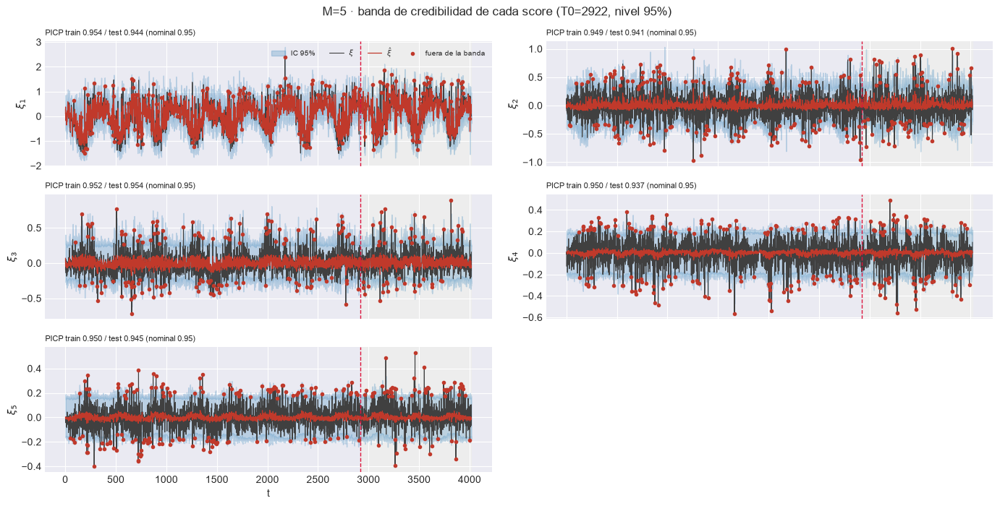

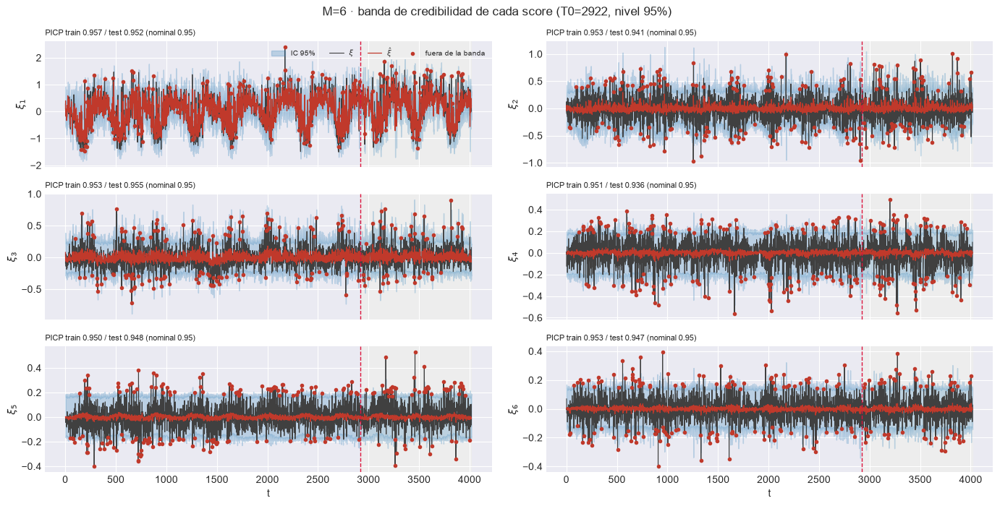

In [23]:
for M in M_OK:
    plot_scores_banda(EST[M], ORIG, DIS, M,
                      save_path=EST[M]["paths"]["out_report"] / "92_scores_banda_credibilidad.png")
    plt.show()

### 10.2 Métricas de intervalo sobre los scores

PICP, MPIW, Winkler y ACE por componente; global por bloque y sobre la ventana móvil.

OK ninguna componente se aleja mas de 0.1 del nominal en test.


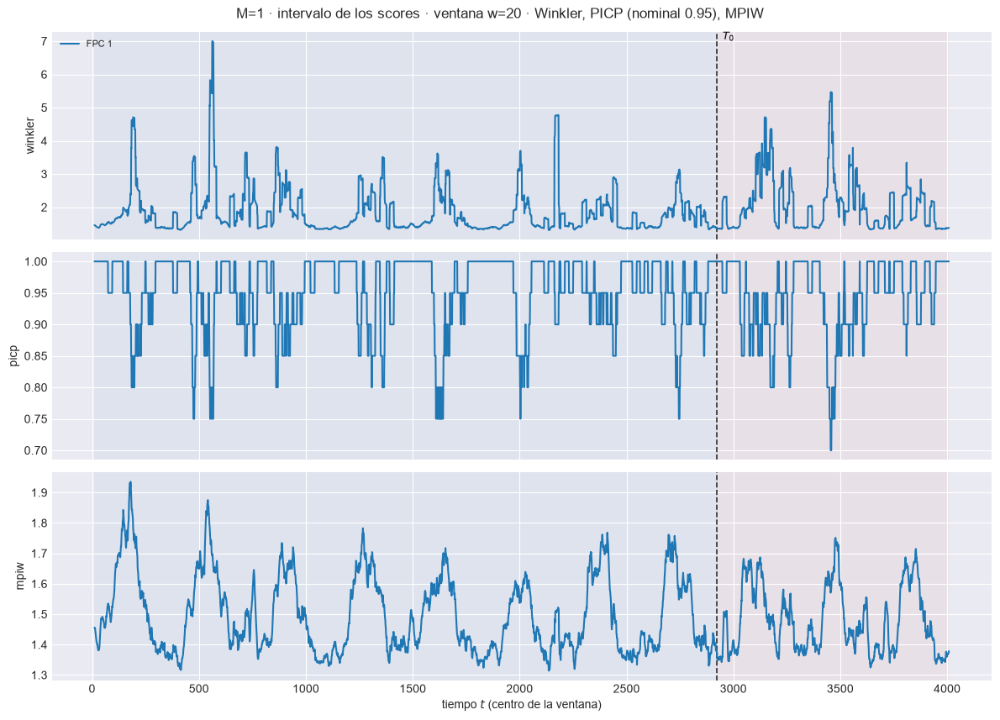

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=1.666  w=30 test=1.935


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.0s eta=0.0s  mpiw: w=30 train=1.463  w=30 test=1.455


[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_pm25_104_v02_m01\93_ventana_scores_intervalo_w30.png


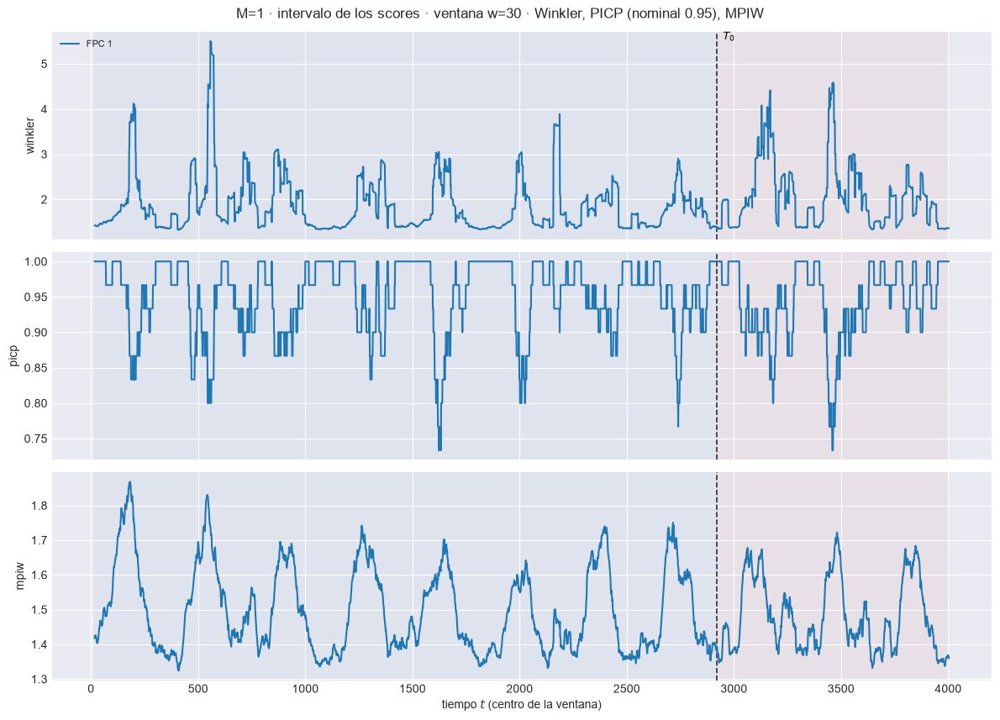

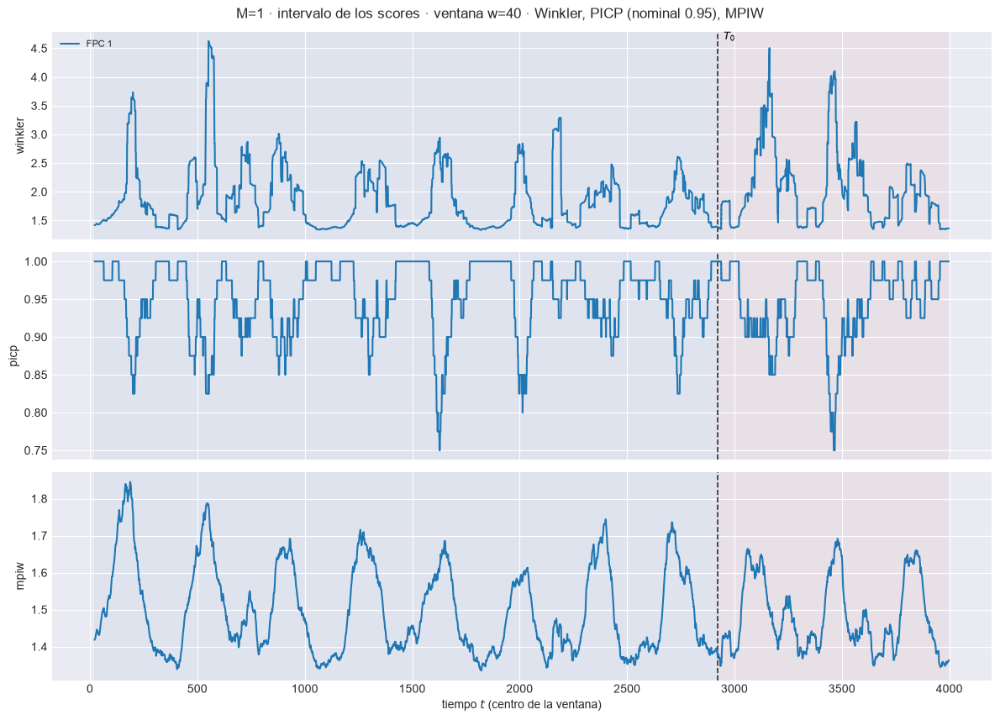

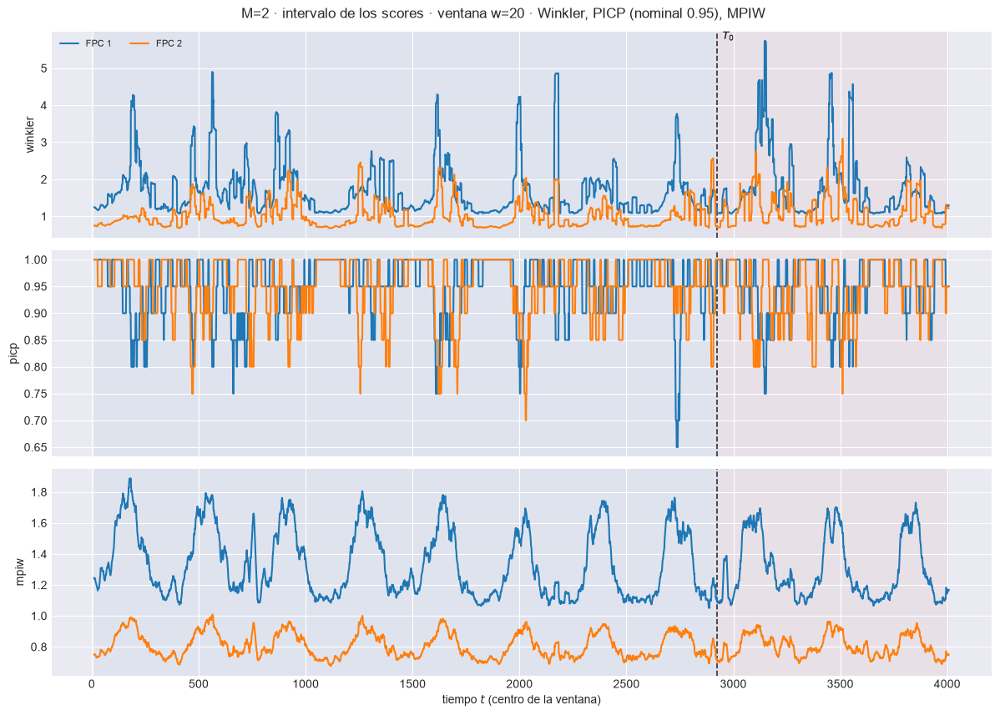

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=1.222  w=30 test=1.281


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9333


  3/3 (100.0%) t=0.0s eta=0.0s  mpiw: w=30 train=1.028  w=30 test=1.013


[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_pm25_104_v02_m02\93_ventana_scores_intervalo_w30.png


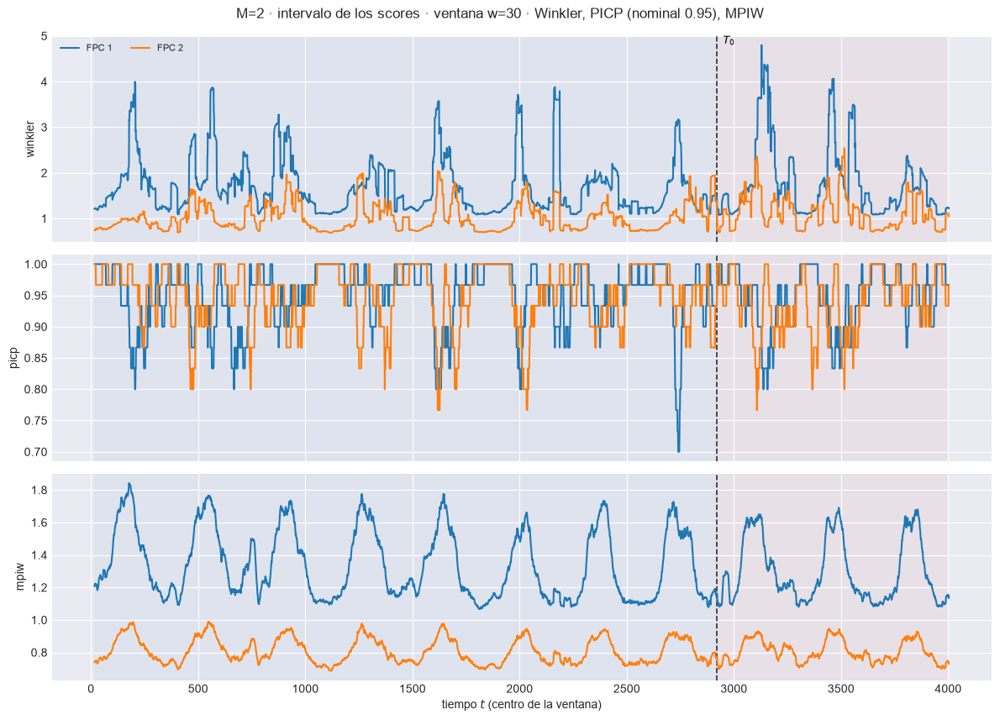

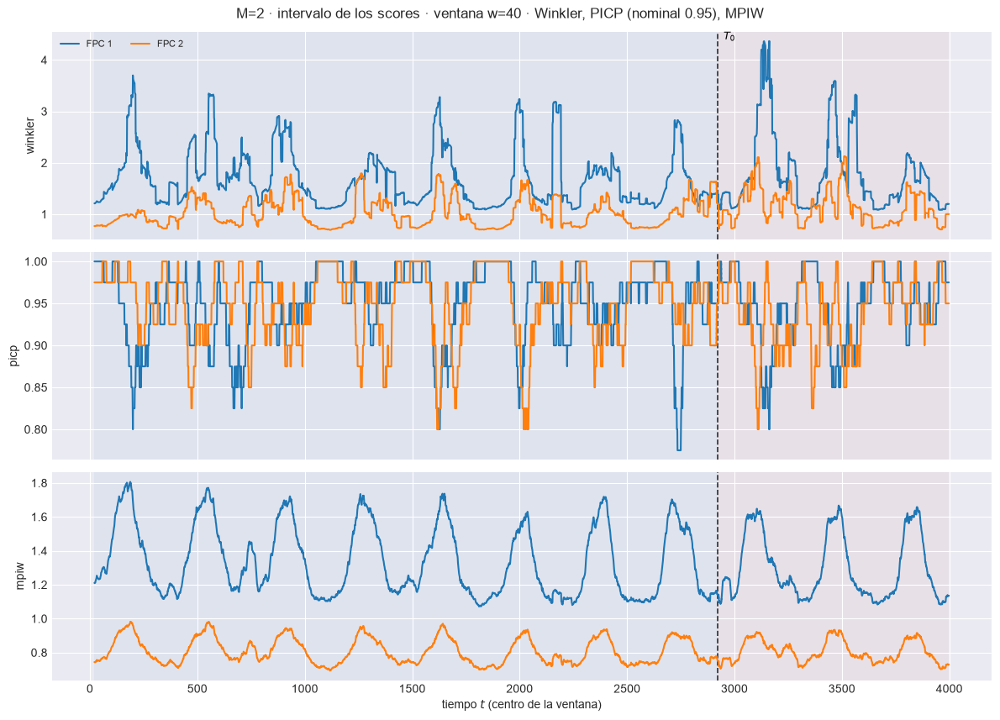

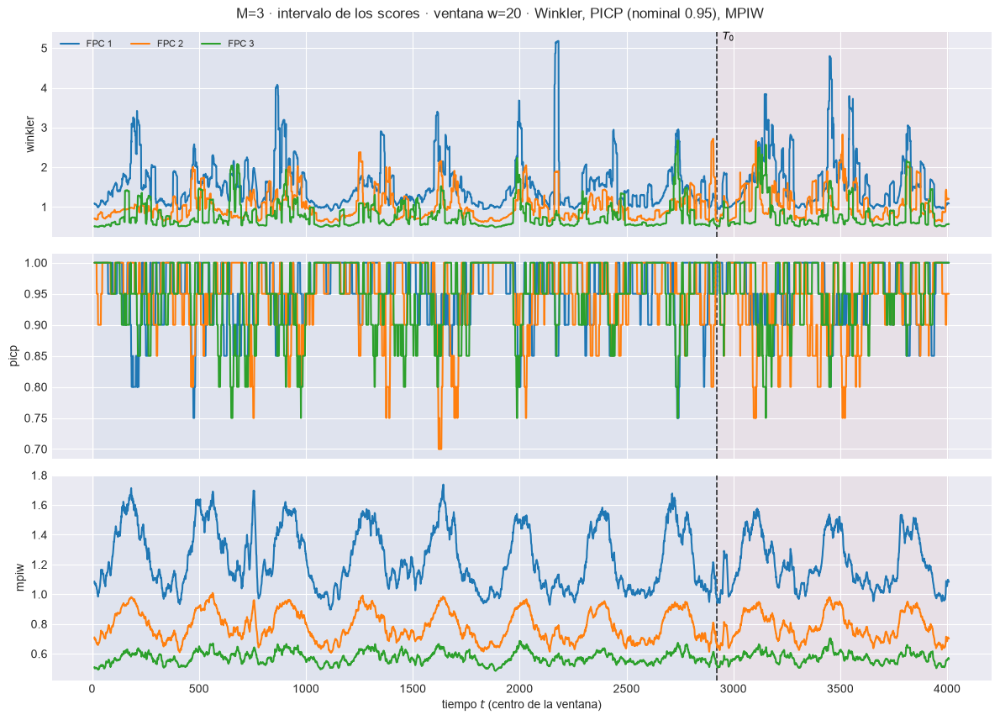

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=1.004  w=30 test=1.046


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9333


  3/3 (100.0%) t=0.0s eta=0.0s  mpiw: w=30 train=0.7603  w=30 test=0.7656


[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_pm25_104_v02_m03\93_ventana_scores_intervalo_w30.png


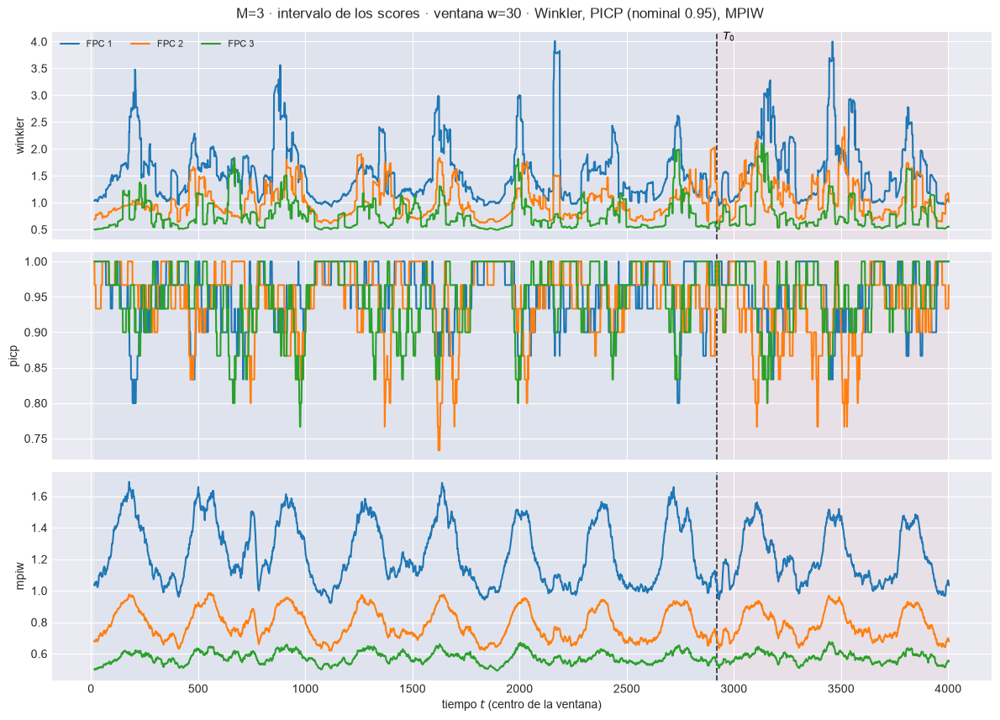

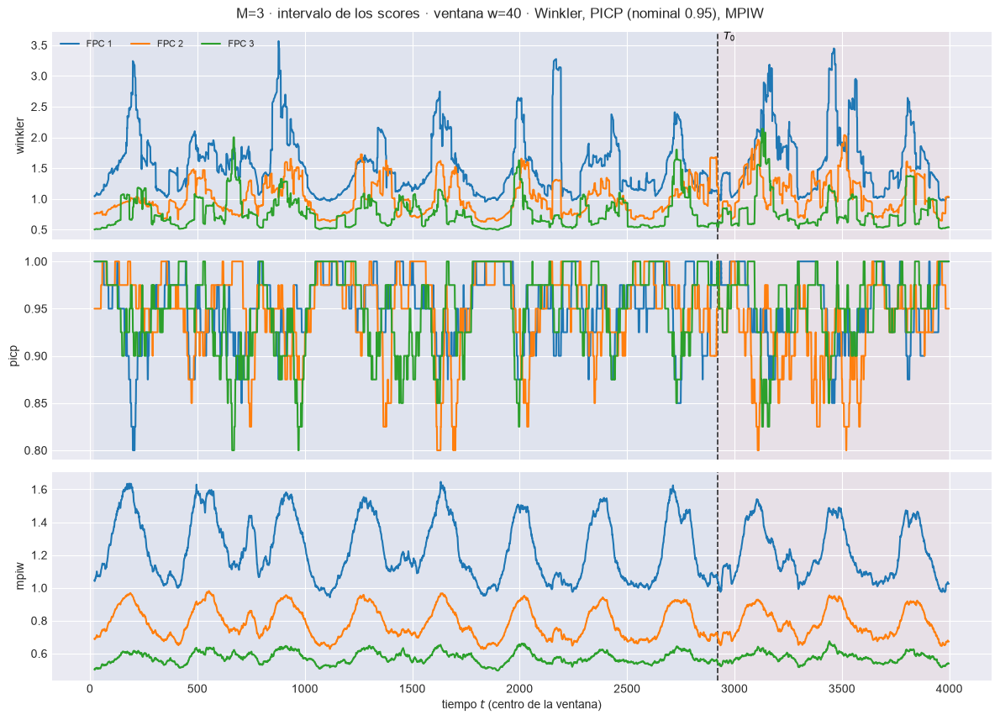

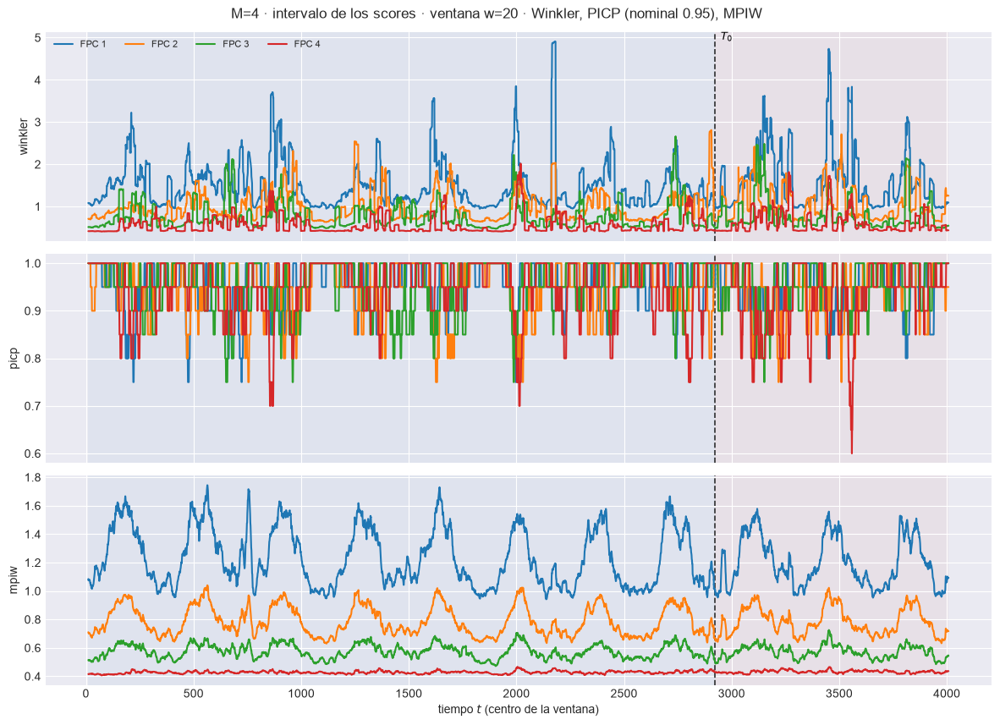

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=0.8245  w=30 test=0.8708


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9333


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.6575  w=30 test=0.656


[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_pm25_104_v02_m04\93_ventana_scores_intervalo_w30.png


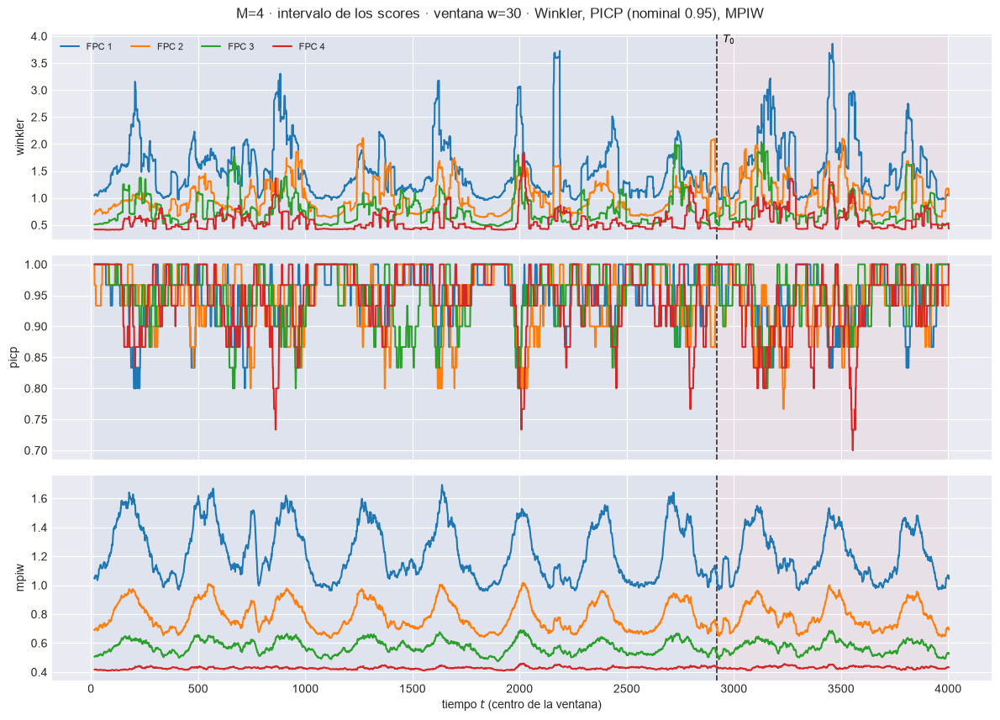

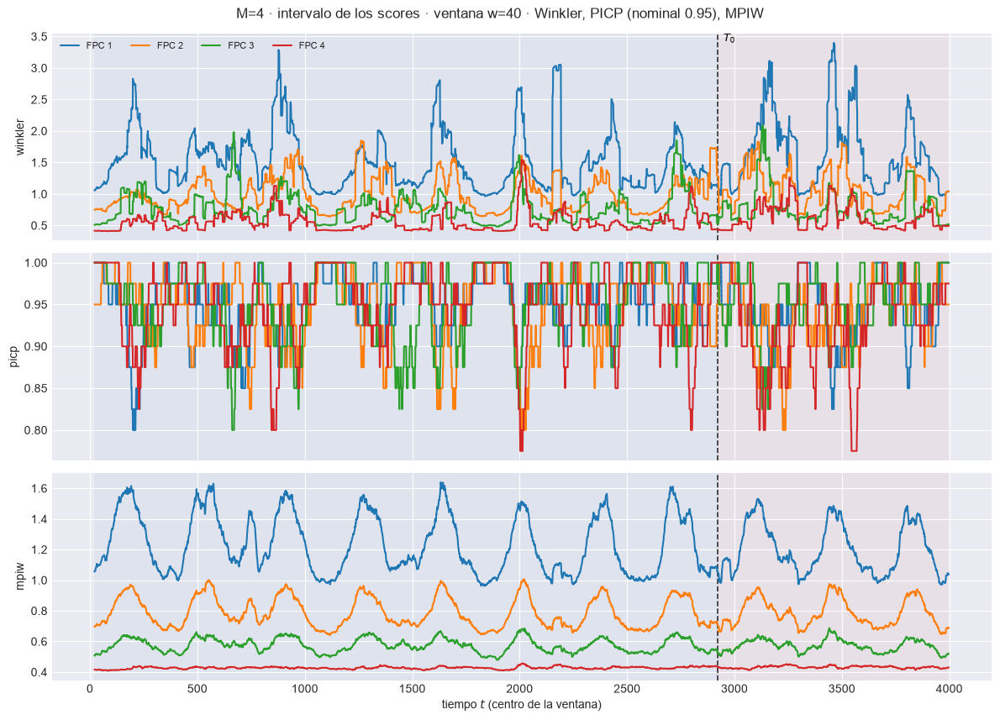

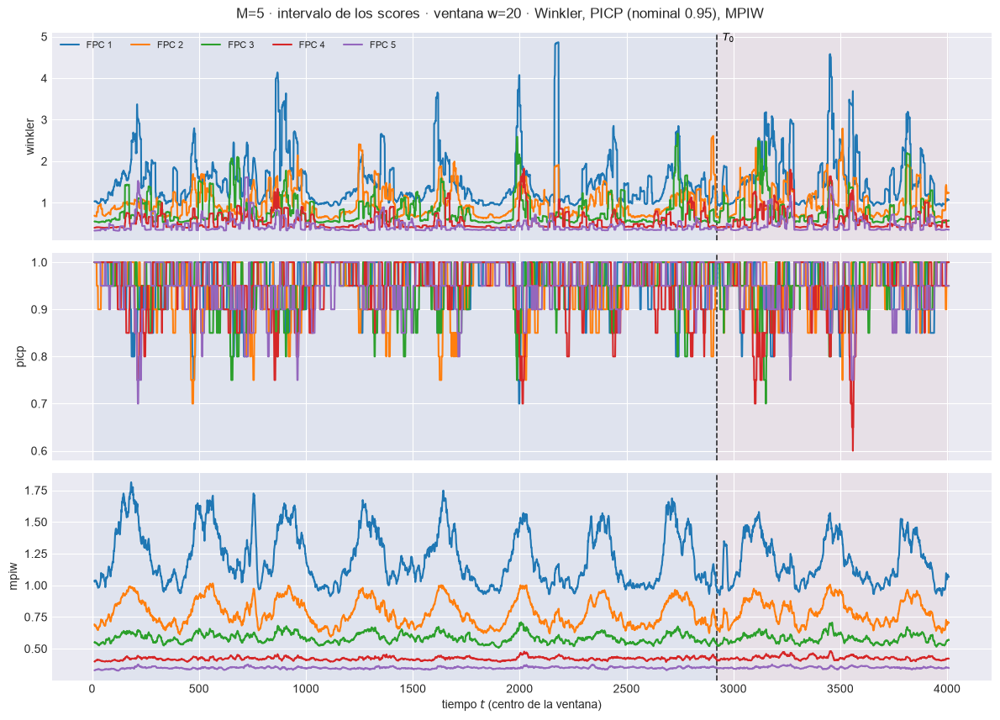

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=0.6957  w=30 test=0.7715


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9333


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.5804  w=30 test=0.5761


[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_pm25_104_v02_m05\93_ventana_scores_intervalo_w30.png


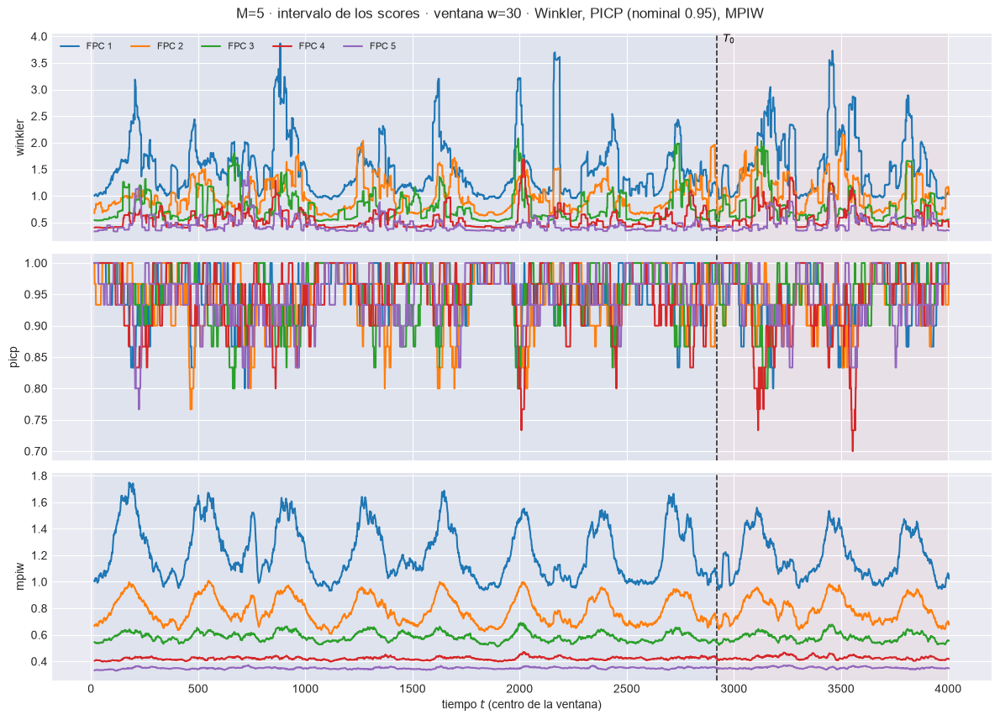

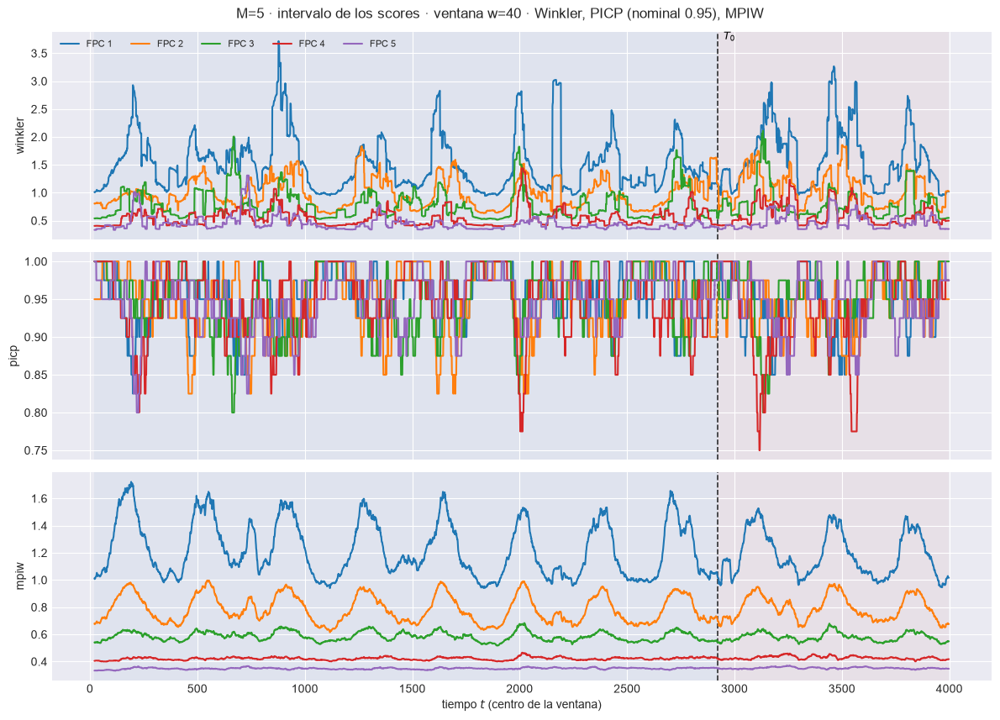

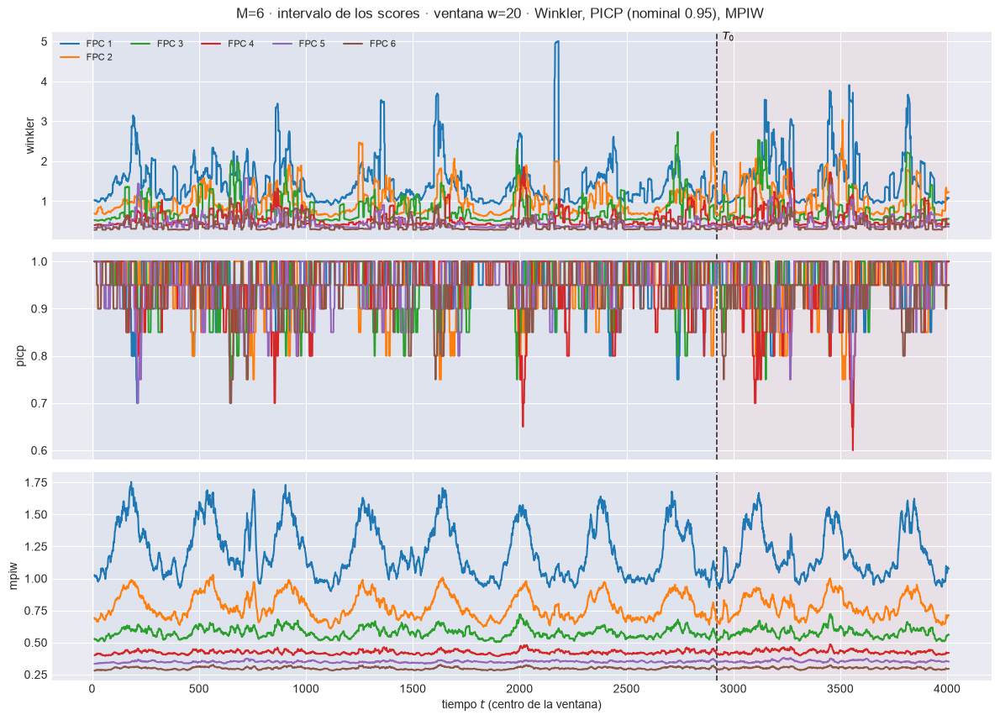

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=0.6144  w=30 test=0.6448


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.491  w=30 test=0.4871


[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_pm25_104_v02_m06\93_ventana_scores_intervalo_w30.png


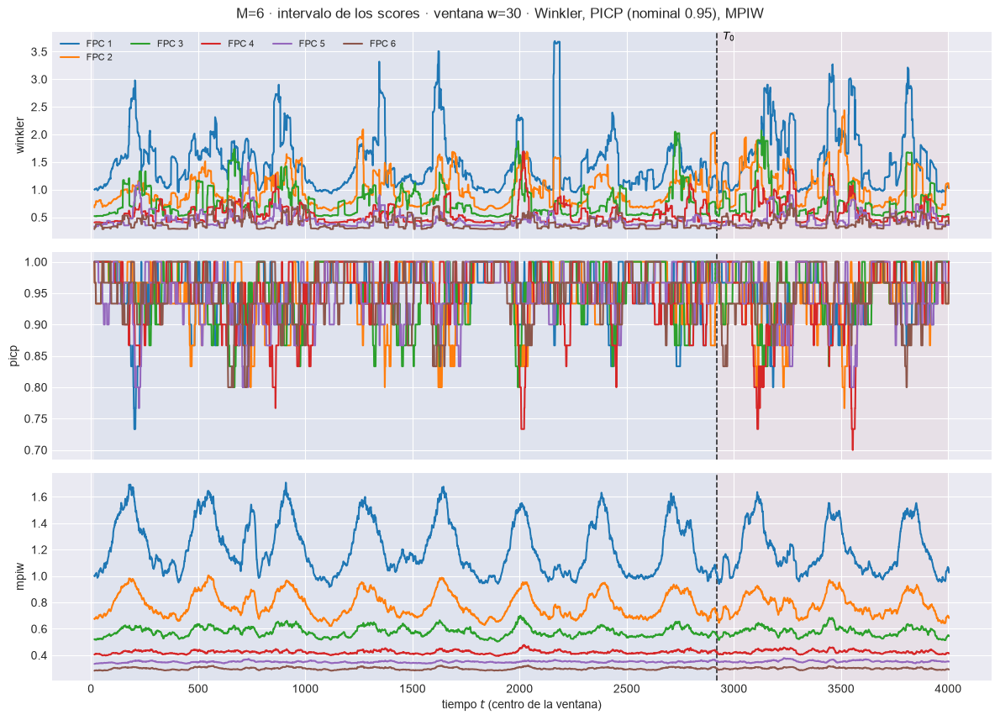

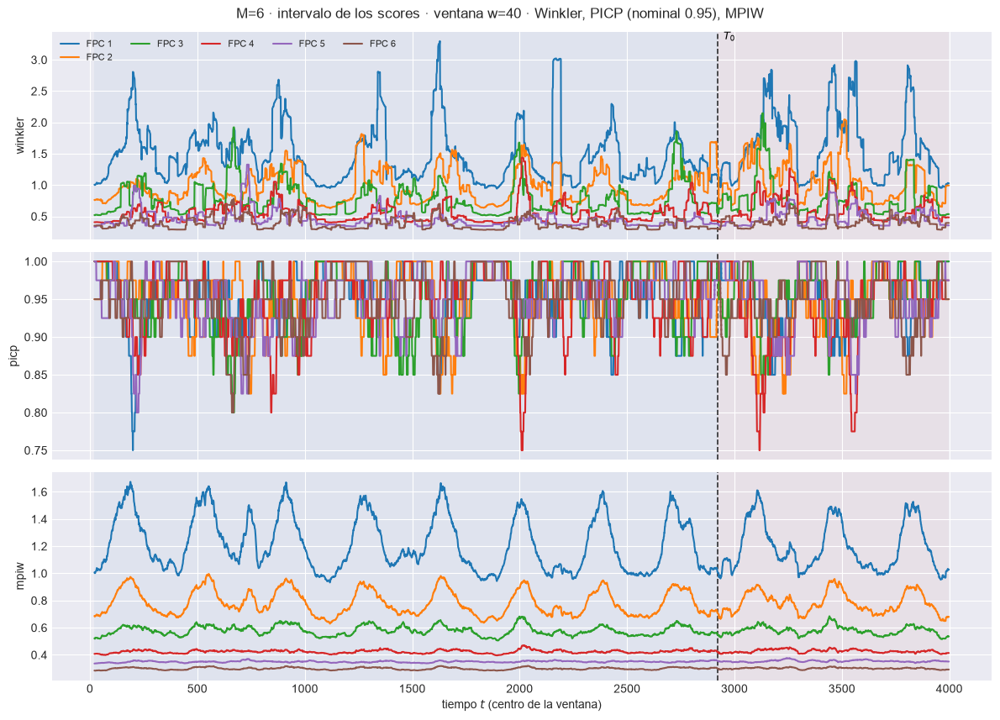

In [24]:
INT_SCORES = intervalos_scores(EST, M_OK, DIS, ORIG, PATH_BARRIDO)
display(INT_SCORES.set_index(["M", "componente", "bloque"]).style
        .format({"picp": "{:.4f}", "ace": "{:+.4f}", "mpiw": "{:.4f}", "winkler": "{:.4f}",
                 "sd_banda": "{:.4f}", "rmse": "{:.4f}", "mpiw_sobre_rmse": "{:.2f}"})
        .background_gradient(subset=["ace"], cmap="RdYlGn", vmin=-0.5, vmax=0.5)
        .set_caption(f"Intervalos de credibilidad de los scores, nivel {NIVEL:.0%} · ACE = PICP - nominal · "
                     "mpiw/rmse ≈ 3.92 si la banda fuera gaussiana y calibrada"))

# Evolución del intervalo sobre la ventana móvil, una figura por ancho.
for M in M_OK:
    for w in VENTANAS_W:
        plot_ventana_movil(
            EST[M]["tablas_score"][w], T0, ["winkler", "picp", "mpiw"], columna_grupo="componente",
            title=f"M={M} · intervalo de los scores · ventana w={w} · Winkler, PICP (nominal {NIVEL:.2f}), MPIW",
            save_path=str(EST[M]["paths"]["out_report"] / f"93_ventana_scores_intervalo_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

### 10.3 Dispersión $\hat\xi$ contra $\xi$

Un panel por componente con la diagonal; train y test con marcador distinto.

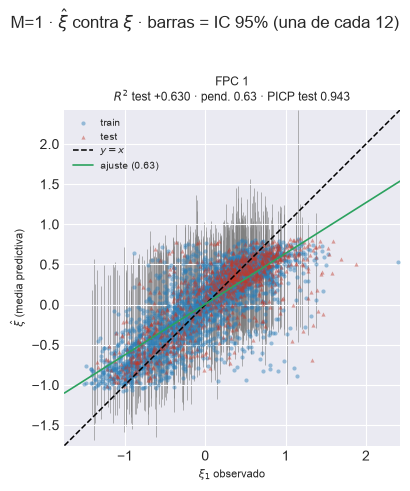

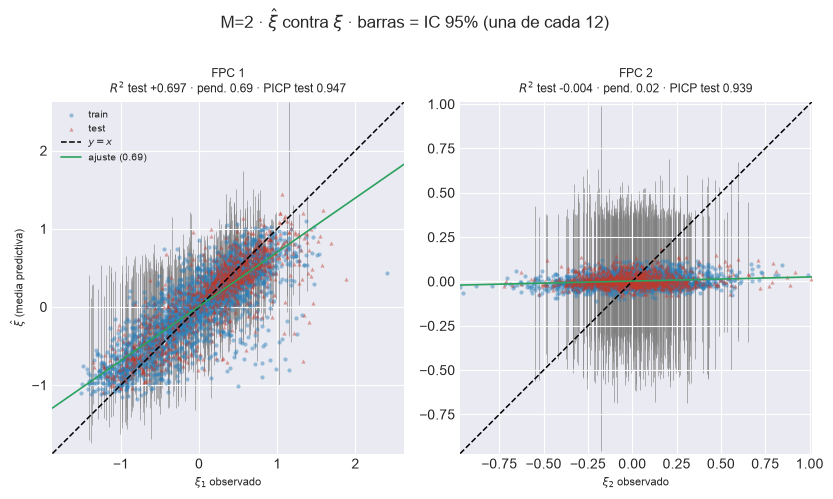

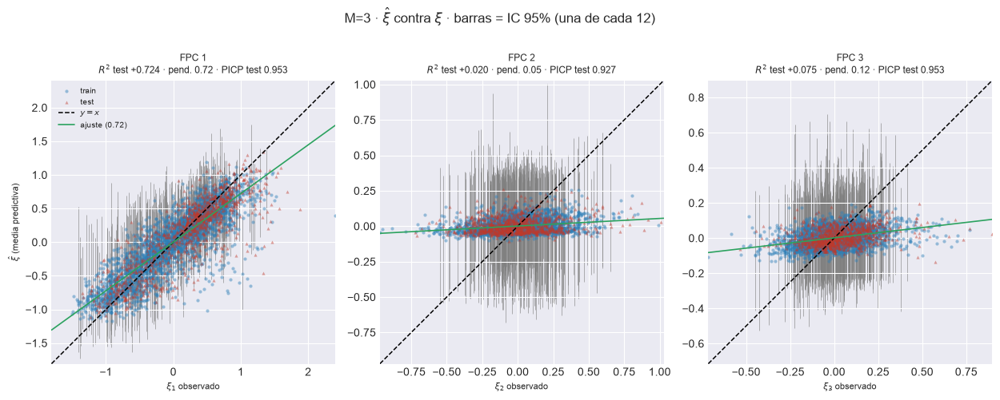

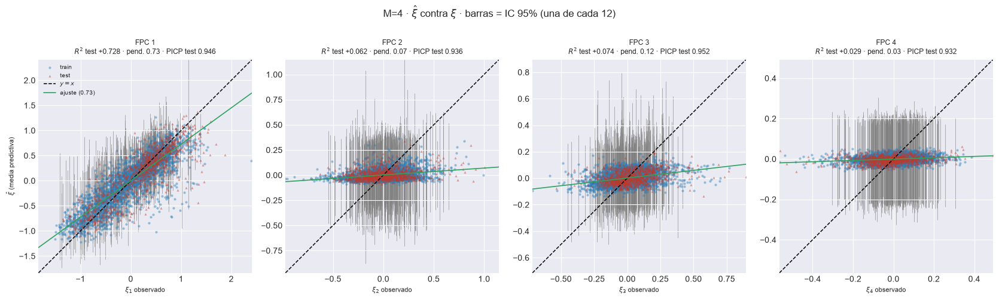

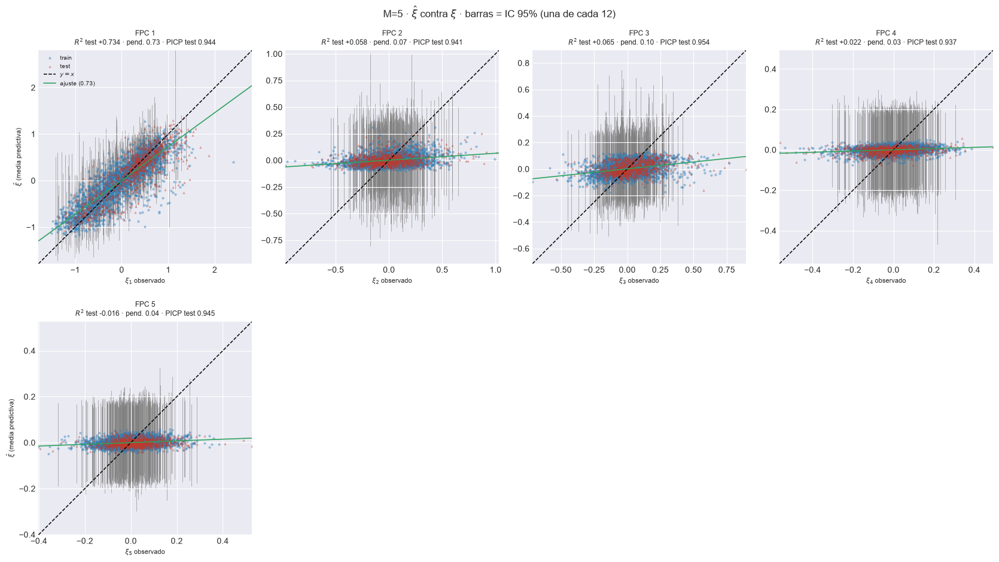

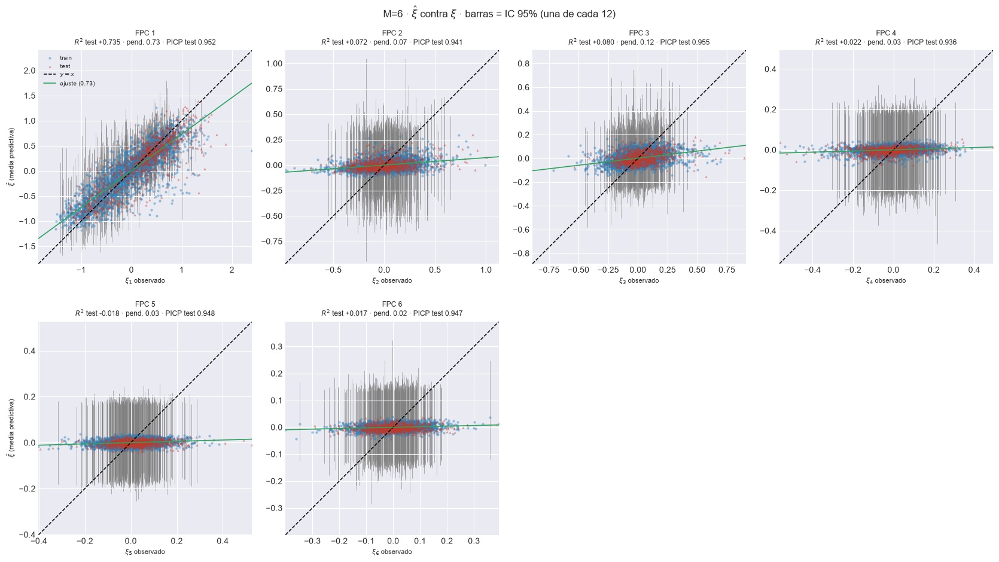

In [25]:
for M in M_OK:
    plot_scores_dispersion(EST[M], ORIG, DIS, M, CADA_BARRA,
                           save_path=EST[M]["paths"]["out_report"] / "94_scores_dispersion_vs_real.png")
    plt.show()

## 11. Diagnóstico de multimodalidad

En la ventana de detalle, como cuentas: por score, orígenes con $|\hat E - \mathrm{mediana}| > 0.25\,\hat s$; por origen, distancia de la mediana puntual a la extracción más cercana contra la de vecinas.

In [26]:
# Sobre los N_DETALLE orígenes de la ventana de detalle: cuentas k de N_DETALLE, descriptivas.
wn, MULTI = pesos_normalizados(grilla, PESOS_TAU), {}
for M in M_OK:
    e = EST[M]
    q16, q50, q84 = np.quantile(e["SC_draws"][:, IDX_DET], [0.16, 0.5, 0.84], axis=0)
    sep = np.abs(e["Y_hat"][IDX_DET] - q50) / np.maximum((q84 - q16) / 2.0, 1e-12)   # (N_DETALLE, M)
    por_score = pd.DataFrame({"componente": [f"FPC {c + 1}" for c in e["component_idx"]],
                              "n_origenes": N_DETALLE,
                              f"n_sep_gt_{UMBRAL_SEP}": (sep > UMBRAL_SEP).sum(axis=0),
                              "sep_mediana": np.median(sep, axis=0), "sep_max": sep.max(axis=0)})
    d = distancia_a_muestra_mas_cercana(curvas_draws(e, DIS, IDX_DET), e["X_PRED"]["mediana"][IDX_DET],
                                        grilla, PESOS_TAU, N_REF_NN, SEED_PRED)
    por_origen = pd.DataFrame({"t": T_DET, **d, "l1_esperanza_mediana":
                               np.abs(e["X_pred"][IDX_DET] - e["X_PRED"]["mediana"][IDX_DET]) @ wn,
                               "sep_max_score": sep.max(axis=1)})
    por_score.to_csv(e["paths"]["out_report"] / "60_multimodalidad_por_score.csv", index=False)
    por_origen.to_csv(e["paths"]["out_report"] / "61_distancia_mediana_muestra.csv", index=False)
    MULTI[M] = (por_score, por_origen)
multi_bar = pd.concat([MULTI[M][0].assign(M=M, t0_detalle=T0_DET) for M in M_OK], ignore_index=True)
multi_bar.to_csv(PATH_BARRIDO / "100_multimodalidad_por_M.csv", index=False)

display(multi_bar.pivot(index="componente", columns="M", values=f"n_sep_gt_{UMBRAL_SEP}")
        .reindex([f"FPC {k}" for k in range(1, max(M_OK) + 1)])
        .style.format("{:.0f}", na_rep="-").background_gradient(cmap="Reds", vmin=0, vmax=N_DETALLE, axis=None)
        .set_caption(f"Ventana de detalle (t={T0_DET}..): orígenes, de {N_DETALLE}, con "
                     f"|esperanza − mediana| > {UMBRAL_SEP} sd robusta, por score (descriptivo)"))
display(pd.DataFrame({M: MULTI[M][1].set_index("t")["razon"] for M in M_OK}).style.format("{:.2f}")
        .set_caption("Ventana de detalle · razón d(mediana, extracción más cercana) / d típica, por origen"))

M,1,2,3,4,5,6
componente,,,,,,
FPC 1,3,1,0,0,1,1
FPC 2,-,0,0,0,0,0
FPC 3,-,-,0,0,0,0
FPC 4,-,-,-,0,0,0
FPC 5,-,-,-,-,0,0
FPC 6,-,-,-,-,-,0


,1,2,3,4,5,6
t,,,,,,
3474,0.18,0.87,0.94,0.62,0.40,0.46
3475,0.19,1.27,0.25,0.30,0.74,0.63
3476,2.19,0.88,0.62,0.60,0.68,0.59
3477,0.23,0.70,0.63,0.72,0.47,0.59
3478,1.01,0.55,0.51,0.77,0.69,0.45
3479,0.02,0.88,0.95,0.59,1.01,0.61
3480,0.91,0.53,0.51,0.78,0.55,0.32
3481,0.05,0.64,0.70,0.77,0.42,0.49
3482,0.82,0.80,0.48,0.83,0.47,0.43


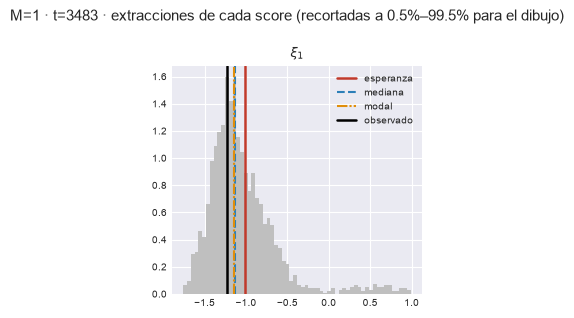

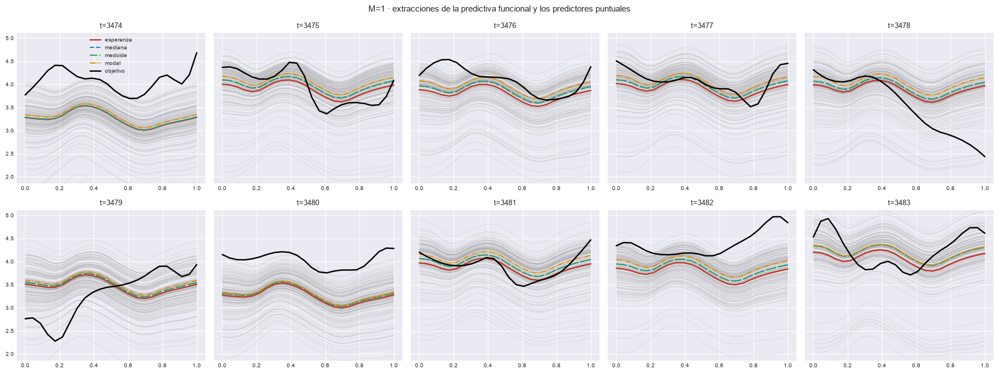

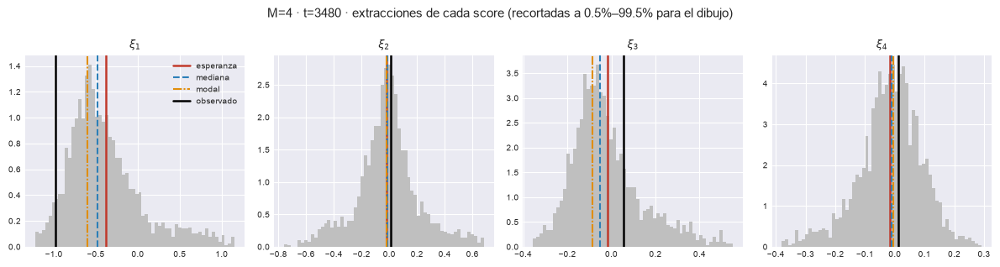

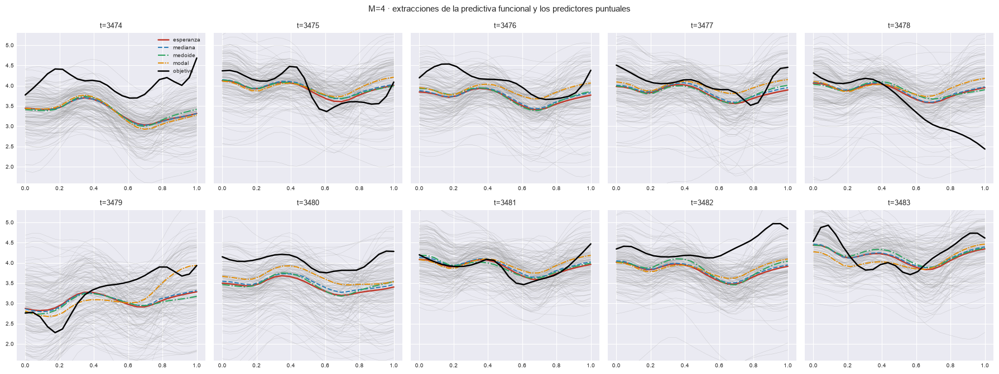

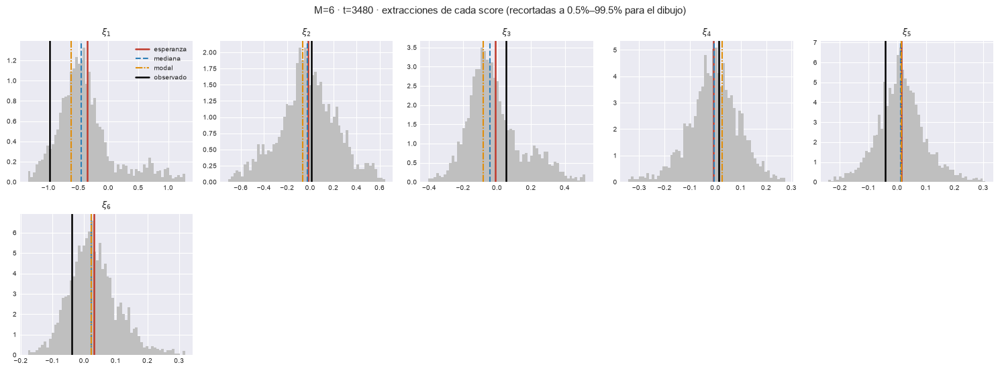

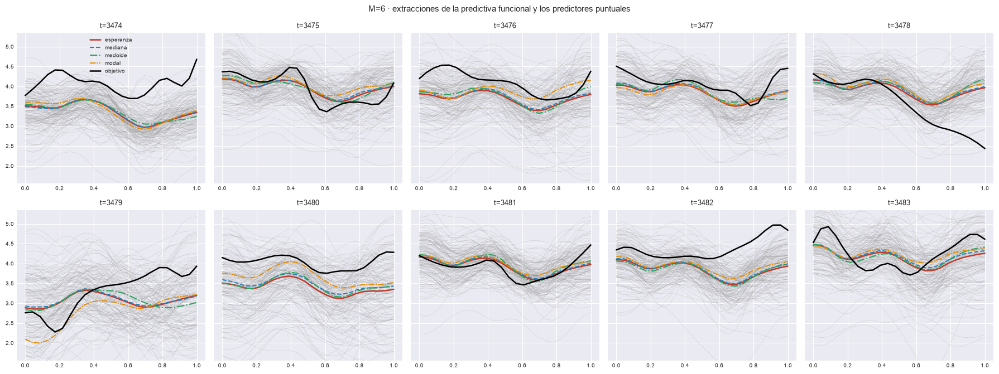

In [27]:
# El origen más multimodal de la ventana: extracciones por score; los N_DETALLE: curvas y predictores.
for M in (m for m in M_DETALLE if m in M_OK):
    e, po = EST[M], MULTI[M][1]
    i_mm = int(IDX_DET[int(np.argmax(po["sep_max_score"].to_numpy()))])
    marcas = {"esperanza": e["Y_hat"], "mediana": np.median(e["SC_draws"], axis=0),
              "modal": e["Y_mod"], "observado": e["Y_obs"]}
    plot_histogramas_draws(e["SC_draws"], i_mm, marcas, int(t_orig[i_mm]), M,
                           save_path=e["paths"]["out_report"] / f"61_histogramas_draws_t{int(t_orig[i_mm])}.png")
    plt.show()
    plot_curvas_predictores(curvas_draws(e, DIS, IDX_DET), {p: e["X_PRED"][p][IDX_DET] for p in PREDICTORES},
                            X_obj_ev[IDX_DET], grilla, T_DET, M, ncols=5,
                            save_path=e["paths"]["out_report"] / "61b_curvas_predictores.png")
    plt.show()

## 12. Comportamientos predictivos

k-medias sobre las extracciones de scores por origen; $K$ con las reglas de docs §03_06_02 (valle, crecimiento, masa); con $a_\tau \le 1$ se recortan los draws al 0.5–99.5 %. §12.1 y §12.4 sobre toda la serie; §12.2, §12.3, §12.5 y el cierre de §12.4 sobre la ventana de detalle. Se persiste en `comportamientos_psbp.npz`.

### 12.1 Número de comportamientos por origen

    comportamientos: 250/4017 origenes


    comportamientos: 500/4017 origenes


    comportamientos: 750/4017 origenes


    comportamientos: 1000/4017 origenes


    comportamientos: 1250/4017 origenes


...

    comportamientos: 3750/4017 origenes


    comportamientos: 4000/4017 origenes


M= 6: K en test  K=1: 99.9%  K=2: 0.1%   (recorte no, 95 s)


M,1,2,3,4,5,6
K,,,,,,
1,99.8%,99.8%,99.8%,99.9%,99.1%,99.3%
2,0.2%,0.2%,0.2%,0.1%,0.9%,0.7%
3,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
4,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
5,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
6,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%


M,1,2,3,4,5,6
K,,,,,,
1,100.0%,100.0%,100.0%,100.0%,99.7%,99.9%
2,0.0%,0.0%,0.0%,0.0%,0.3%,0.1%
3,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
4,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
5,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
6,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%


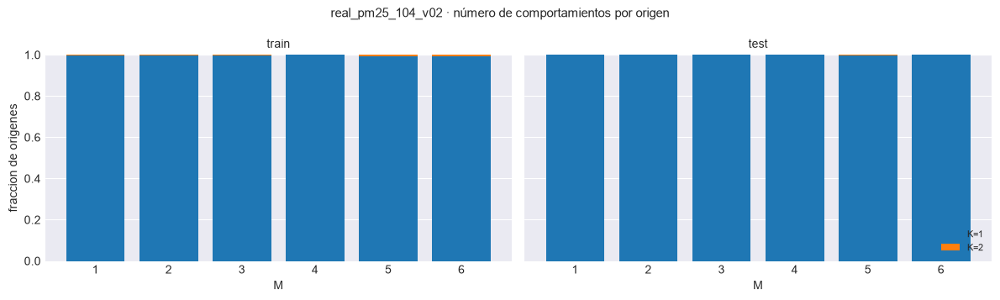

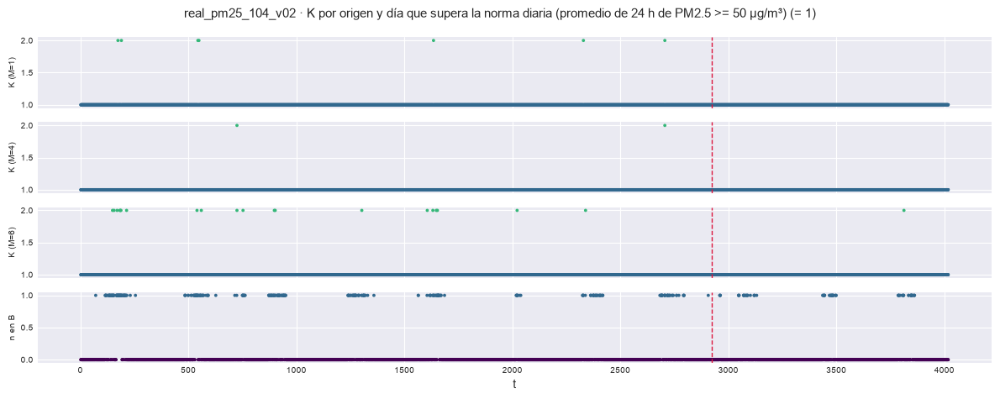

In [28]:
K_BAR = comportamientos_barrido(EST, M_OK, DIS, ORIG, PATH_BARRIDO, solo_test=COMP_SOLO_TEST)
for b in ("train", "test"):
    display(K_BAR[K_BAR.bloque == b].pivot(index="K", columns="M", values="frac")
            .style.format("{:.1%}").set_caption(f"Fracción de orígenes {b.upper()} con K comportamientos (102_K_por_M.csv)"))
plot_K_barrido(K_BAR, f"{EXPERIMENT_BASE} · número de comportamientos por origen", PATH_BARRIDO / "102_K_por_M.png")
plt.show()

plot_K_serie({M: EST[M]["COMP"]["K"] for M in M_DETALLE if M in M_OK}, t_orig, T0, n_B=EVENTO_OR,
             titulo=f"{EXPERIMENT_BASE} · K por origen y {DESCR_EVENTO} (= 1)",
             save_path=PATH_BARRIDO / "102b_K_serie.png")
plt.show()


### 12.2 Ventana de detalle: curvas típicas, bandas condicionales y tramos de la HDR

Grilla `63_comportamientos_ejemplos.png` y una figura por origen `63_detalle_t<t>.png`.

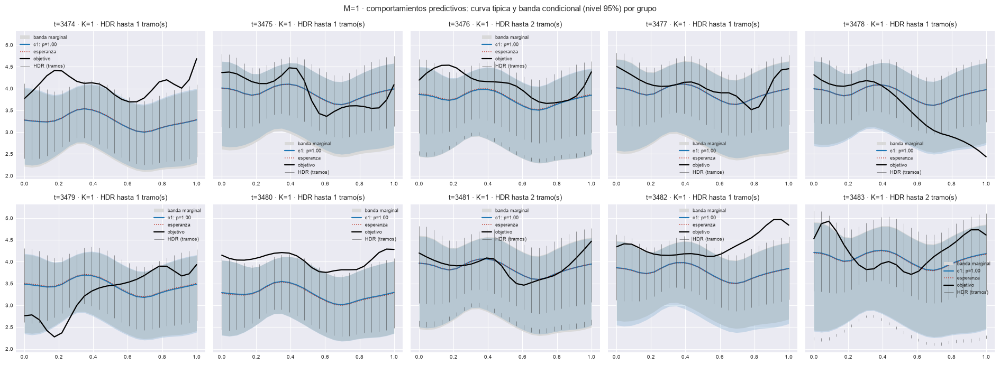

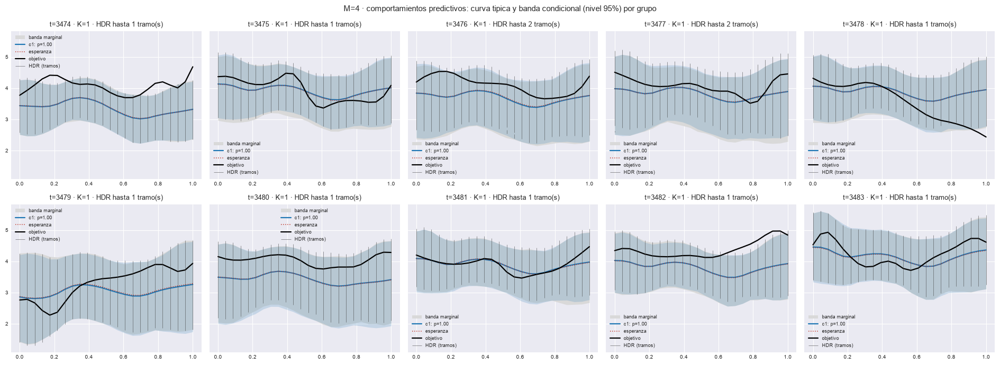

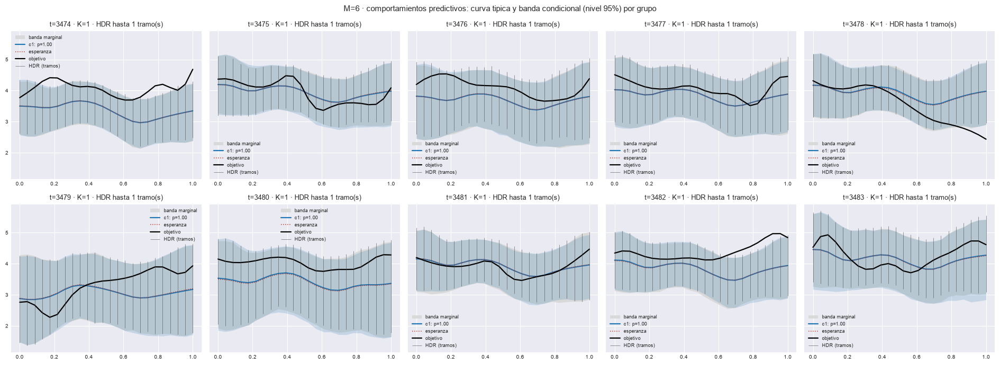

In [29]:
ESTILO_INT = {"equicolas": "#2c7fb8", "simultanea": "#8856a7", "hdr": "#2ca25f"}


def figura_origen(e, i, M, save_path):
    # Un origen: objetivo, los predictores, equi-colas, simultánea, tramos de la HDR y curvas típicas.
    C, (Ls, Us), (Lh, Uh) = e["COMP"], e["INTERVALOS"]["simultanea"], e["INTERVALOS"]["hdr"]
    fig, ax = plt.subplots(figsize=(8.6, 4.6))
    ax.fill_between(grilla, Ls[i, :, 0], Us[i, :, 0], color=ESTILO_INT["simultanea"], alpha=0.12, lw=0,
                    label="banda simultánea")
    ax.fill_between(grilla, e["li_f"][i], e["ls_f"][i], color=ESTILO_INT["equicolas"], alpha=0.22, lw=0,
                    label="equi-colas")
    for k in range(Lh.shape[2]):
        ok = np.isfinite(Lh[i, :, k])
        ax.vlines(grilla[ok], Lh[i, ok, k], Uh[i, ok, k], color=ESTILO_INT["hdr"], lw=1.1, alpha=0.75,
                  label="HDR (tramos)" if k == 0 else None)
    for c in range(int(C["K"][i])):
        ax.plot(grilla, C["curvas"][i, c], color="0.3", lw=0.8 + 2.4 * C["masas"][i, c], ls=(0, (4, 2)),
                label=f"comportamiento {c + 1}: p = {C['masas'][i, c]:.2f}")
    for pr in PREDICTORES:
        ax.plot(grilla, e["X_PRED"][pr][i], label=pr, **ESTILOS_PREDICTORES.get(pr, {}))
    ax.plot(grilla, X_obj_ev[i], color="k", lw=2.0, label="observada (objetivo)")
    ax.set_title(f"M={M} · t={int(t_orig[i])} · K={int(C['K'][i])} · HDR hasta "
                 f"{int(e['hdr_tramos'][i].max())} tramo(s)", fontsize=10)
    ax.set_xlabel(r"$\tau$")
    ax.legend(fontsize=7, ncol=2, loc="best")
    fig.tight_layout()
    fig.savefig(str(save_path), dpi=150, bbox_inches="tight")
    return fig


for M in (m for m in M_DETALLE if m in M_OK):
    e = EST[M]
    plot_comportamientos(e["COMP"], list(IDX_DET), X_obj_ev, e["li_f"], e["ls_f"], grilla, t_orig, M,
                         X_esp=e["X_pred"], hdr=e["INTERVALOS"]["hdr"], ncols=5,
                         save_path=e["paths"]["out_report"] / "63_comportamientos_ejemplos.png")
    plt.show()
    for i in IDX_DET:
        figura_origen(e, i, M, e["paths"]["out_report"] / f"63_detalle_t{int(t_orig[i])}.png")
        plt.close()

### 12.3 Catálogo global

Las mismas reglas sobre los centroides de la ventana, ponderados por masa.

M= 1: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 2: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 3: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 4: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 5: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 6: catalogo global con L=1 comportamiento(s), masas [1.0]


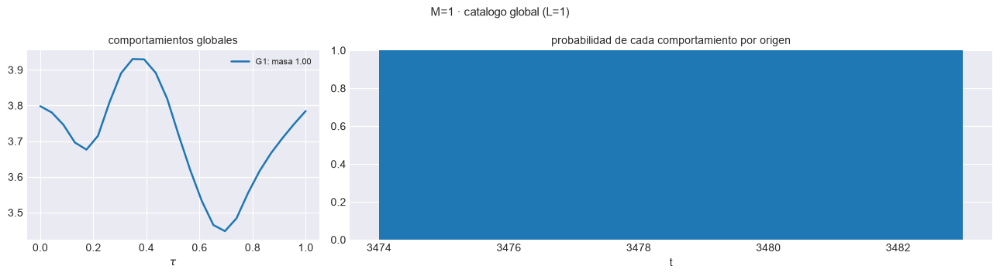

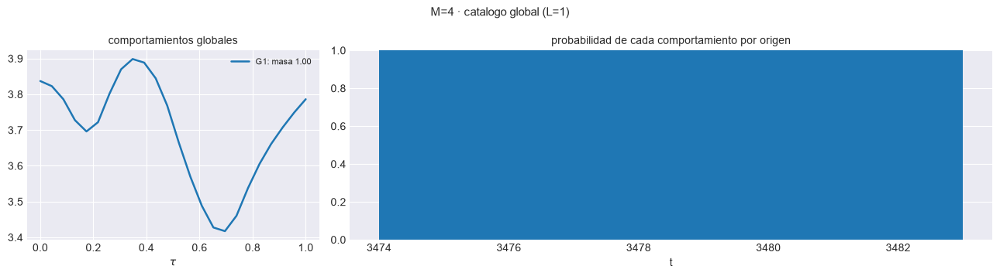

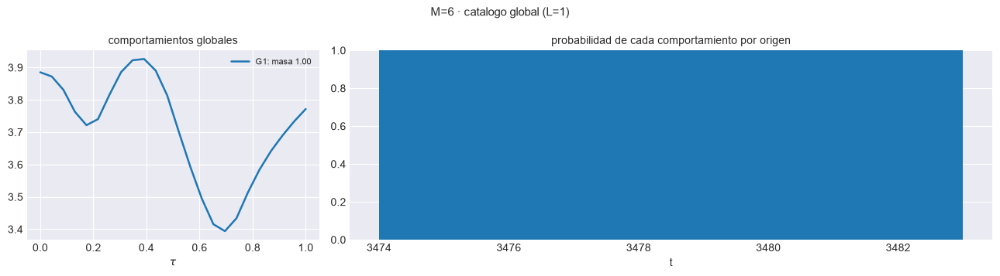

In [30]:
# catalogo_barrido sólo usa es_train para la máscara: la ventana de detalle hace de 'test'.
ORIG_DET = {**ORIG, "es_train": ~MASK_DET}
CAT_BAR = catalogo_barrido(EST, M_OK, ORIG_DET, PATH_BARRIDO)
for M in (m for m in M_DETALLE if m in M_OK):
    plot_catalogo(EST[M]["CATALOGO"], grilla, t_orig, M,
                  save_path=EST[M]["paths"]["out_report"] / "64_catalogo_global.png")
    plt.show()

### 12.4 Comportamientos contra el calendario y los episodios

No hay régimen verdadero. La referencia externa son los **episodios** (el día predicho supera la norma diaria de PM2.5) y el calendario (día de la semana y mes: los episodios son de invierno, mayo-agosto). Sobre toda la serie de prueba, la tabla cruzada de $K$ con el día de la semana, con el mes y con el episodio del día predicho (`65_comportamientos_calendario.csv` por $M$, `104_comportamientos_calendario_por_M.csv` en el barrido) y, para los orígenes con $K \ge 2$, cuántos caen en día de episodio o en el día siguiente a uno: si el modelo separa comportamientos, debería hacerlo en invierno, cuando la ventilación de la cuenca decide si el episodio sigue o se corta. Al final, la misma lectura sobre la ventana de detalle, como cuentas.


In [31]:
DIAS_ORDEN = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
AYER = f"ayer_{NOMBRE_EVENTO}"
filas = []
for M in M_OK:
    K = EST[M]["COMP"]["K"].astype(int)
    df = pd.DataFrame({"M": M, "t": t_orig, "bloque": np.where(es_train, "train", "test"), "K": K,
                       **{k: v for k, v in VERDAD_DET.items()}})
    df[NOMBRE_EVENTO], df[AYER] = df[NOMBRE_EVENTO].astype(bool), df[AYER].astype(bool)
    df.drop(columns="M").to_csv(EST[M]["paths"]["out_report"] / "65_comportamientos_calendario.csv", index=False)
    filas.append(df)
    te = df[df.bloque == "test"]
    cruz = pd.crosstab(te["dia_semana"], te["K"]).reindex(DIAS_ORDEN).fillna(0).astype(int)
    display(cruz.style.set_caption(f"M={M} · TEST · orígenes por día de la semana del día predicho y K (cuentas)"))
    display(pd.crosstab(te["mes"], te["K"]).style.set_caption(f"M={M} · TEST · orígenes por mes del día predicho y K (cuentas)"))
    display(pd.crosstab([te[NOMBRE_EVENTO], te[AYER]], te["K"])
            .style.set_caption(f"M={M} · TEST · orígenes por {NOMBRE_EVENTO} del día predicho y del anterior, y K (cuentas)"))
    k2 = te[te.K >= 2]
    print(f"M={M}: K >= 2 en {len(k2)} de {len(te)} orígenes de test · de ellos, día predicho con {NOMBRE_EVENTO} "
          f"{int(k2[NOMBRE_EVENTO].sum())} y día anterior con {NOMBRE_EVENTO} {int(k2[AYER].sum())} · "
          f"base en test: {te[NOMBRE_EVENTO].mean():.0%} de los días predichos tienen {NOMBRE_EVENTO}")
CAL = pd.concat(filas, ignore_index=True)
CAL.to_csv(PATH_BARRIDO / "104_comportamientos_calendario_por_M.csv", index=False)
display(CAL[CAL.t.isin(T_DET)].set_index(["M", "t"])[["fecha", "dia_semana", "mes", NOMBRE_MEDIDA, NOMBRE_EVENTO, AYER, "K"]]
        .style.format({NOMBRE_MEDIDA: "{:.1f}"})
        .set_caption(f"Ventana de detalle (t={T0_DET}..{T0_DET + N_DETALLE - 1}): calendario, {NOMBRE_EVENTO} y K por origen (descriptivo)"))


K,1
dia_semana,
Mon,157
Tue,157
Wed,157
Thu,156
Fri,156
Sat,156
Sun,157


K,1
mes,
1,93
2,85
3,93
4,90
5,93
6,90
7,93
8,93
9,90


M=1: K >= 2 en 0 de 1096 orígenes de test · de ellos, día predicho con episodio 0 y día anterior con episodio 0 · base en test: 6% de los días predichos tienen episodio


K,1
dia_semana,
Mon,157
Tue,157
Wed,157
Thu,156
Fri,156
Sat,156
Sun,157


K,1
mes,
1,93
2,85
3,93
4,90
5,93
6,90
7,93
8,93
9,90


...

K,1,2
mes,,
1,93,0
2,85,0
3,93,0
4,90,0
5,92,1
6,88,2
7,93,0
8,93,0
9,90,0


M=5: K >= 2 en 3 de 1096 orígenes de test · de ellos, día predicho con episodio 2 y día anterior con episodio 2 · base en test: 6% de los días predichos tienen episodio


K,1,2
dia_semana,,
Mon,156,1
Tue,157,0
Wed,157,0
Thu,156,0
Fri,156,0
Sat,156,0
Sun,157,0


K,1,2
mes,,
1,93,0
2,85,0
3,93,0
4,90,0
5,93,0
6,89,1
7,93,0
8,93,0
9,90,0


M=6: K >= 2 en 1 de 1096 orígenes de test · de ellos, día predicho con episodio 0 y día anterior con episodio 1 · base en test: 6% de los días predichos tienen episodio


### 12.5 Ventana de detalle, origen por origen

`112_ventana_detalle_por_origen.csv`: $K$ y masas, tramos de la HDR, longitud y cobertura de cada intervalo, calendario (fecha, día de la semana, mes), episodio del día predicho y del anterior, y error de cada predictor.

In [32]:
wn, filas = pesos_normalizados(grilla, PESOS_TAU), []
for M in M_OK:
    e, C = EST[M], EST[M]["COMP"]
    nm = {pr: normas_error_por_origen(X_obj_ev[IDX_DET], e["X_PRED"][pr][IDX_DET], grilla,
                                      pesos_tau=PESOS_TAU, verificar=False) for pr in PREDICTORES}
    for j, i in enumerate(IDX_DET):
        fila = {"M": M, "t": int(t_orig[i]), "K": int(C["K"][i]),
                **{f"p_{c + 1}": float(C["masas"][i, c]) for c in range(int(C["K"][i]))},
                "hdr_tramos_max": int(e["hdr_tramos"][i].max())}
        for nombre, (L, U) in e["INTERVALOS"].items():
            fila[f"long_{nombre}"] = float(ancho_tramos(L[i], U[i]) @ wn)
            fila[f"cob_{nombre}"] = float(cobertura_tramos(X_obj_ev[i], L[i], U[i]).mean())
        for pr in PREDICTORES:
            fila[f"mae_{pr}"], fila[f"rmse_{pr}"] = float(nm[pr]["l1"][j]), float(nm[pr]["l2"][j])
        fila.update({k: v[i] for k, v in VERDAD_DET.items()})
        filas.append(fila)
DETALLE = pd.DataFrame(filas)
cols_p = sorted([c for c in DETALLE.columns if c.startswith("p_")], key=lambda c: int(c[2:]))
DETALLE = DETALLE[["M", "t", "K"] + cols_p + [c for c in DETALLE.columns if c not in ["M", "t", "K"] + cols_p]]
DETALLE.to_csv(PATH_BARRIDO / "112_ventana_detalle_por_origen.csv", index=False)
for M in (m for m in M_DETALLE if m in M_OK):
    display(DETALLE[DETALLE.M == M].drop(columns="M").set_index("t").style.format(precision=3)
            .set_caption(f"M={M} · ventana de detalle origen por origen (112_ventana_detalle_por_origen.csv)"))

,K,p_1,hdr_tramos_max,long_equicolas,cob_equicolas,long_simultanea,cob_simultanea,long_hdr,cob_hdr,mae_esperanza,rmse_esperanza,mae_mediana,rmse_mediana,mae_medoide,rmse_medoide,mae_modal,rmse_modal,fecha,dia_semana,mes,pm25_media,episodio,ayer_episodio
t,,,,,,,,,,,,,,,,,,,,,,,
3474,1,1.000,1,1.541,0.208,1.519,0.458,1.491,0.458,0.811,0.837,0.804,0.831,0.804,0.831,0.760,0.788,2024-07-05,Fri,7,59.667,1,0
3475,1,1.000,1,1.744,1.000,1.566,1.000,1.449,1.000,0.253,0.276,0.252,0.277,0.252,0.277,0.254,0.297,2024-07-06,Sat,7,54.167,1,1
3476,1,1.000,2,1.775,0.792,2.076,1.000,1.553,0.875,0.312,0.388,0.259,0.333,0.259,0.334,0.207,0.277,2024-07-07,Sun,7,61.958,1,1
3477,1,1.000,1,1.866,1.000,1.584,1.000,1.431,1.000,0.191,0.239,0.160,0.203,0.160,0.203,0.150,0.184,2024-07-08,Mon,7,59.083,1,1
3478,1,1.000,1,1.640,0.917,1.393,0.708,1.312,0.708,0.466,0.621,0.485,0.660,0.485,0.660,0.516,0.720,2024-07-09,Tue,7,40.597,0,1
3479,1,1.000,1,1.551,0.792,1.539,0.792,1.472,0.792,0.526,0.613,0.527,0.622,0.527,0.622,0.530,0.636,2024-07-10,Wed,7,29.292,0,0
3480,1,1.000,1,1.485,0.083,1.464,0.458,1.440,0.375,0.771,0.780,0.739,0.747,0.739,0.747,0.721,0.730,2024-07-11,Thu,7,56.167,1,0
3481,1,1.000,2,1.857,1.000,1.901,1.000,1.634,1.000,0.116,0.160,0.126,0.163,0.126,0.163,0.168,0.200,2024-07-12,Fri,7,50.042,1,1
3482,1,1.000,1,1.583,0.500,1.429,0.667,1.301,0.625,0.620,0.699,0.540,0.627,0.540,0.627,0.460,0.557,2024-07-13,Sat,7,82.625,1,1


,K,p_1,hdr_tramos_max,long_equicolas,cob_equicolas,long_simultanea,cob_simultanea,long_hdr,cob_hdr,mae_esperanza,rmse_esperanza,mae_mediana,rmse_mediana,mae_medoide,rmse_medoide,mae_modal,rmse_modal,fecha,dia_semana,mes,pm25_media,episodio,ayer_episodio
t,,,,,,,,,,,,,,,,,,,,,,,
3474,1,1.000,1,1.537,0.542,2.075,0.875,1.541,0.542,0.712,0.749,0.717,0.754,0.698,0.733,0.727,0.772,2024-07-05,Fri,7,59.667,1,0
3475,1,1.000,1,1.803,1.000,2.433,1.000,1.798,1.000,0.226,0.248,0.241,0.261,0.242,0.259,0.308,0.330,2024-07-06,Sat,7,54.167,1,1
3476,1,1.000,2,2.074,0.958,2.938,1.000,2.037,1.000,0.391,0.443,0.362,0.425,0.359,0.412,0.277,0.352,2024-07-07,Sun,7,61.958,1,1
3477,1,1.000,2,2.141,1.000,2.810,1.000,2.062,1.000,0.247,0.286,0.215,0.257,0.245,0.274,0.163,0.214,2024-07-08,Mon,7,59.083,1,1
3478,1,1.000,1,1.781,0.917,2.351,0.958,1.745,0.792,0.433,0.598,0.439,0.611,0.462,0.608,0.524,0.723,2024-07-09,Tue,7,40.597,0,1
3479,1,1.000,1,2.402,1.000,3.118,1.000,2.419,1.000,0.448,0.515,0.424,0.487,0.443,0.519,0.291,0.345,2024-07-10,Wed,7,29.292,0,0
3480,1,1.000,1,2.193,1.000,2.976,1.000,2.165,1.000,0.599,0.612,0.533,0.551,0.563,0.574,0.381,0.419,2024-07-11,Thu,7,56.167,1,0
3481,1,1.000,1,1.724,1.000,2.354,1.000,1.681,1.000,0.091,0.144,0.106,0.145,0.098,0.135,0.132,0.168,2024-07-12,Fri,7,50.042,1,1
3482,1,1.000,1,1.668,0.667,2.302,1.000,1.638,0.667,0.585,0.666,0.557,0.638,0.522,0.618,0.523,0.572,2024-07-13,Sat,7,82.625,1,1


,K,p_1,hdr_tramos_max,long_equicolas,cob_equicolas,long_simultanea,cob_simultanea,long_hdr,cob_hdr,mae_esperanza,rmse_esperanza,mae_mediana,rmse_mediana,mae_medoide,rmse_medoide,mae_modal,rmse_modal,fecha,dia_semana,mes,pm25_media,episodio,ayer_episodio
t,,,,,,,,,,,,,,,,,,,,,,,
3474,1,1.000,1,1.529,0.542,2.126,0.917,1.529,0.583,0.718,0.756,0.715,0.752,0.708,0.753,0.707,0.745,2024-07-05,Fri,7,59.667,1,0
3475,1,1.000,1,1.603,1.000,2.290,1.000,1.610,1.000,0.199,0.223,0.210,0.235,0.179,0.229,0.230,0.265,2024-07-06,Sat,7,54.167,1,1
3476,1,1.000,1,2.115,1.000,2.736,1.000,2.064,1.000,0.407,0.461,0.370,0.432,0.360,0.411,0.321,0.397,2024-07-07,Sun,7,61.958,1,1
3477,1,1.000,1,1.884,1.000,2.554,1.000,1.874,1.000,0.235,0.277,0.215,0.258,0.224,0.295,0.254,0.298,2024-07-08,Mon,7,59.083,1,1
3478,1,1.000,1,1.660,0.833,2.340,0.958,1.655,0.750,0.412,0.588,0.435,0.608,0.461,0.659,0.465,0.651,2024-07-09,Tue,7,40.597,0,1
3479,1,1.000,1,2.379,1.000,3.159,1.000,2.389,1.000,0.483,0.557,0.486,0.555,0.470,0.572,0.495,0.558,2024-07-10,Wed,7,29.292,0,0
3480,1,1.000,1,2.410,1.000,3.347,1.000,2.411,1.000,0.631,0.645,0.554,0.569,0.576,0.594,0.353,0.403,2024-07-11,Thu,7,56.167,1,0
3481,1,1.000,1,1.688,1.000,2.395,1.000,1.678,1.000,0.110,0.153,0.128,0.163,0.125,0.154,0.158,0.179,2024-07-12,Fri,7,50.042,1,1
3482,1,1.000,1,1.627,0.667,2.297,1.000,1.613,0.708,0.549,0.643,0.526,0.619,0.561,0.645,0.459,0.545,2024-07-13,Sat,7,82.625,1,1
